# Other results: the variants that did not help

The models of the negative-results appendix, each against the model it modifies (M6, D4 or F, in
03_models.ipynb): a deeper network, a turn-size latent, a slower drift and fixed drift strengths, the dots'
jump phase as an input, and a lower floor on the range input.

In [1]:
import pandas as pd
from twin import registry, tables, training, unit_eval
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

In [2]:
MODELS = ['M6, 3 layers', 'D4, 3 layers', 'F, 3 layers', 'M6, turn size', 'D4, turn size', 'F, turn size', 'D4, tau 200', 'F, tau 200', 'D4, tau 200 + turn size', 'F, tau 200 + turn size', 'D4, strength 0', 'D4, tau 70, half', 'D4, tau 70, full', 'D4, tau 200, half', 'D4, tau 200, full', 'F on D4 at strength 0', 'M6, jump phase', 'D4, jump phase', 'F, jump phase', 'M6, floor 2 px', 'D4, floor 2 px', 'F, floor 2 px']

## Training and evaluation

`TRAIN = True` retrains every unit below (about 60 CPU-hours), `EVALUATE = True` re-runs every evaluation (about 15 min per
unit); both write to `output/`. Evaluation is deterministic, so re-evaluating reproduces the saved numbers exactly.

In [3]:
TRAIN, EVALUATE = False, False
UNITS = [(name, seed) for name in MODELS for seed in (0, 101) if (name, seed) in registry.BY_NAME]
for name, seed in UNITS:
    if TRAIN:
        training.make_unit(name, seed)
    if EVALUATE:
        unit_eval.evaluate(registry.BY_NAME[(name, seed)])
pd.DataFrame([dict(model=n, seed=s, key=registry.BY_NAME[(n, s)], made=registry.unit(n, s)["make"],
                   arm=registry.arm(registry.unit(n, s))) for n, s in UNITS]).set_index(["model", "seed"])

key      made                                                arm
model                   seed                                                                  
M6, 3 layers            0     36a     train                    S4x_adt_z2_cdt_tr_rc_al_w3ft_d3
                        101   36b     train                    S4x_adt_z2_cdt_tr_rc_al_w3ft_d3
D4, 3 layers            0     36c     train            S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3
                        101   36d     train            S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3
F, 3 layers             0     36e   correct  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr...
                        101   36f   correct  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr...
M6, turn size           0     38a     train                    S4x_adt_z2_cdt_tr_rc_al_w3ft_tz
                        101   38b     train                    S4x_adt_z2_cdt_tr_rc_al_w3ft_tz
D4, turn size           0     38c     train            S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz
                        101   38d     train            S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz
F, turn size            0     38e   correct  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr...
                        101   38f   correct  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr...
D4, tau 200             0     37a     train          S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200
                        101   37b     train          S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200
F, tau 200              0     37c   correct  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5B...
                        101   37d   correct  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5B...
D4, tau 200 + turn size 0     46a     train       S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz
                        101   46b     train       S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz
F, tau 200 + turn size  0     46c   correct  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_p...
                        101   46d   correct  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_p...
D4, strength 0          0     47a  driftfix               S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
                        101   47f  driftfix               S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
D4, tau 70, half        0     47b  driftfix               S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
                        101   47g  driftfix               S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
D4, tau 70, full        0     47c  driftfix               S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
                        101   47h  driftfix               S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
D4, tau 200, half       0     47d  driftfix          S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200
                        101   47i  driftfix          S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200
D4, tau 200, full       0     47e  driftfix          S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200
                        101   47j  driftfix          S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200
F on D4 at strength 0   0     48a   correct   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last
                        101   48b   correct   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last
M6, jump phase          0     41a     train                    S4x_adt_z2_cdt_tr_rc_al_w3ft_jp
                        101   41b     train                    S4x_adt_z2_cdt_tr_rc_al_w3ft_jp
D4, jump phase          0     41c     train            S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp
                        101   41d     train            S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp
F, jump phase           0     41e   correct  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr...
                        101   41f   correct  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr...
M6, floor 2 px          0     42a     train                     S4xlo_adt_z2_cdt_tr_rc_al_w3ft
                        101   42b     train                     S4xlo_adt_z2_cdt_tr_rc_al_w3ft
D4, floor 2 px          0     42c     tr

## A deeper network and a turn-size latent (Table tab:app-negres-net)
Seed 0 | seed 101.

In [4]:
tables.paired_table(*tables.NEGRES_NET, half_up=False)

,AUC,AUC no-rad,dip,grading,moving error,turn spread
M6,0.671 | 0.645,0.599 | 0.575,3.77 | 3.07,4.76 | 4.07,0.90 | 1.00,0.71 | 0.83
"M6, 3 layers",0.720 | 0.668,0.647 | 0.577,2.97 | 3.23,5.15 | 4.58,0.99 | 0.97,0.67 | 0.71
"M6, turn size",0.667 | 0.673,0.603 | 0.599,3.34 | 2.82,4.37 | 4.55,1.02 | 1.14,0.77 | 0.67
D4,0.634 | 0.628,0.559 | 0.538,2.89 | 2.95,4.12 | 4.08,1.14 | 1.35,0.70 | 0.84
"D4, 3 layers",0.742 | 0.728,0.695 | 0.683,3.02 | 2.88,5.46 | 7.36,1.15 | 0.89,0.48 | 0.90
"D4, turn size",0.711 | 0.637,0.634 | 0.543,3.14 | 3.14,5.30 | 4.18,1.19 | 1.11,1.16 | 0.88
F,0.641 | 0.643,0.561 | 0.555,3.73 | 3.49,5.92 | 5.69,0.82 | 0.85,0.70 | 0.83
"F, 3 layers",0.741 | 0.728,0.702 | 0.682,3.36 | 3.02,5.33 | 5.97,0.97 | 0.97,0.48 | 0.93
"F, turn size",0.706 | 0.645,0.636 | 0.544,3.62 | 4.20,6.48 | 4.11,0.98 | 0.95,1.13 | 0.87


## Slow-state variants of D4 and F (Table tab:app-negres-drift)
The window correlations are the lag-1 correlations of successive 60-bout window means (real 0.36 interval,
0.24 displacement).

In [5]:
tables.paired_table(*tables.NEGRES_DRIFT)

,AUC,AUC no-rad,dip,moving error,static error,window corr. interval,window corr. displ.,within displ.
D4,0.634 | 0.628,0.559 | 0.538,2.89 | 2.95,1.14 | 1.35,1.05 | 1.00,0.31 | 0.34,0.29 | 0.27,0.92 | 1.11
"D4, tau 200",0.659 | 0.565,0.610 | 0.483,3.36 | 3.10,1.05 | 1.41,0.77 | 0.93,0.33 | 0.32,0.25 | 0.17,0.80 | 0.79
"D4, tau 200 + turn size",0.685 | 0.591,0.609 | 0.499,3.63 | 3.31,1.08 | 0.92,0.91 | 0.86,0.34 | 0.33,0.18 | 0.24,0.85 | 0.88
"D4, strength 0",0.596 | 0.597,0.531 | 0.524,2.98 | 3.19,1.04 | 1.46,1.02 | 0.89,-0.01 | -0.02,0.05 | 0.05,0.63 | 0.69
"D4, tau 70, half",0.615 | 0.595,0.540 | 0.518,2.89 | 3.02,1.08 | 1.44,1.01 | 0.96,0.16 | 0.15,0.15 | 0.11,0.72 | 0.79
"D4, tau 70, full",0.649 | 0.621,0.567 | 0.526,2.84 | 2.82,1.06 | 1.25,1.08 | 0.91,0.34 | 0.34,0.27 | 0.26,0.93 | 1.02
"D4, tau 200, half",0.663 | 0.572,0.609 | 0.489,3.37 | 2.73,1.12 | 1.34,0.99 | 0.86,0.23 | 0.24,0.20 | 0.18,0.74 | 0.80
"D4, tau 200, full",0.690 | 0.595,0.622 | 0.499,3.11 | 3.09,1.09 | 1.51,0.92 | 0.94,0.48 | 0.48,0.39 | 0.36,0.97 | 1.00
F,0.641 | 0.643,0.561 | 0.555,3.73 | 3.49,0.82 | 0.85,0.88 | 0.96,0.32 | 0.35,0.29 | 0.26,0.92 | 1.11
"F, tau 200",0.668 | 0.579,0.605 | 0.496,4.20 | 3.81,0.86 | 1.00,1.16 | 0.89,0.33 | 0.33,0.26 | 0.17,0.79 | 0.82


## The jump-phase input and the lower range floor (Table tab:app-negres-other)

In [6]:
tables.paired_table(*tables.NEGRES_OTHER, half_up=False)

,lik. joint,lik. interval,AUC,dip,moving error
M6,13.385 | 13.387,1.215 | 1.222,0.671 | 0.645,3.77 | 3.07,0.90 | 1.00
"M6, jump phase",13.427 | 13.413,1.227 | 1.233,0.701 | 0.679,3.13 | 3.29,1.00 | 0.97
"M6, floor 2 px",13.376 | 13.379,1.214 | 1.218,0.671 | 0.655,3.65 | 3.08,0.90 | 0.93
D4,13.344 | 13.356,1.203 | 1.207,0.634 | 0.628,2.89 | 2.95,1.14 | 1.35
"D4, jump phase",13.353 | 13.354,1.206 | 1.231,0.666 | 0.732,2.61 | 2.84,1.33 | 1.35
"D4, floor 2 px",13.348 | 13.352,1.212 | 1.205,0.667 | 0.644,2.88 | 2.74,0.99 | 1.27
F,13.344 | 13.357,1.203 | 1.207,0.641 | 0.643,3.73 | 3.49,0.82 | 0.85
"F, jump phase",13.353 | 13.354,1.206 | 1.231,0.664 | 0.730,3.62 | 4.00,1.00 | 1.06
"F, floor 2 px",13.348 | 13.352,1.212 | 1.205,0.660 | 0.630,3.92 | 3.61,0.82 | 0.99


## Every model's measurements on held-out fish

The saved outputs of `unit_eval.evaluate`, the nine measurements of `unit_eval.CELLS` per unit; a unit with no saved evaluation is evaluated first.

### M6, 3 layers, seed 0


== held-out likelihood per head (bits per bout)
turn             7.654
displacement     4.512
interval         1.213
joint           13.380

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_d3'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_d3.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_d3.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_d3.csv  (15 rows) in 2496s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_rej
abs_dtheta_w1                                        8.2502
symbol_js                                            0.0106
dt

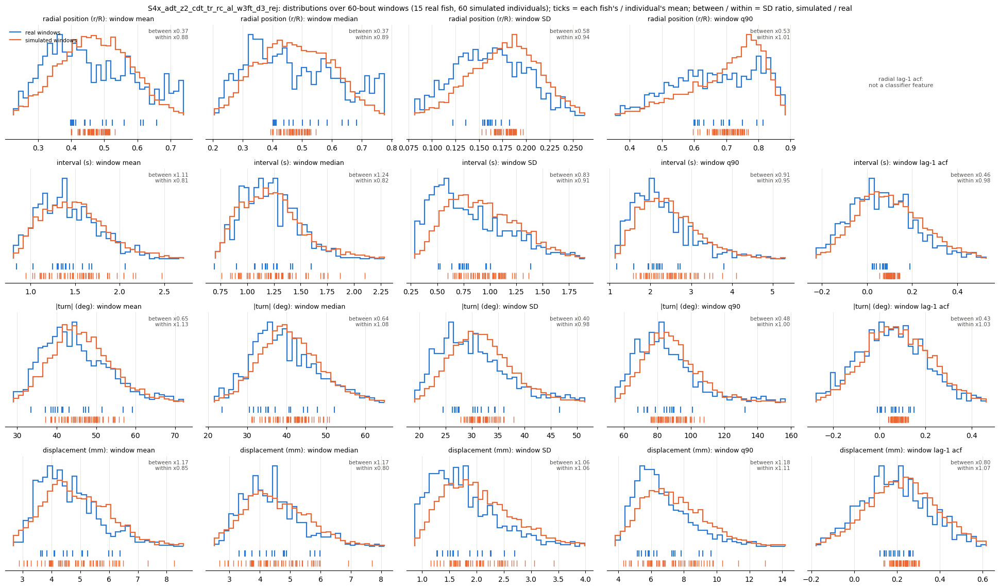


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_fold4.pt: 3 rollouts
dropped 12.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.47     1.00  0.15  0.14   3.0   3.0                  22.3 +/- 0.9  21.4 +/- 0.9
d2s3.5    1.90     1.57  2.64  1.38  11.0   7.0                  17.4 +/- 0.9  19.1 +/- 0.7
d4s3.5    1.55     0.95  4.68  2.62  19.0   9.0                  18.7 +/- 1.7  19.0 +/- 0.8
d6s3.5    1.85     1.45  4.62  2.97  13.0   9.0                  16.7 +/- 1.3  18.3 +/- 0.8
d8s3.5    1.98     1.89  4.97  2.29  11.0   9.0                  16.3 +/- 1.0  17.8 +/- 0.7
d1s0     

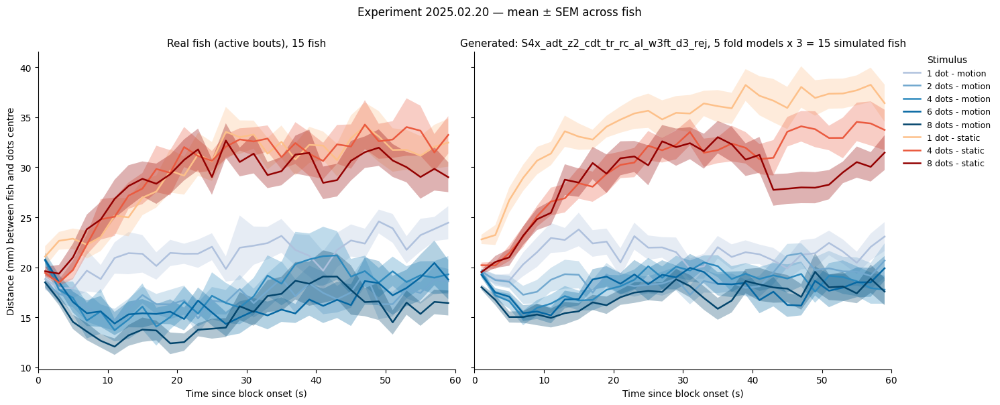


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

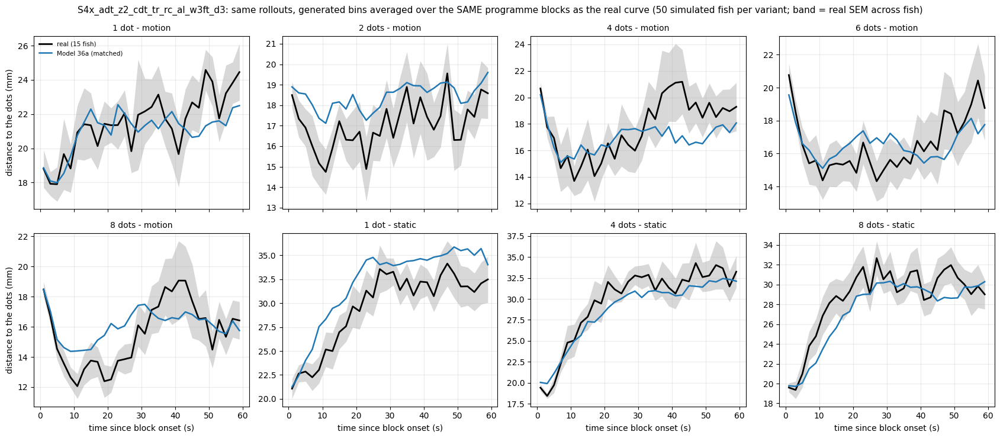


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_d3                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           22.18  23.39       1.21
d2s3.5       17.39  23.58       6.19                           18.64  23.20       4.56
d4s3.5       18.74  23.93       5.19                           17.75  23.29       5.54
d6s3.5       16.69  23.12       6.43                           17.17  23.28       6.10
d8s3.5       16.41  23.36       6.94                           17.26  23.32       6.06

== turn toward the moving dots by dot count
           real  S4x_adt_z

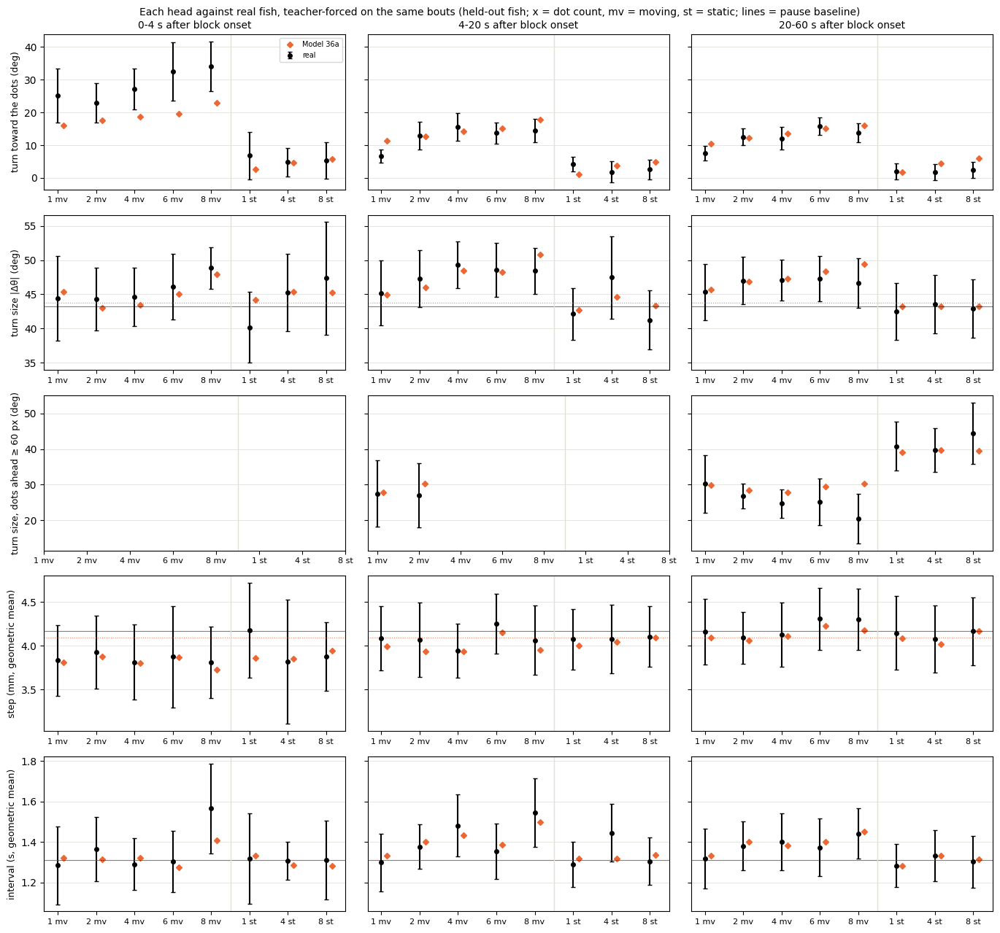

In [7]:
unit_eval.show('36a')

### M6, 3 layers, seed 101


== held-out likelihood per head (bits per bout)
turn             7.655
displacement     4.508
interval         1.239
joint           13.402

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_d3'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_d3.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_d3.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_d3.csv  (15 rows) in 2443s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_rej
abs_dtheta_w1                                        7.3954
symbol_js                                            0.0094
dt

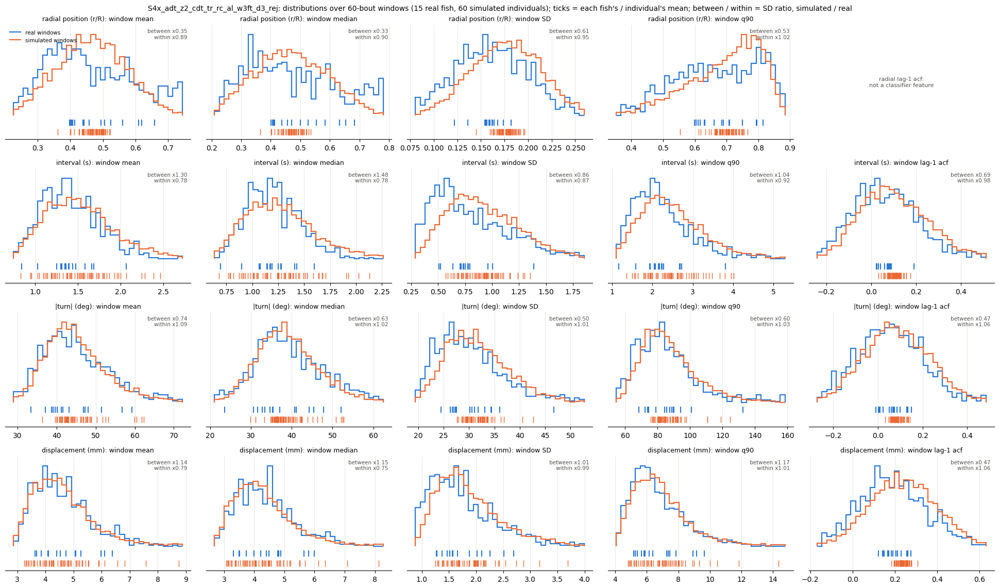


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_fold4.pt: 3 rollouts
dropped 11.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.48     1.03  0.15  0.04   3.0   5.0                  22.3 +/- 0.9  22.6 +/- 0.9
d2s3.5    1.80     1.38  2.64  2.99  11.0  11.0                  17.4 +/- 0.9  19.5 +/- 0.9
d4s3.5    1.56     0.94  4.68  2.62  19.0  11.0                  18.7 +/- 1.7  17.8 +/- 0.5
d6s3.5    1.11     0.77  4.62  3.62  13.0   9.0                  16.7 +/- 1.3  16.9 +/- 0.7
d8s3.5    1.60     1.42  4.97  2.47  11.0   9.0                  16.3 +/- 1.0  16.5 +/- 1.1
d1s0     

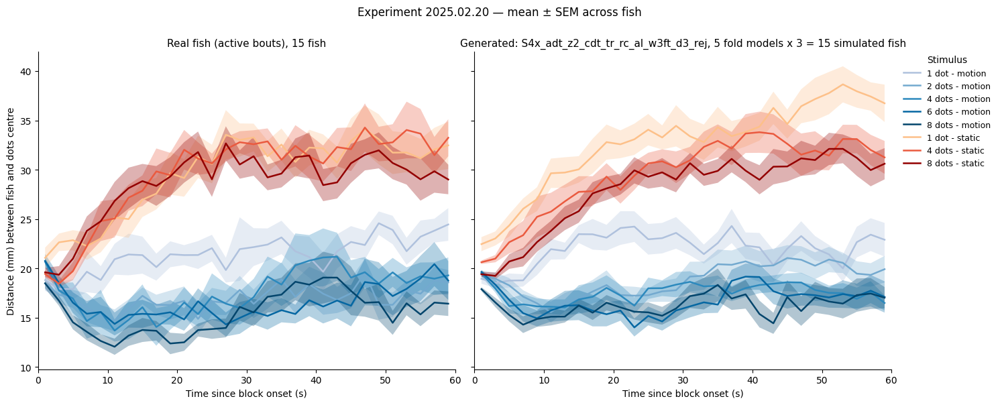


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

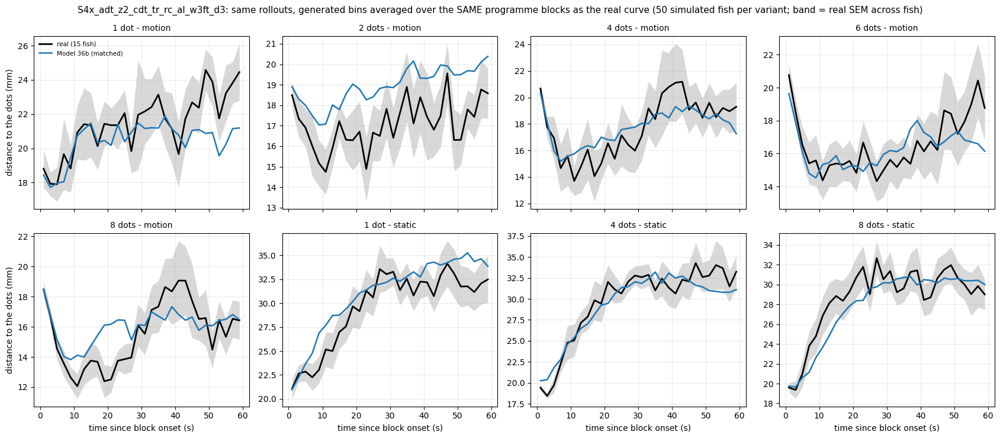


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_d3                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           21.65  22.99       1.34
d2s3.5       17.39  23.58       6.19                           20.00  22.82       2.82
d4s3.5       18.74  23.93       5.19                           19.09  23.23       4.15
d6s3.5       16.69  23.12       6.43                           17.24  23.22       5.98
d8s3.5       16.41  23.36       6.94                           17.01  22.92       5.90

== turn toward the moving dots by dot count
           real  S4x_adt_z

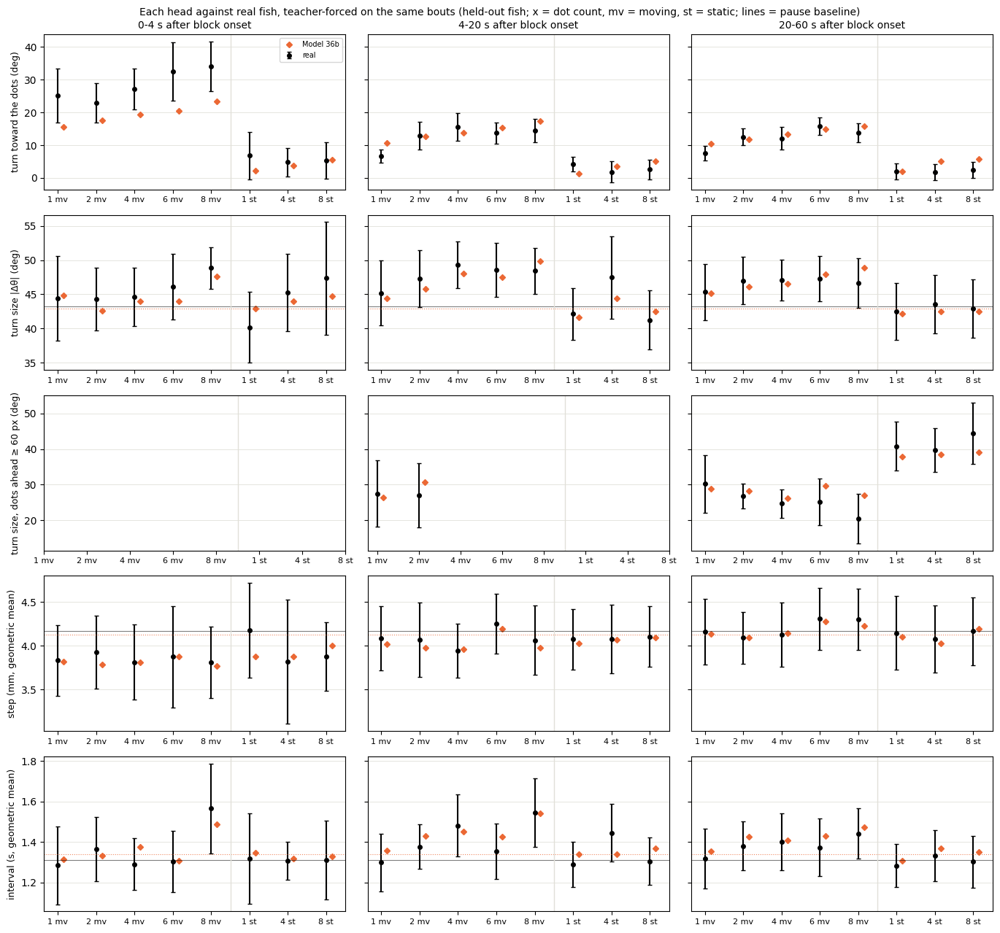

In [8]:
unit_eval.show('36b')

### D4, 3 layers, seed 0


== held-out likelihood per head (bits per bout)
turn             7.647
displacement     4.510
interval         1.204
joint           13.362

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3.csv  (15 rows) in 1296s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_rej
abs_dtheta_w1                                                6.9386
symbol_js     

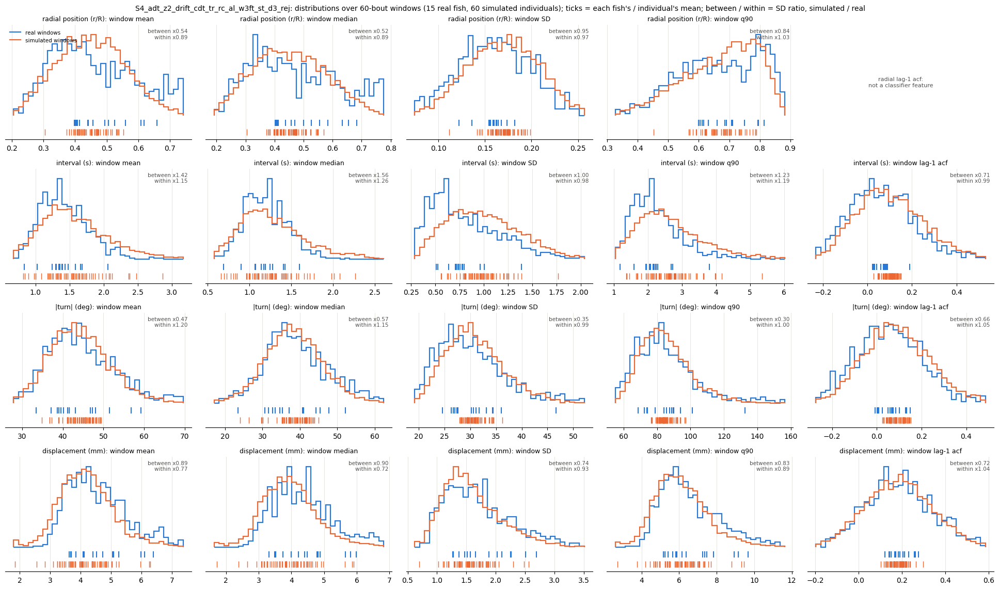


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_fold4.pt: 3 rollouts
dropped 12.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.36     1.58  0.15   0.3   3.0   3.0                  22.3 +/- 0.9  24.8 +/- 1.1
d2s3.5    3.19     2.51  2.64  0.37  11.0  15.0                  17.4 +/- 0.9  20.6 +/- 0.9
d4s3.5    1.38     0.80  4.68  3.96  19.0   7.0                  18.7 +/- 1.7  18.2 +/- 0.8
d6s3.5    1.54     1.16  4.62  3.57  13.0  11.0                  16.7 +/- 1.3  18.3 +/- 1.1
d8s3.5    1.83     1.68  4.97  3.25  11.0   7.0                  16.3 +/- 1.0  16.8 +/- 0.8
d

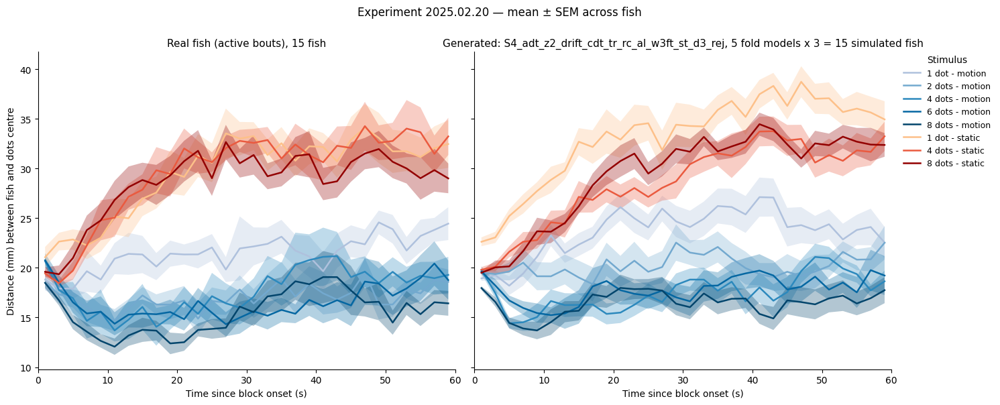


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

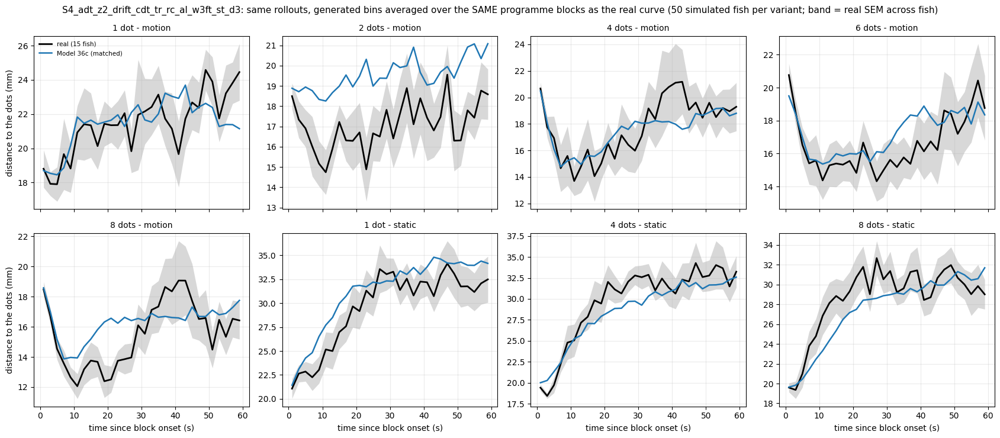


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3                  
           plateau   null attraction                                 plateau   null attraction
cond_label                                                                                    
d1s3.5       22.41  23.57       1.16                                   22.85  22.23      -0.61
d2s3.5       17.39  23.58       6.19                                   19.54  21.89       2.35
d4s3.5       18.74  23.93       5.19                                   18.27  22.00       3.73
d6s3.5       16.69  23.12       6.43                                   17.69  22.14       4.44
d8s3.5       16.41  23.36       6.94                                   16.52  21.95       5.43

== tur

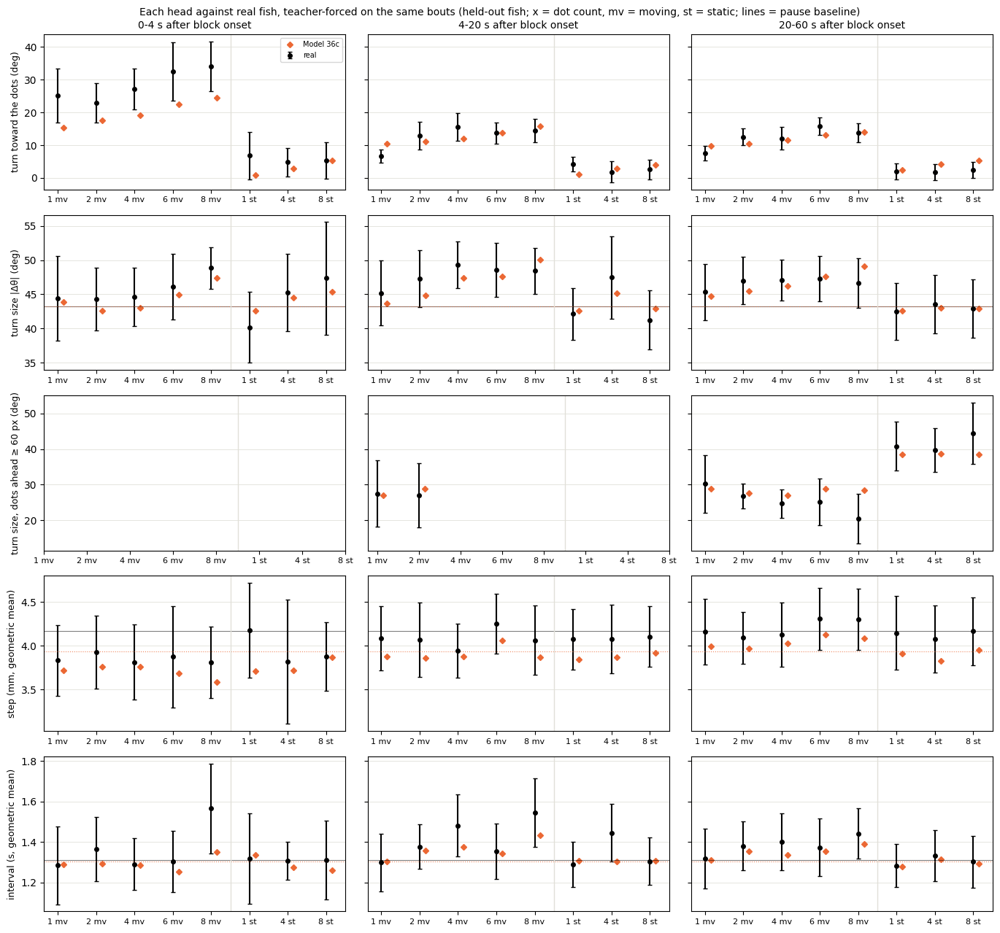

In [9]:
unit_eval.show('36c')

### D4, 3 layers, seed 101


== held-out likelihood per head (bits per bout)
turn             7.662
displacement     4.500
interval         1.198
joint           13.360

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3.csv  (15 rows) in 1284s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_rej
abs_dtheta_w1                                                9.0053
symbol_js     

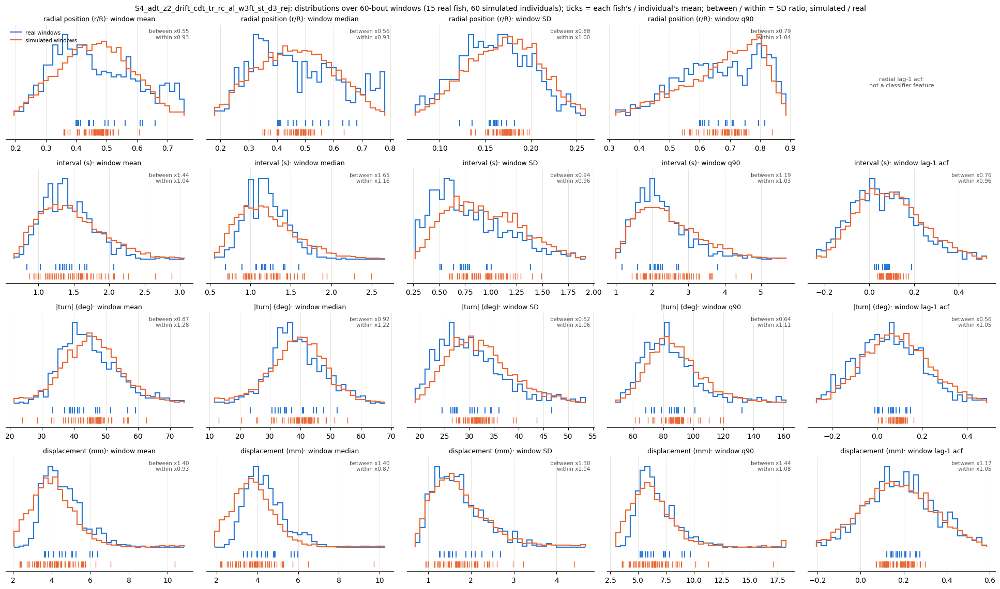


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_fold4.pt: 3 rollouts
dropped 13.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.65     1.12  0.15  0.09   3.0   5.0                  22.3 +/- 0.9  23.0 +/- 1.6
d2s3.5    2.57     2.04  2.64  1.39  11.0  11.0                  17.4 +/- 0.9  20.0 +/- 1.0
d4s3.5    1.27     0.80  4.68  2.98  19.0  11.0                  18.7 +/- 1.7  18.9 +/- 1.1
d6s3.5    1.50     1.13  4.62  2.74  13.0   7.0                  16.7 +/- 1.3  17.7 +/- 1.4
d8s3.5    2.08     1.78  4.97  2.15  11.0  11.0                  16.3 +/- 1.0  16.3 +/- 1.1
d

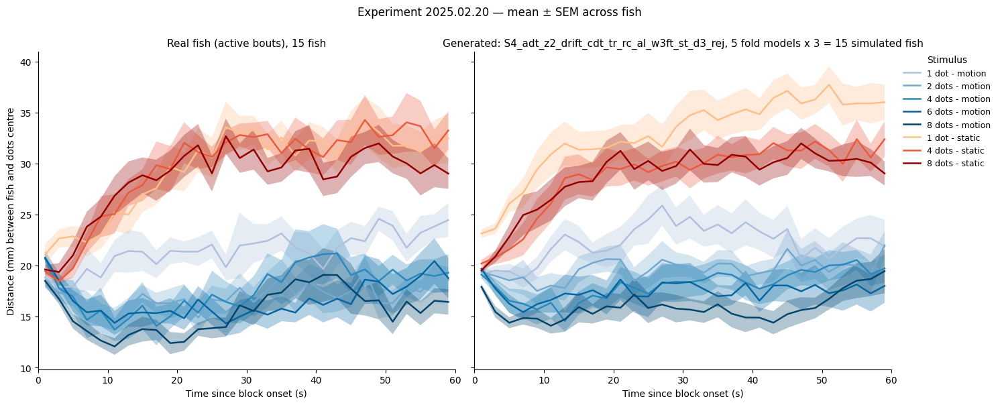


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

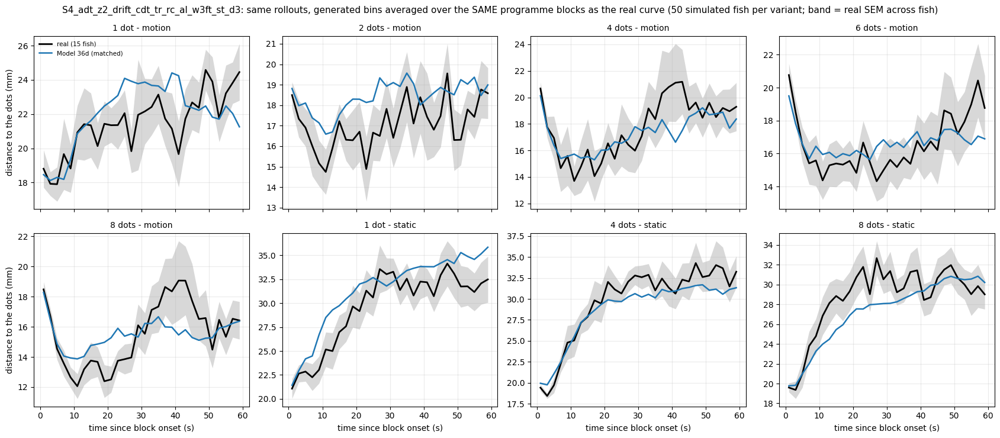


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3                  
           plateau   null attraction                                 plateau   null attraction
cond_label                                                                                    
d1s3.5       22.41  23.57       1.16                                   23.76  23.72      -0.04
d2s3.5       17.39  23.58       6.19                                   19.98  23.29       3.31
d4s3.5       18.74  23.93       5.19                                   19.02  23.32       4.30
d6s3.5       16.69  23.12       6.43                                   17.76  23.73       5.96
d8s3.5       16.41  23.36       6.94                                   16.45  23.60       7.15

== tur

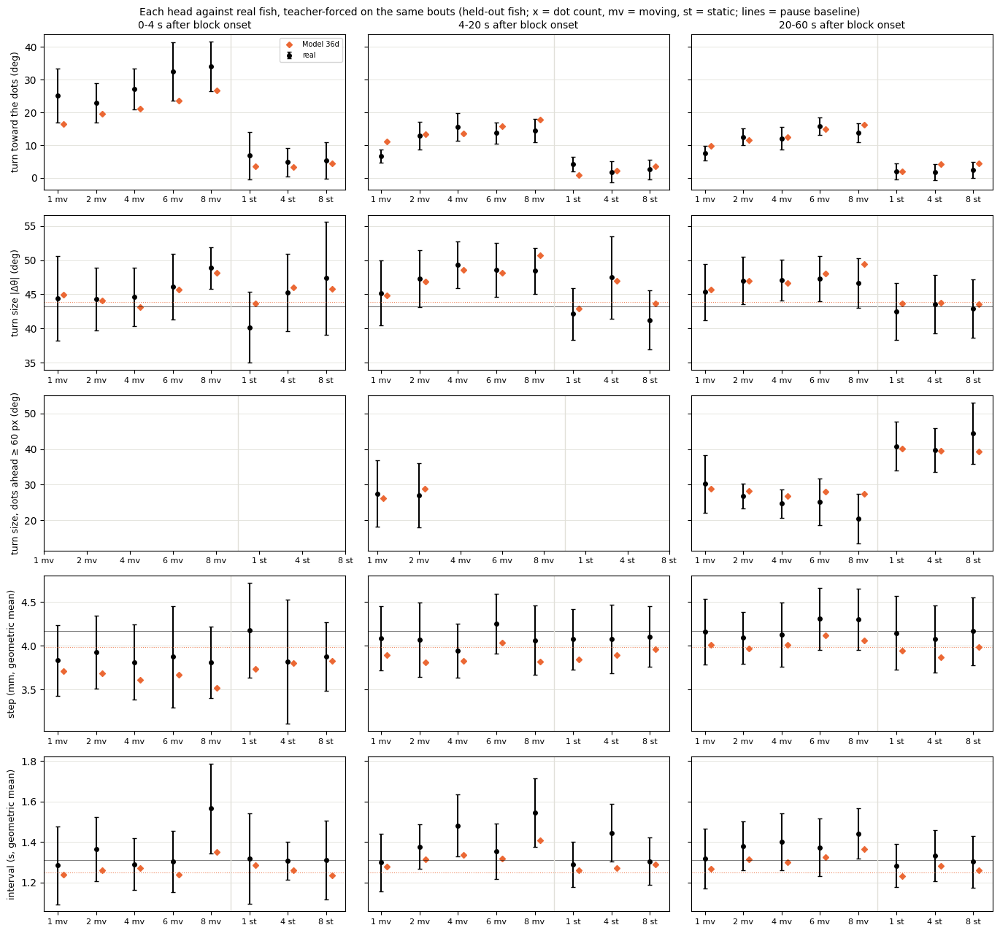

In [10]:
unit_eval.show('36d')

### F, 3 layers, seed 0


== held-out likelihood per head (bits per bout)
turn             7.647
displacement     4.510
interval         1.204
joint           13.362

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last.csv  (15 rows) in 358s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_rej
abs_dtheta_w1          

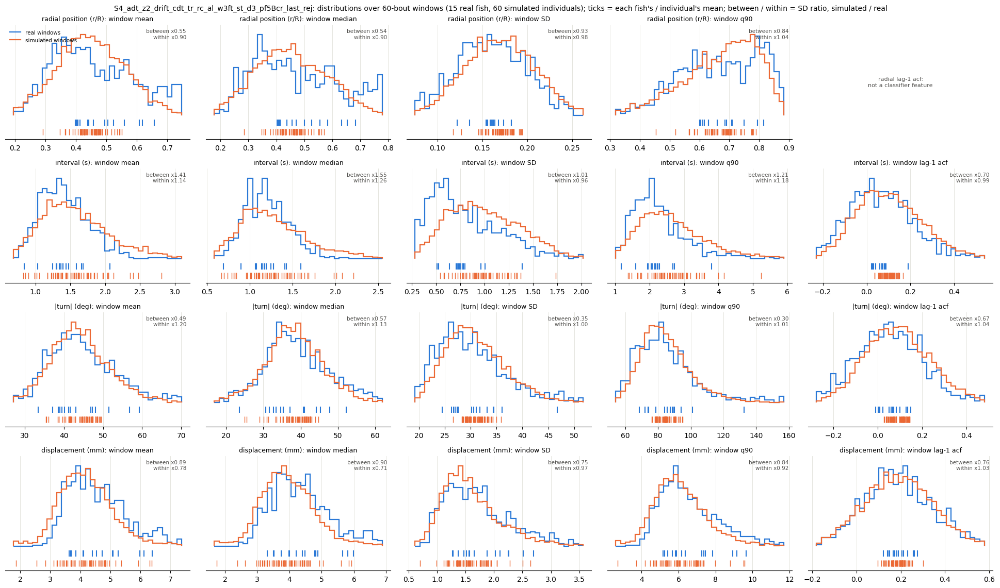


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 11.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.87     1.31  0.15  0.45   3.0   5.0                  22.3 +/- 0.9  22.2 +/- 0.8
d2s3.5    2.84     2.26  2.64   1.2  11.0  13.0                  17.4 +/- 0.9  20.3 +/- 1.1
d4s3.5    1.35     0.84  4.68  3.07  19.0   7.0                  18.7 +/- 1.7  18.8 +/- 0.7
d6s3.5    1.25     0.91  4.62  4.23  13.0   9.0                  16.7 +/- 1.3  17.2 +/- 1.0
d8s3.5    1.24     1.15  4.97  3.68  11.0  11.0                  16.3 +/- 1.0  17

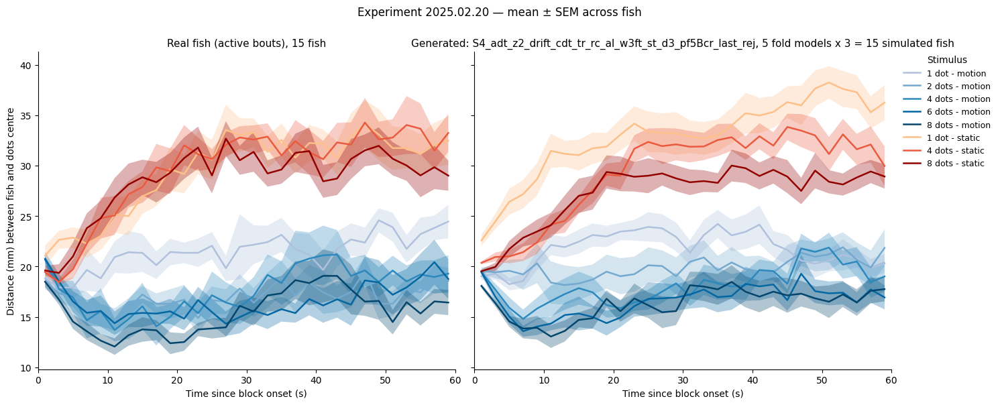


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

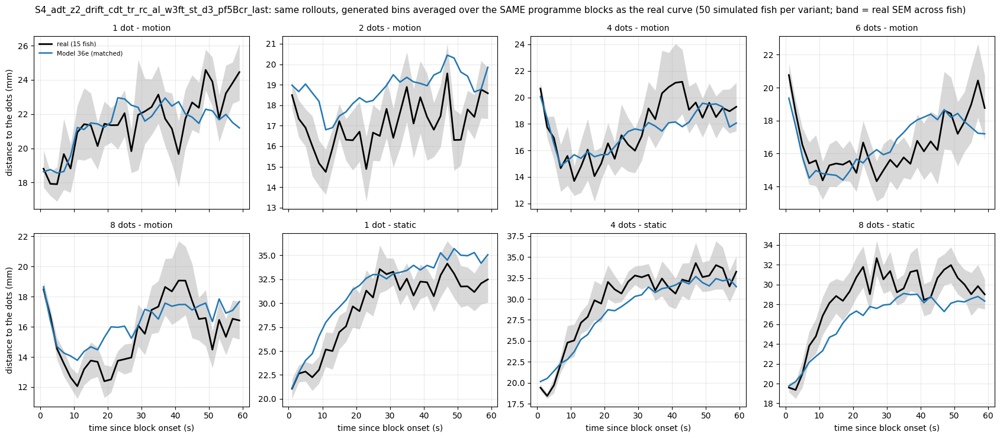


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last                  
           plateau   null attraction                                             plateau   null attraction
cond_label                                                                                                
d1s3.5       22.41  23.57       1.16                                               22.61  22.44      -0.17
d2s3.5       17.39  23.58       6.19                                               19.17  22.25       3.08
d4s3.5       18.74  23.93       5.19                                               18.25  22.51       4.26
d6s3.5       16.69  23.12       6.43                                               16.25  22.38       6.13
d8s3.5       16.41

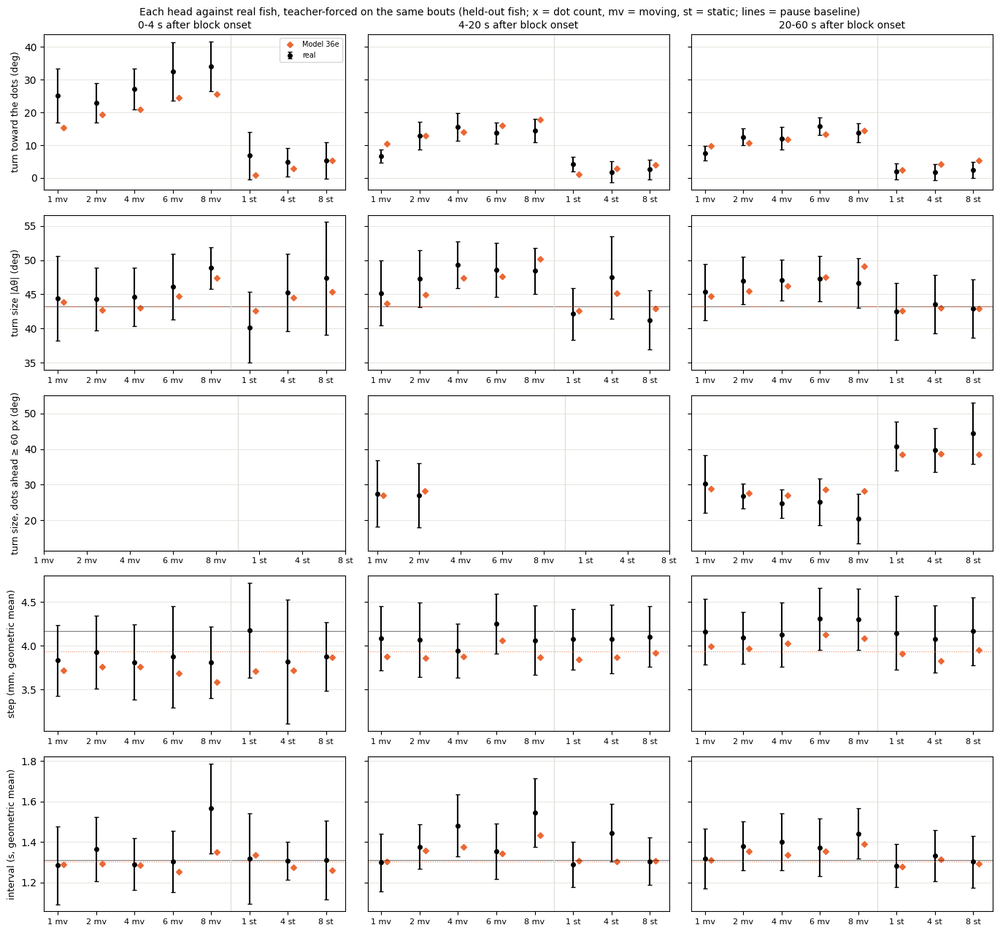

In [11]:
unit_eval.show('36e')

### F, 3 layers, seed 101


== held-out likelihood per head (bits per bout)
turn             7.662
displacement     4.500
interval         1.198
joint           13.360

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last.csv  (15 rows) in 352s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_rej
abs_dtheta_w1          

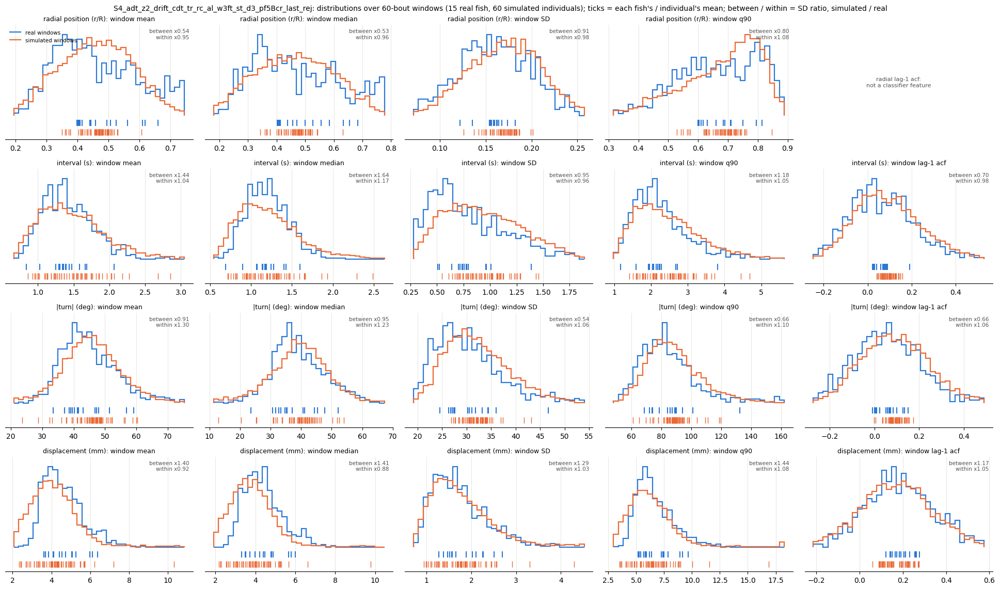


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 13.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.56     1.10  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  23.5 +/- 1.5
d2s3.5    3.60     2.76  2.64  1.94  11.0   9.0                  17.4 +/- 0.9  21.4 +/- 1.4
d4s3.5    1.31     0.86  4.68  2.67  19.0   7.0                  18.7 +/- 1.7  19.3 +/- 1.0
d6s3.5    0.80     0.56  4.62  3.83  13.0  11.0                  16.7 +/- 1.3  16.3 +/- 1.1
d8s3.5    1.91     1.90  4.97  1.39  11.0   5.0                  16.3 +/- 1.0  18

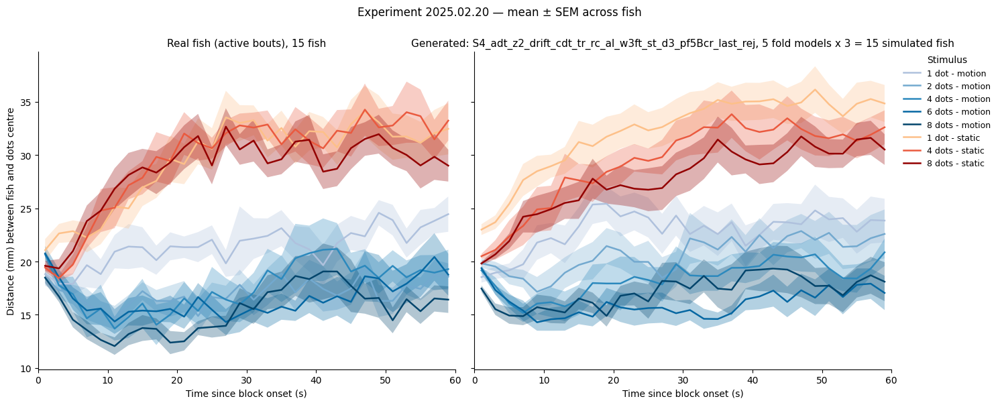


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

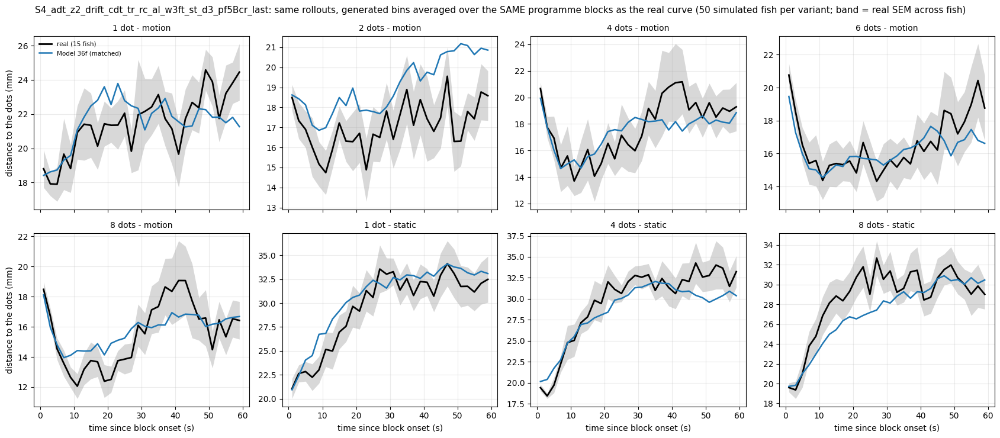


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last                  
           plateau   null attraction                                             plateau   null attraction
cond_label                                                                                                
d1s3.5       22.41  23.57       1.16                                               23.25  23.29       0.04
d2s3.5       17.39  23.58       6.19                                               20.73  22.81       2.08
d4s3.5       18.74  23.93       5.19                                               19.11  22.91       3.80
d6s3.5       16.69  23.12       6.43                                               17.03  23.26       6.23
d8s3.5       16.41

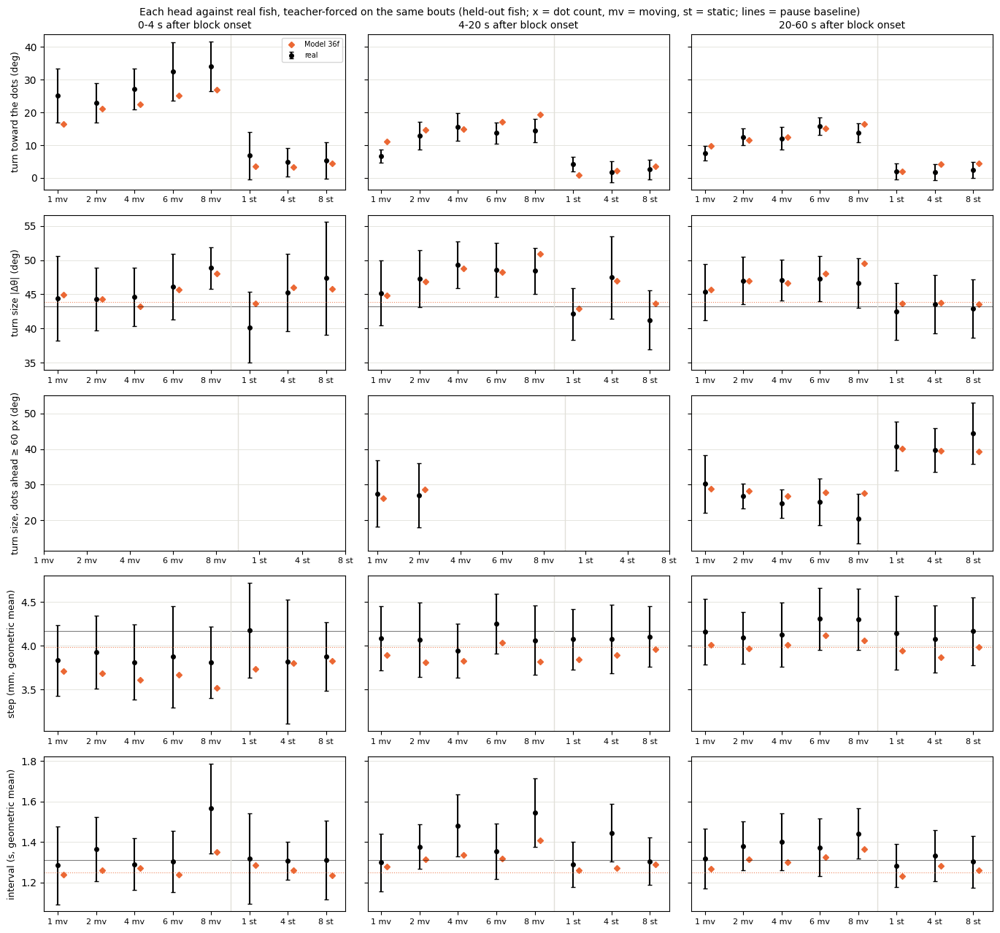

In [12]:
unit_eval.show('36f')

### M6, turn size, seed 0


== held-out likelihood per head (bits per bout)


turn             7.663
displacement     4.501
interval         1.221
joint           13.385

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_tz'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_tz.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_tz.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_tz.csv  (15 rows) in 1668s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_rej
abs_dtheta_w1                                        8.5963
symbol_js                                            0.0114
dt_w1                                             

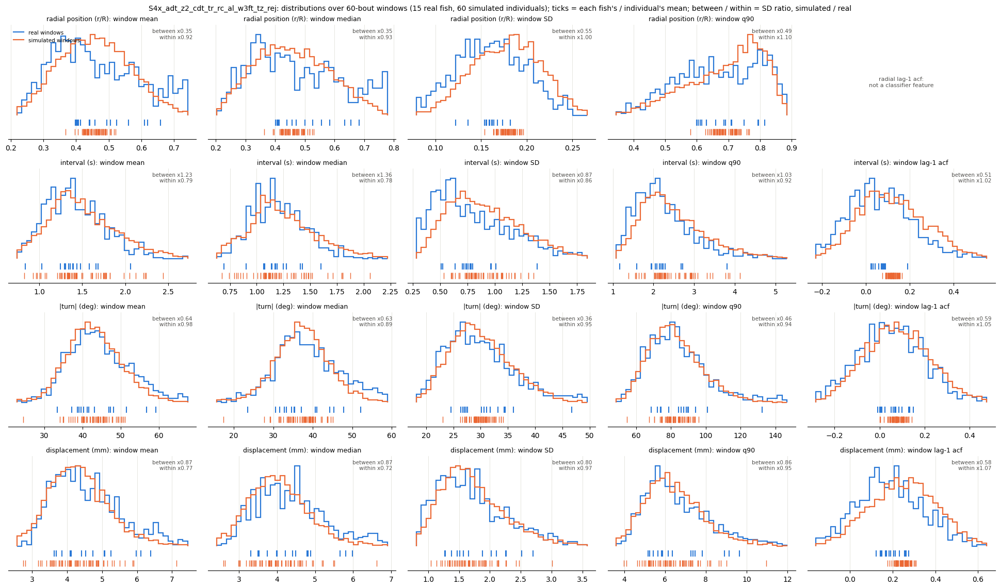


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_fold4.pt: 3 rollouts
dropped 12.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.22     0.88  0.15  0.49   3.0   5.0                  22.3 +/- 0.9  21.4 +/- 0.8
d2s3.5    1.89     1.45  2.64  2.81  11.0  11.0                  17.4 +/- 0.9  19.5 +/- 0.8
d4s3.5    1.27     0.77  4.68   3.9  19.0   7.0                  18.7 +/- 1.7  18.2 +/- 0.5
d6s3.5    1.50     1.11  4.62  4.64  13.0   9.0                  16.7 +/- 1.3  18.1 +/- 0.5
d8s3.5    1.81     1.49  4.97  3.24  11.0   9.0                  16.3 +/- 1.0  16.5 +/- 0.6
d1s0     

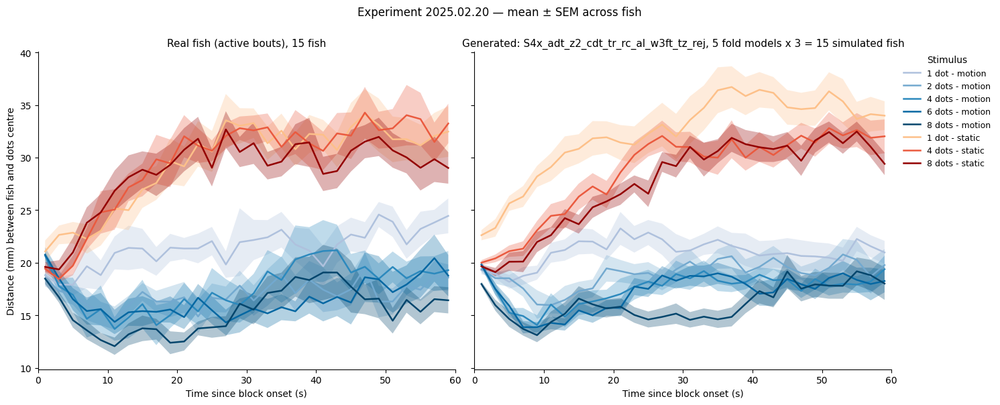


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

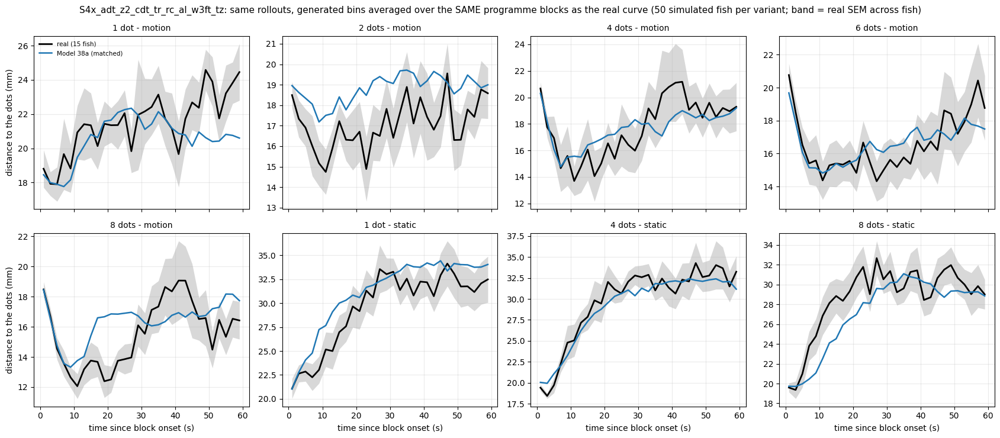


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_tz                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           21.56  22.66       1.10
d2s3.5       17.39  23.58       6.19                           19.55  22.40       2.85
d4s3.5       18.74  23.93       5.19                           18.28  22.31       4.03
d6s3.5       16.69  23.12       6.43                           17.16  22.31       5.16
d8s3.5       16.41  23.36       6.94                           16.64  22.29       5.65

== turn toward the moving dots by dot count
           real  S4x_adt_z

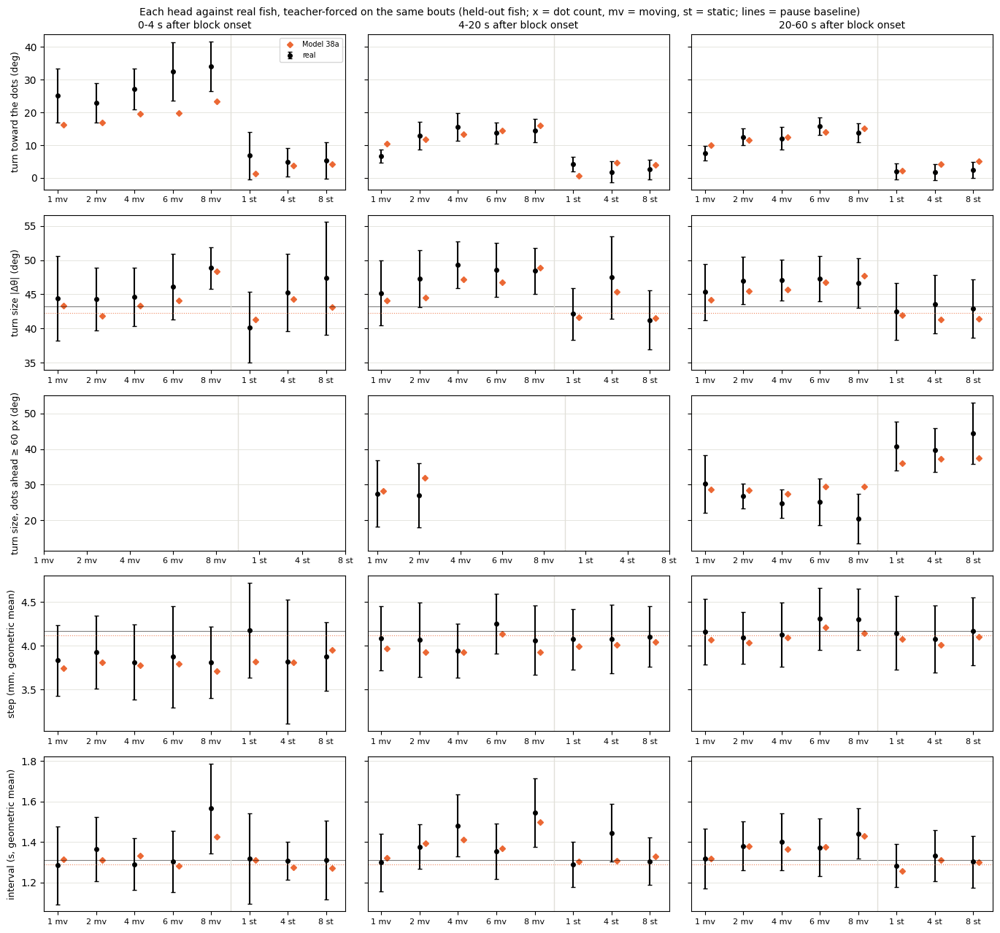

In [13]:
unit_eval.show('38a')

### M6, turn size, seed 101


== held-out likelihood per head (bits per bout)
turn             7.661
displacement     4.498
interval         1.235
joint           13.395

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_tz'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_tz.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_tz.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_tz.csv  (15 rows) in 1601s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_rej
abs_dtheta_w1                                        7.9085
symbol_js                                            0.0109
dt

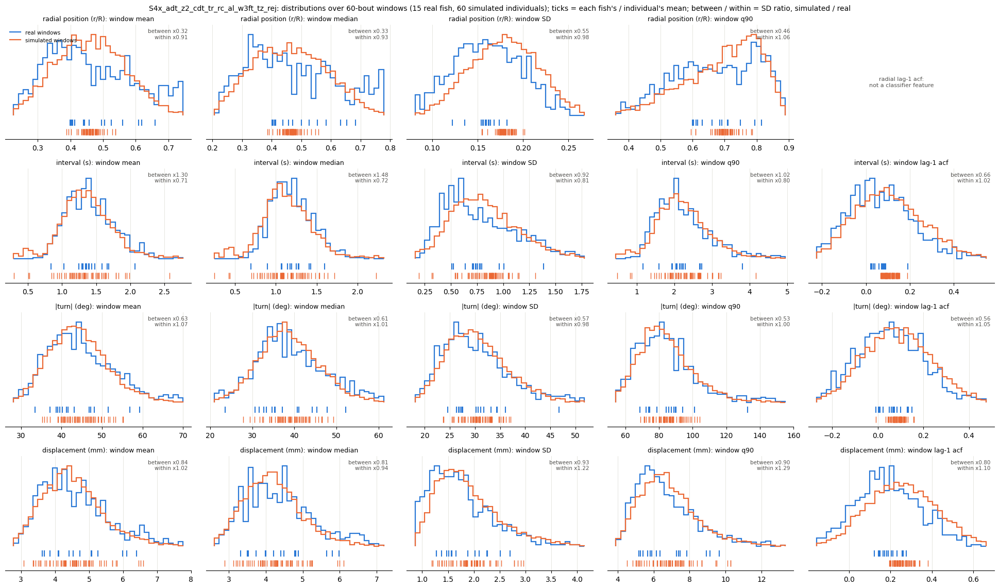


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_fold4.pt: 3 rollouts
dropped 10.2% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.73     1.13  0.15  0.42   3.0   5.0                  22.3 +/- 0.9  20.5 +/- 0.6
d2s3.5    1.98     1.64  2.64  1.27  11.0   7.0                  17.4 +/- 0.9  19.3 +/- 0.7
d4s3.5    0.96     0.60  4.68  4.69  19.0  13.0                  18.7 +/- 1.7  18.7 +/- 0.9
d6s3.5    0.95     0.67  4.62  3.47  13.0   7.0                  16.7 +/- 1.3  16.5 +/- 0.5
d8s3.5    1.88     1.63  4.97  2.76  11.0   9.0                  16.3 +/- 1.0  15.8 +/- 0.5
d1s0     

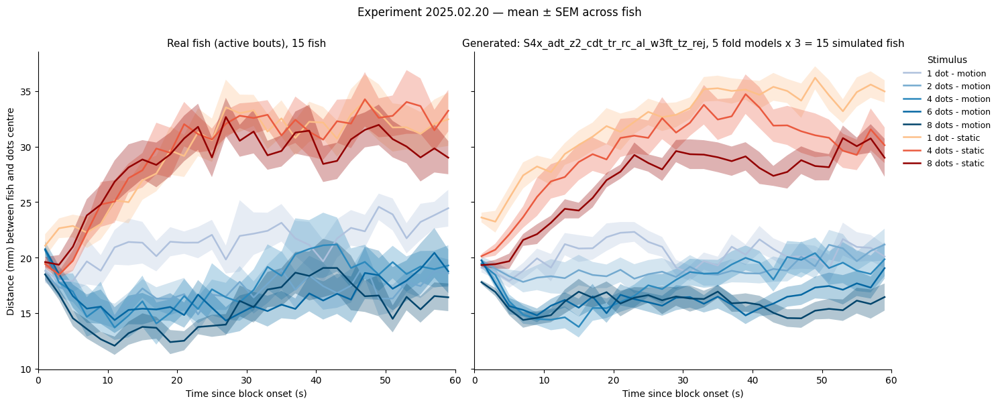


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

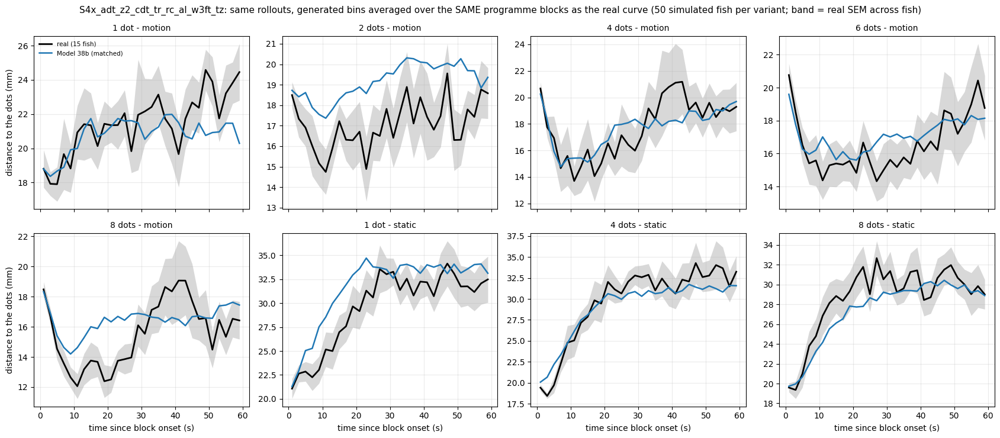


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_tz                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           21.68  22.95       1.27
d2s3.5       17.39  23.58       6.19                           19.87  22.68       2.82
d4s3.5       18.74  23.93       5.19                           19.04  23.02       3.97
d6s3.5       16.69  23.12       6.43                           17.86  23.09       5.23
d8s3.5       16.41  23.36       6.94                           16.85  22.73       5.88

== turn toward the moving dots by dot count
           real  S4x_adt_z

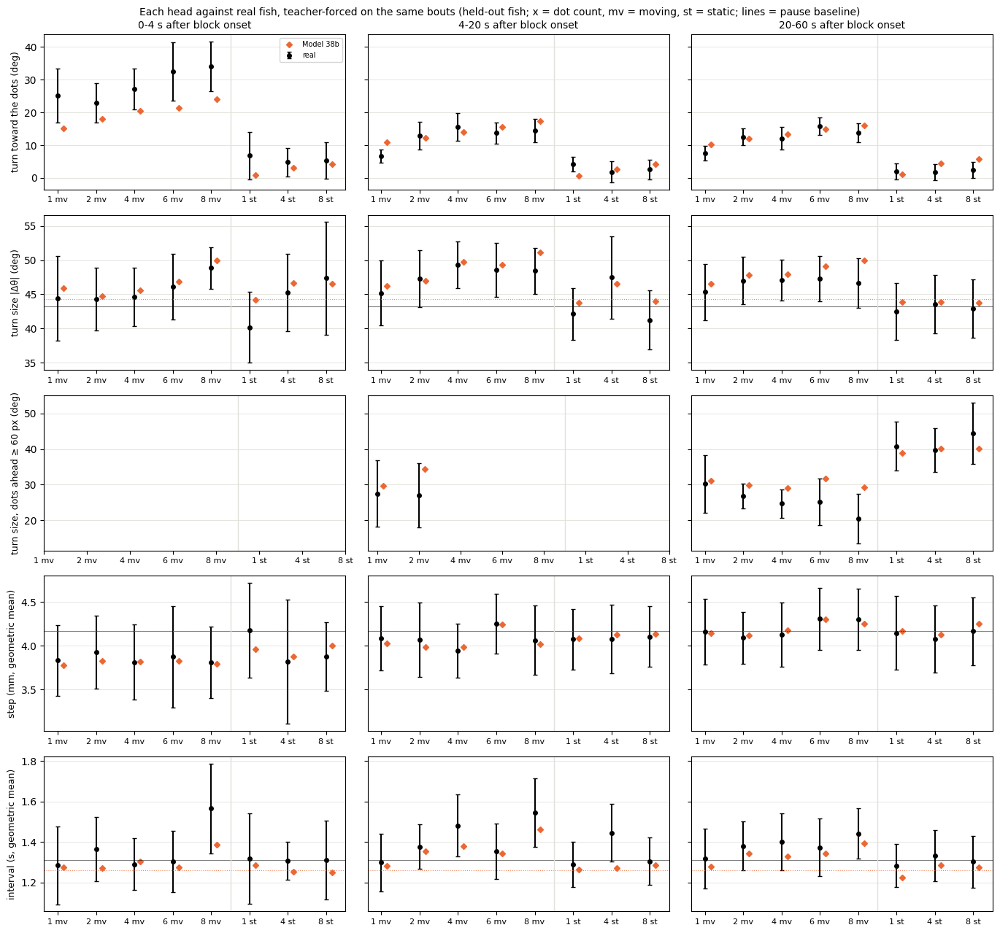

In [14]:
unit_eval.show('38b')

### D4, turn size, seed 0


== held-out likelihood per head (bits per bout)


turn             7.626
displacement     4.535
interval         1.216
joint           13.377

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz.csv  (15 rows) in 448s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_rej
abs_dtheta_w1                                               10.4036
symbol_js                                                    0.

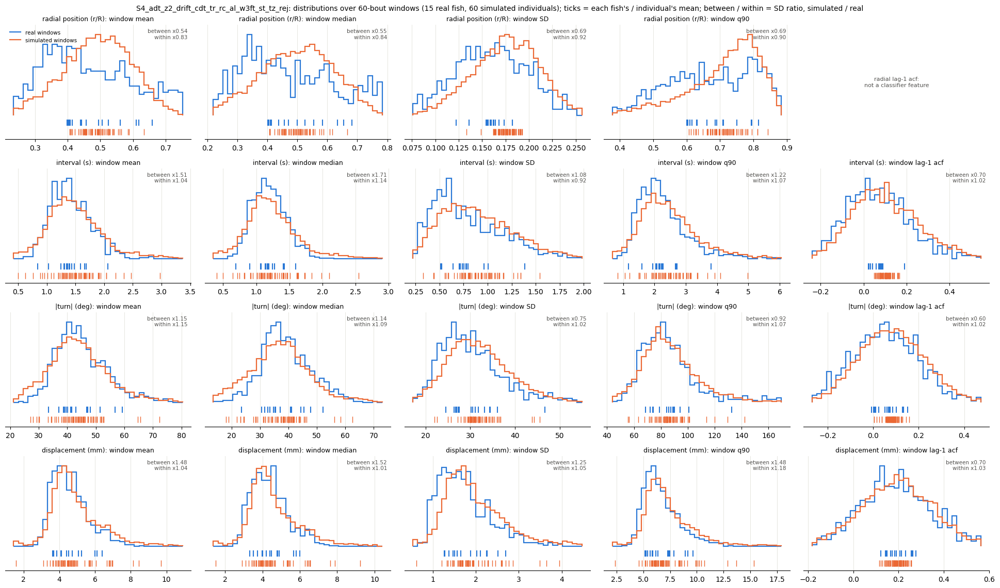


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_fold4.pt: 3 rollouts
dropped 10.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    0.98     0.66  0.15  0.17   3.0   5.0                  22.3 +/- 0.9  22.2 +/- 1.2
d2s3.5    1.70     1.30  2.64  2.57  11.0  11.0                  17.4 +/- 0.9  19.2 +/- 1.6
d4s3.5    1.34     0.81  4.68  4.19  19.0   9.0                  18.7 +/- 1.7  18.2 +/- 1.3
d6s3.5    1.61     1.16  4.62  3.42  13.0  15.0                  16.7 +/- 1.3  18.7 +/- 1.1
d8s3.5    2.23     2.10  4.97  3.08  11.0   7.0                  16.3 +/- 1.0  18.2 +/- 1.1
d

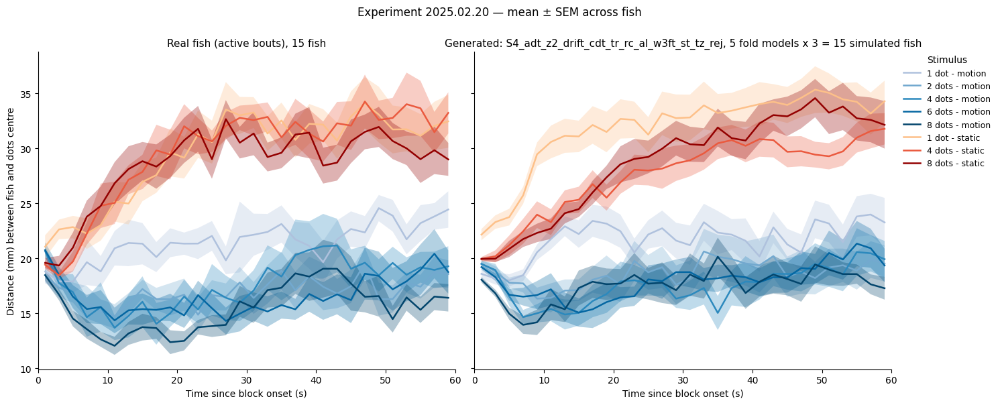


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

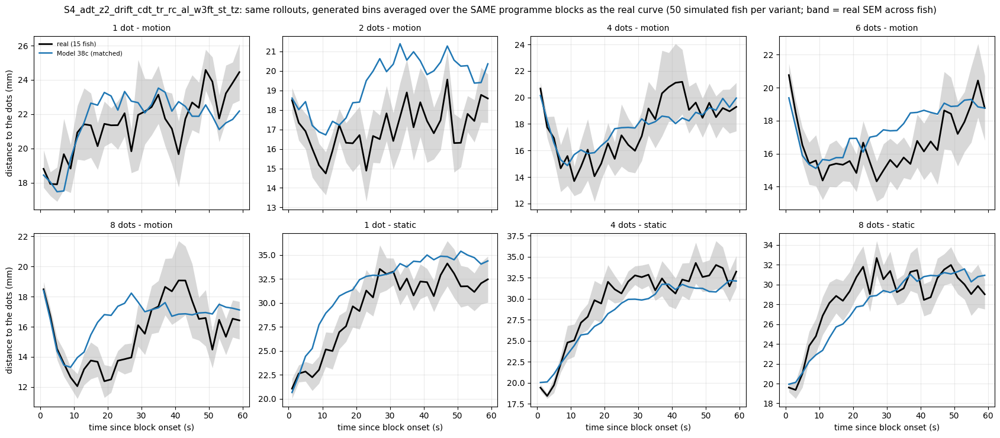


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz                  
           plateau   null attraction                                 plateau   null attraction
cond_label                                                                                    
d1s3.5       22.41  23.57       1.16                                   22.97  23.28       0.31
d2s3.5       17.39  23.58       6.19                                   20.56  23.32       2.76
d4s3.5       18.74  23.93       5.19                                   19.51  23.39       3.88
d6s3.5       16.69  23.12       6.43                                   19.25  23.51       4.26
d8s3.5       16.41  23.36       6.94                                   18.61  23.49       4.88

== tur

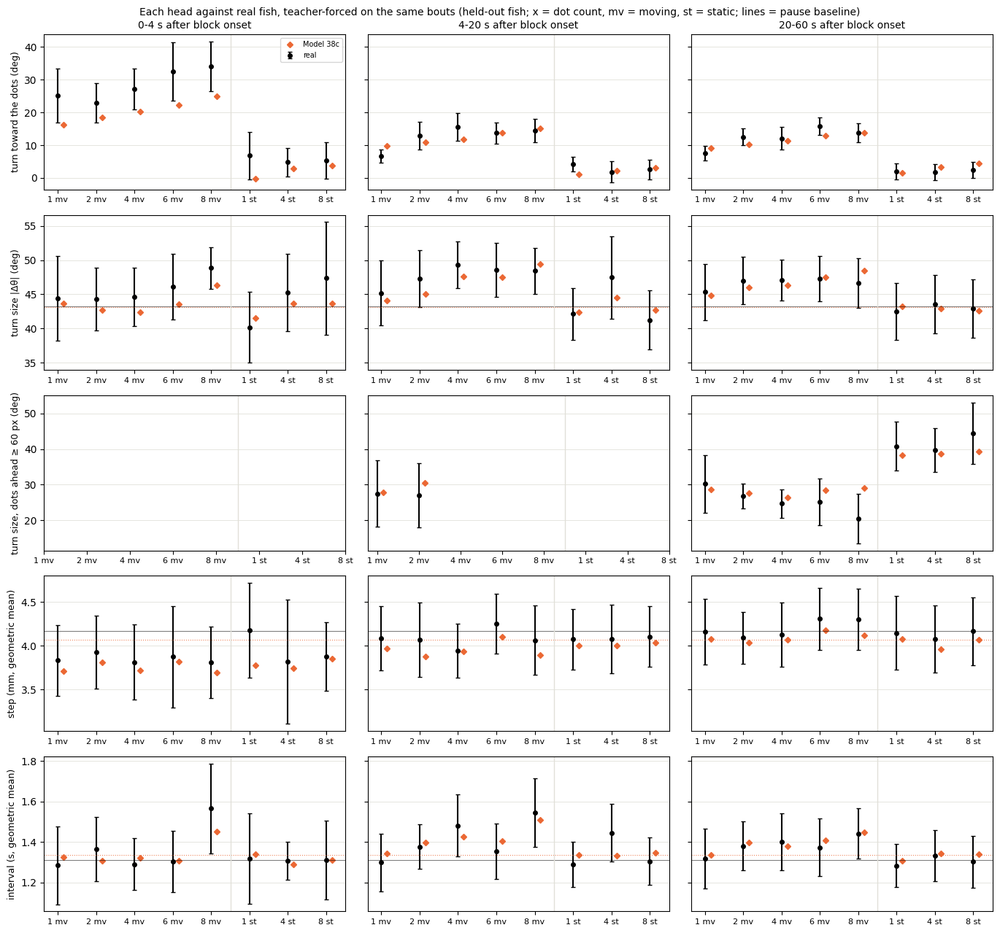

In [15]:
unit_eval.show('38c')

### D4, turn size, seed 101


== held-out likelihood per head (bits per bout)
turn             7.641
displacement     4.524
interval         1.201
joint           13.366

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz.csv  (15 rows) in 409s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_rej
abs_dtheta_w1                                                8.1784
symbol_js      

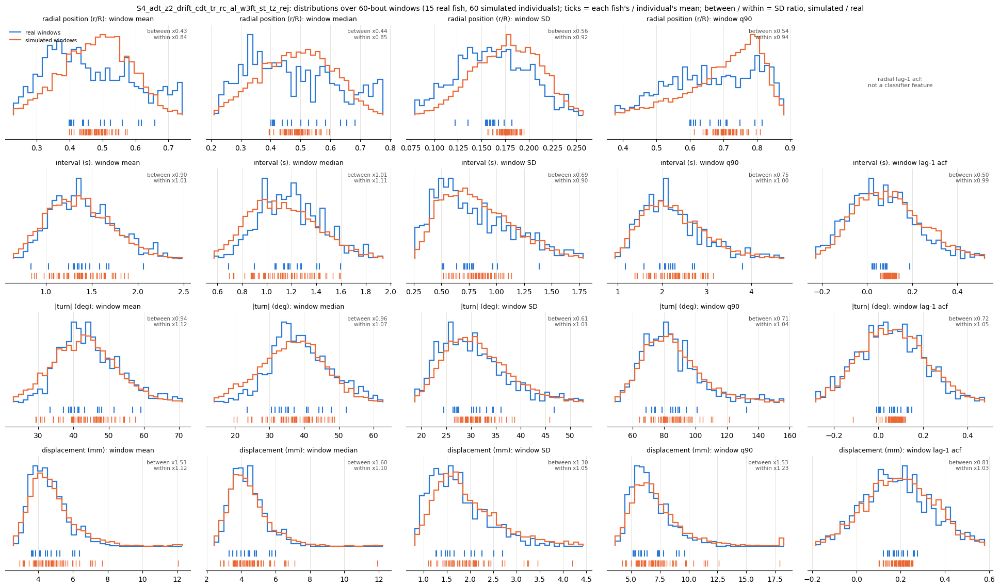


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_fold4.pt: 3 rollouts
dropped 12.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.82     1.22  0.15  0.06   3.0   3.0                  22.3 +/- 0.9  19.9 +/- 0.7
d2s3.5    2.14     1.71  2.64  1.64  11.0   9.0                  17.4 +/- 0.9  19.5 +/- 1.0
d4s3.5    1.62     0.95  4.68  5.05  19.0   9.0                  18.7 +/- 1.7  17.6 +/- 0.9
d6s3.5    1.06     0.73  4.62  4.74  13.0  11.0                  16.7 +/- 1.3  17.7 +/- 1.4
d8s3.5    1.54     1.38  4.97  3.83  11.0   9.0                  16.3 +/- 1.0  16.7 +/- 1.1
d

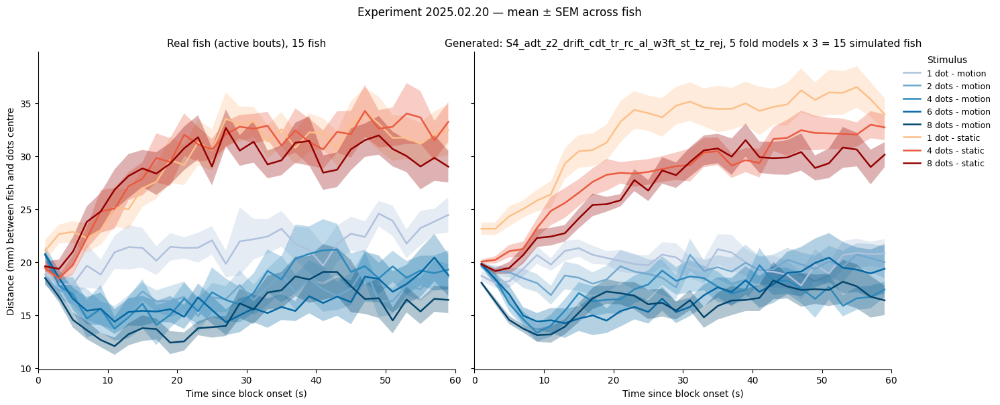


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

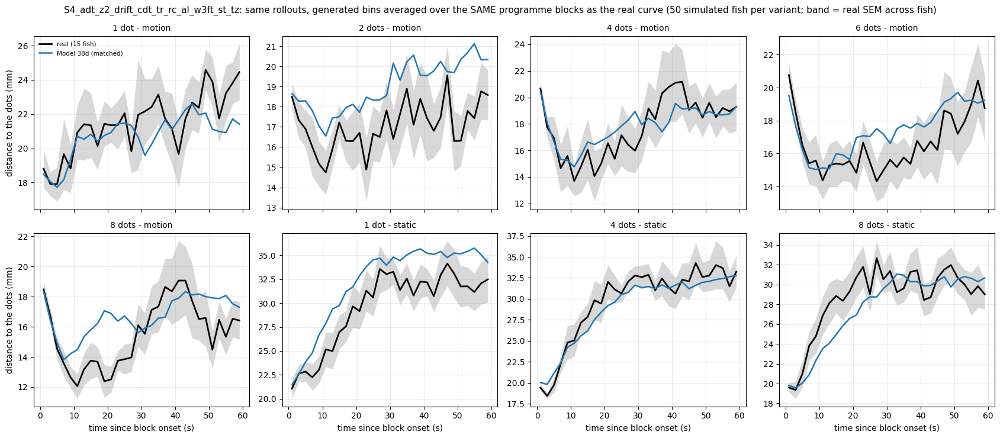


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz                  
           plateau   null attraction                                 plateau   null attraction
cond_label                                                                                    
d1s3.5       22.41  23.57       1.16                                   20.56  22.76       2.20
d2s3.5       17.39  23.58       6.19                                   18.96  22.82       3.85
d4s3.5       18.74  23.93       5.19                                   18.91  22.83       3.91
d6s3.5       16.69  23.12       6.43                                   18.46  22.65       4.19
d8s3.5       16.41  23.36       6.94                                   17.63  22.96       5.34

== tur

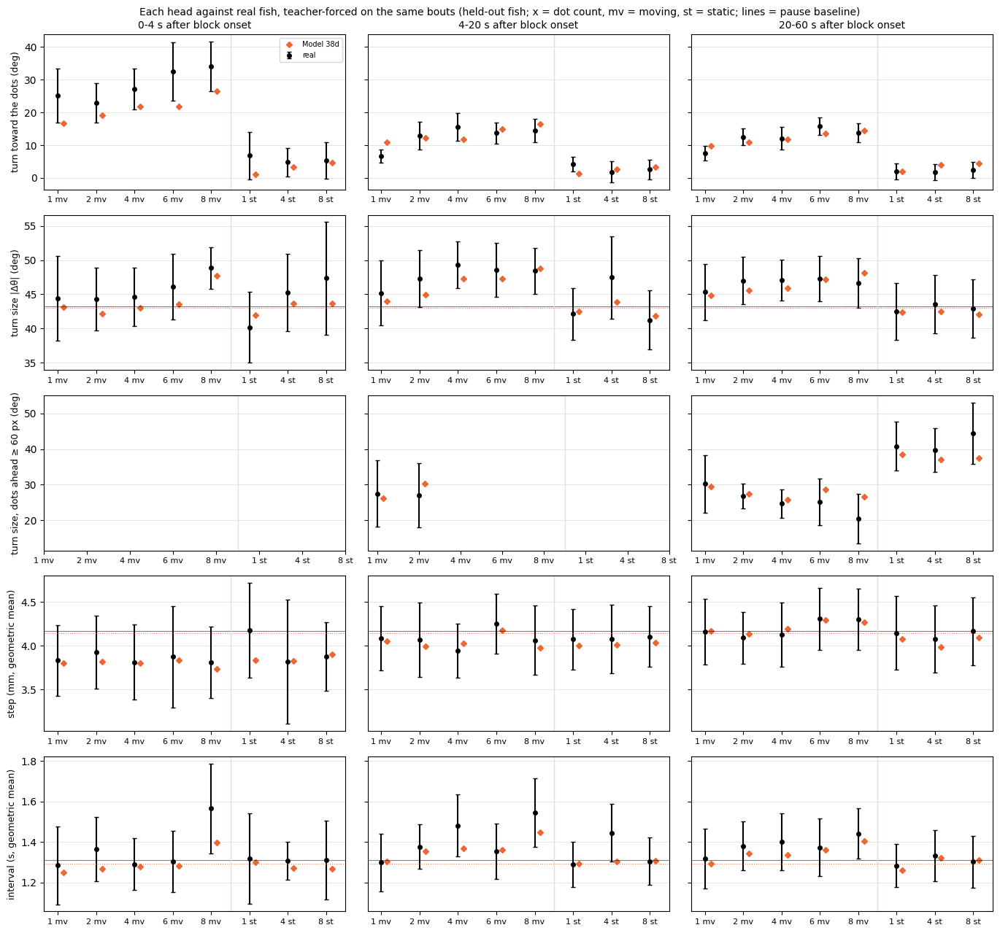

In [16]:
unit_eval.show('38d')

### F, turn size, seed 0


== held-out likelihood per head (bits per bout)


turn             7.626
displacement     4.535
interval         1.216
joint           13.377

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last.csv  (15 rows) in 1161s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_rej
abs_dtheta_w1                                                         

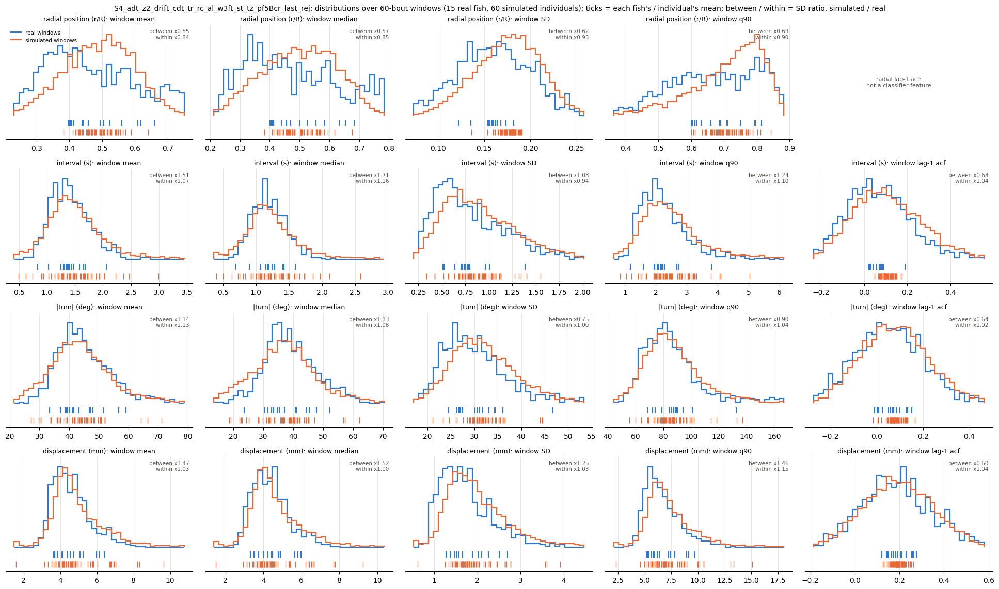


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 12.2% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.28     0.85  0.15  0.08   3.0   3.0                  22.3 +/- 0.9  22.8 +/- 1.1
d2s3.5    1.70     1.36  2.64  3.54  11.0  11.0                  17.4 +/- 0.9  18.7 +/- 1.2
d4s3.5    1.63     0.95  4.68  3.28  19.0   7.0                  18.7 +/- 1.7  18.4 +/- 1.3
d6s3.5    1.36     0.96  4.62  4.82  13.0  11.0                  16.7 +/- 1.3  17.7 +/- 1.4
d8s3.5    1.06     0.85  4.97  3.41  11.0  15.0                  16.3 +/- 1.0  15

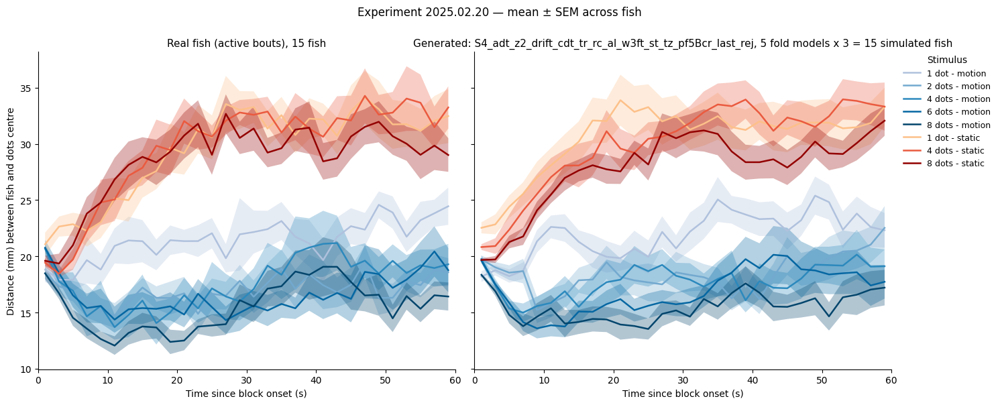


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

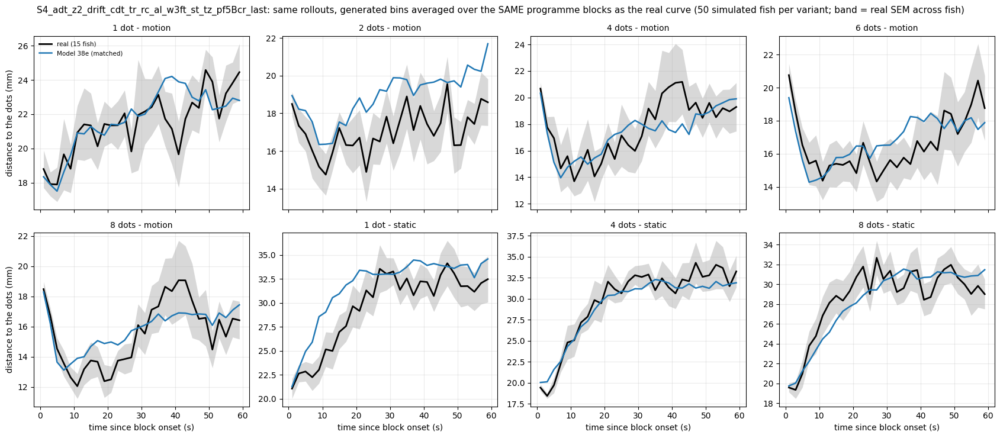


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last                  
           plateau   null attraction                                             plateau   null attraction
cond_label                                                                                                
d1s3.5       22.41  23.57       1.16                                               24.40  23.86      -0.54
d2s3.5       17.39  23.58       6.19                                               19.92  23.59       3.68
d4s3.5       18.74  23.93       5.19                                               18.92  23.62       4.70
d6s3.5       16.69  23.12       6.43                                               18.74  23.76       5.01
d8s3.5       16.41

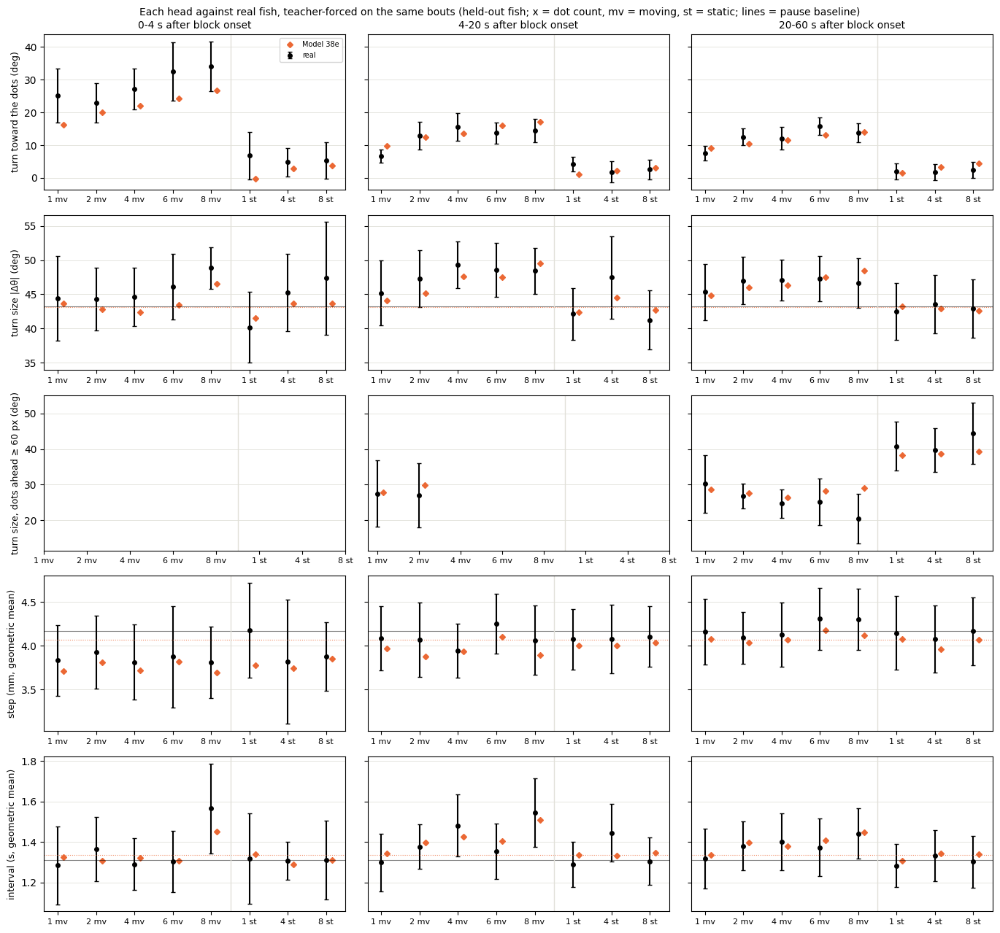

In [17]:
unit_eval.show('38e')

### F, turn size, seed 101


== held-out likelihood per head (bits per bout)
turn             7.641
displacement     4.524
interval         1.201
joint           13.366

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last.csv  (15 rows) in 1126s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_rej
abs_dtheta_w1         

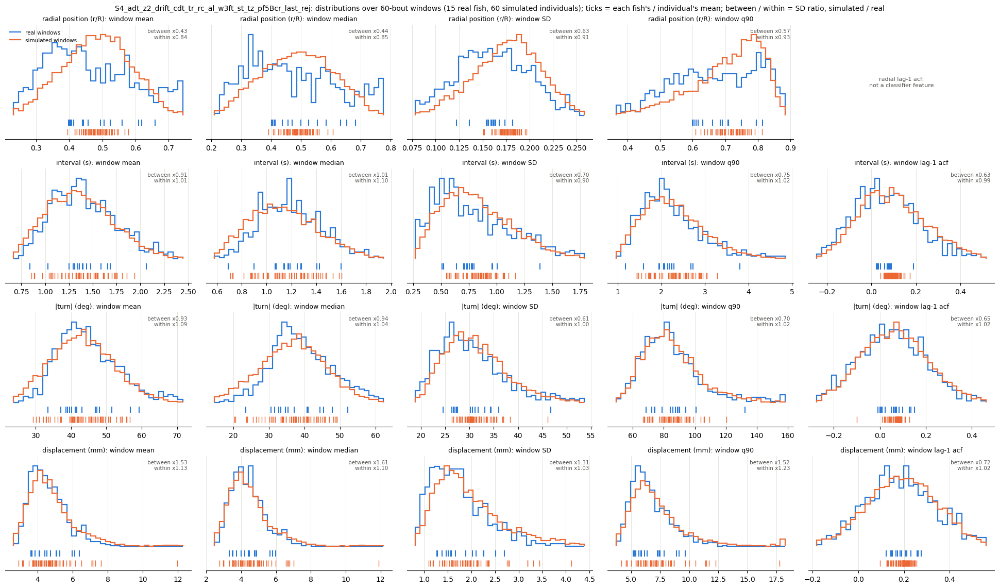


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 11.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.51     1.00  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  21.3 +/- 0.9
d2s3.5    1.43     1.14  2.64  4.46  11.0  11.0                  17.4 +/- 0.9  18.3 +/- 0.7
d4s3.5    1.89     1.02  4.68   5.1  19.0  11.0                  18.7 +/- 1.7  16.4 +/- 0.9
d6s3.5    1.36     1.02  4.62  6.04  13.0  13.0                  16.7 +/- 1.3  16.8 +/- 1.2
d8s3.5    1.32     1.24  4.97  4.38  11.0   9.0                  16.3 +/- 1.0  17

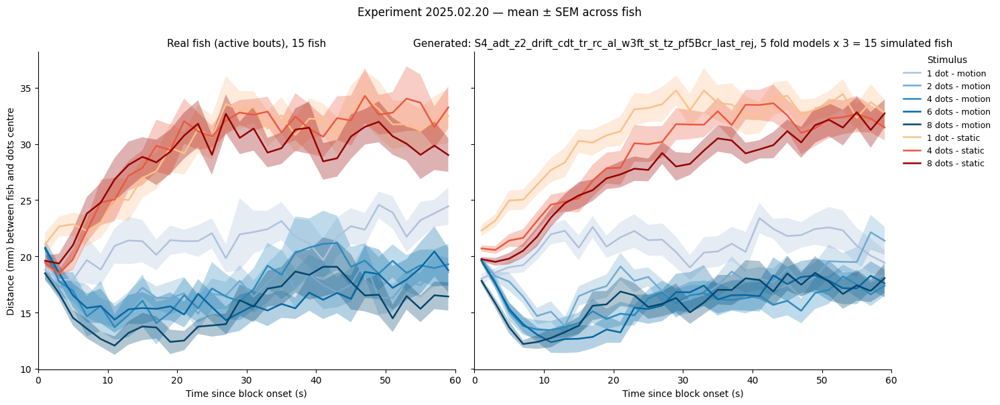


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

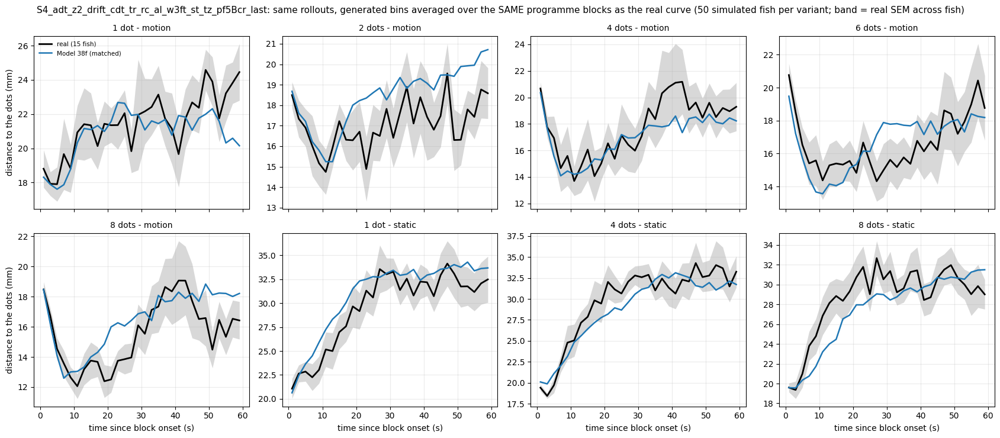


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last                  
           plateau   null attraction                                             plateau   null attraction
cond_label                                                                                                
d1s3.5       22.41  23.57       1.16                                               21.32  22.65       1.33
d2s3.5       17.39  23.58       6.19                                               19.07  22.75       3.68
d4s3.5       18.74  23.93       5.19                                               17.77  22.66       4.89
d6s3.5       16.69  23.12       6.43                                               17.54  22.58       5.03
d8s3.5       16.41

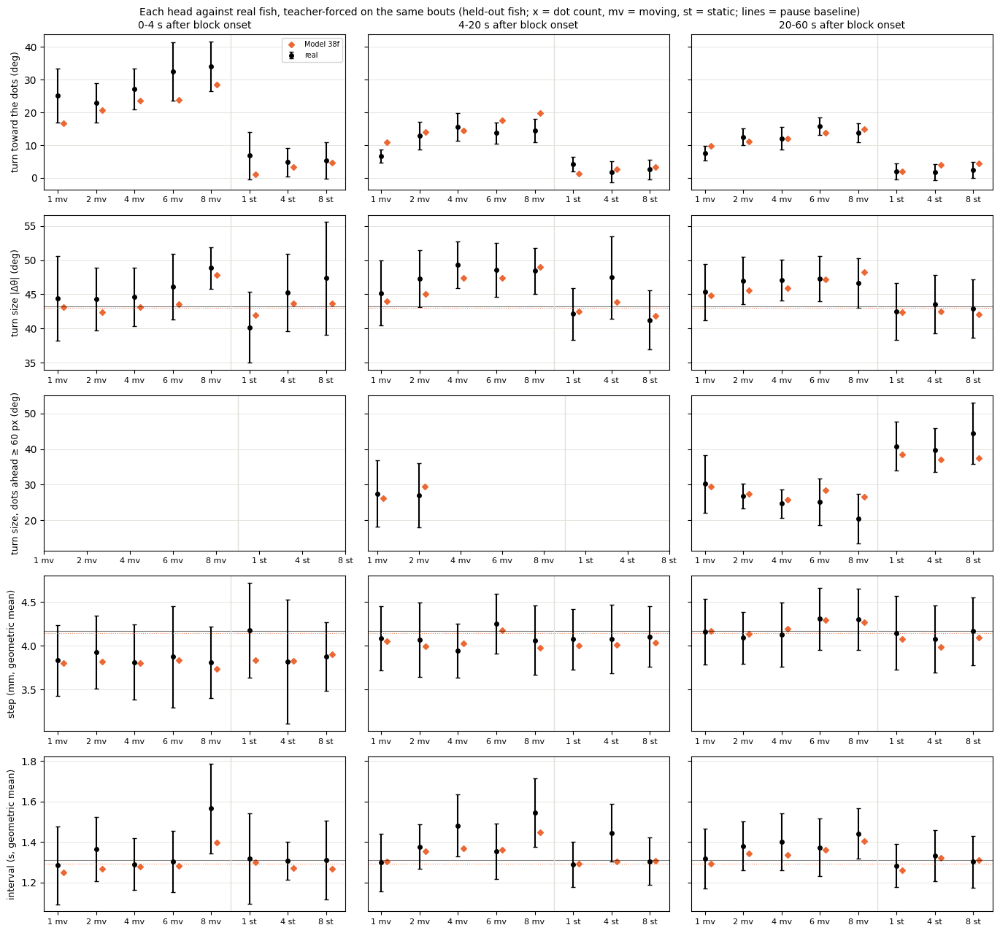

In [18]:
unit_eval.show('38f')

### D4, tau 200, seed 0


== held-out likelihood per head (bits per bout)
turn             7.626
displacement     4.515
interval         1.205
joint           13.347

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv  (15 rows) in 1233s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_rej
abs_dtheta_w1                                                  9.1021
sy

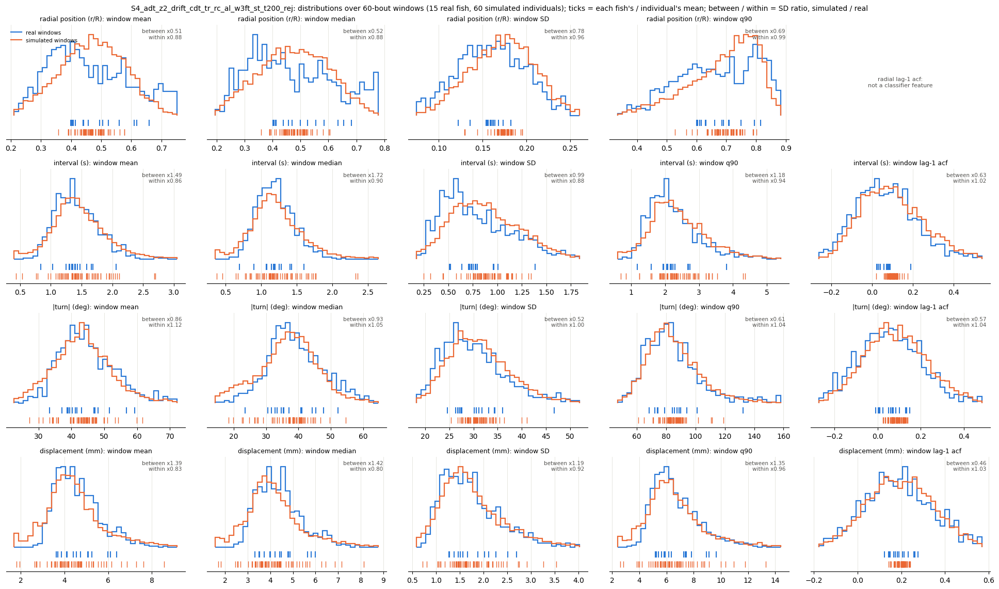


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold4.pt: 3 rollouts
dropped 10.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.76     1.16  0.15  1.28   3.0   5.0                  22.3 +/- 0.9  20.3 +/- 1.1
d2s3.5    1.17     0.97  2.64  3.18  11.0  13.0                  17.4 +/- 0.9  18.4 +/- 1.3
d4s3.5    1.62     0.93  4.68  3.79  19.0   7.0                  18.7 +/- 1.7  16.7 +/- 1.2
d6s3.5    1.20     0.83  4.62  4.45  13.0   9.0                  16.7 +/- 1.3  16.2 +/- 0.8
d8s3.5    1.69     1.23  4.97  3.55  11.0   9.0                  16.3 +/- 1.0  15.0 +/- 0.8

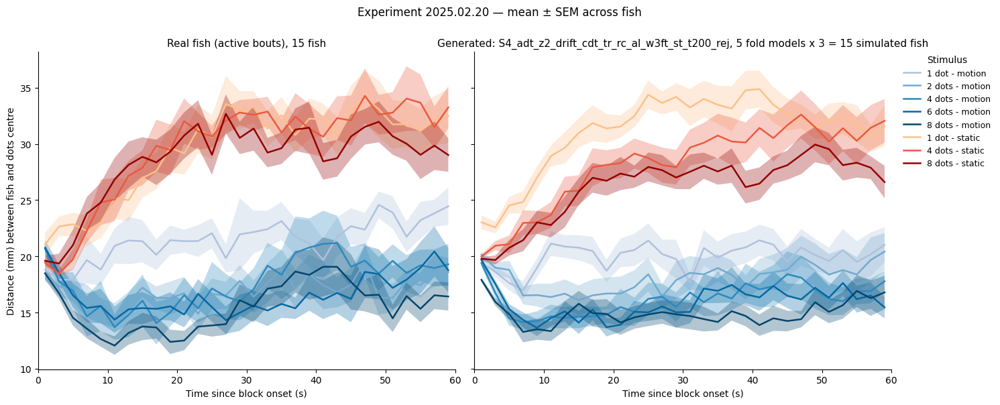


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

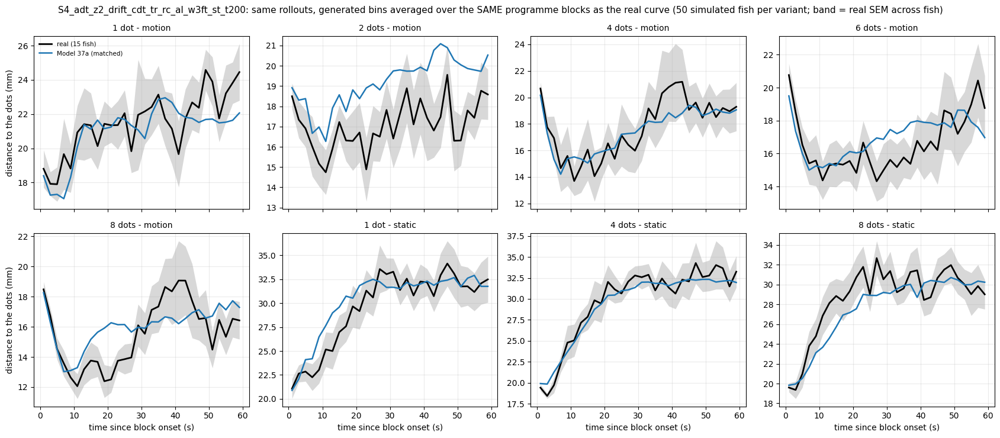


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200                  
           plateau   null attraction                                   plateau   null attraction
cond_label                                                                                      
d1s3.5       22.41  23.57       1.16                                     21.94  22.67       0.73
d2s3.5       17.39  23.58       6.19                                     19.07  22.56       3.49
d4s3.5       18.74  23.93       5.19                                     17.88  22.80       4.93
d6s3.5       16.69  23.12       6.43                                     17.70  22.55       4.85
d8s3.5       16.41  23.36       6.94                                     16.40  22.84   

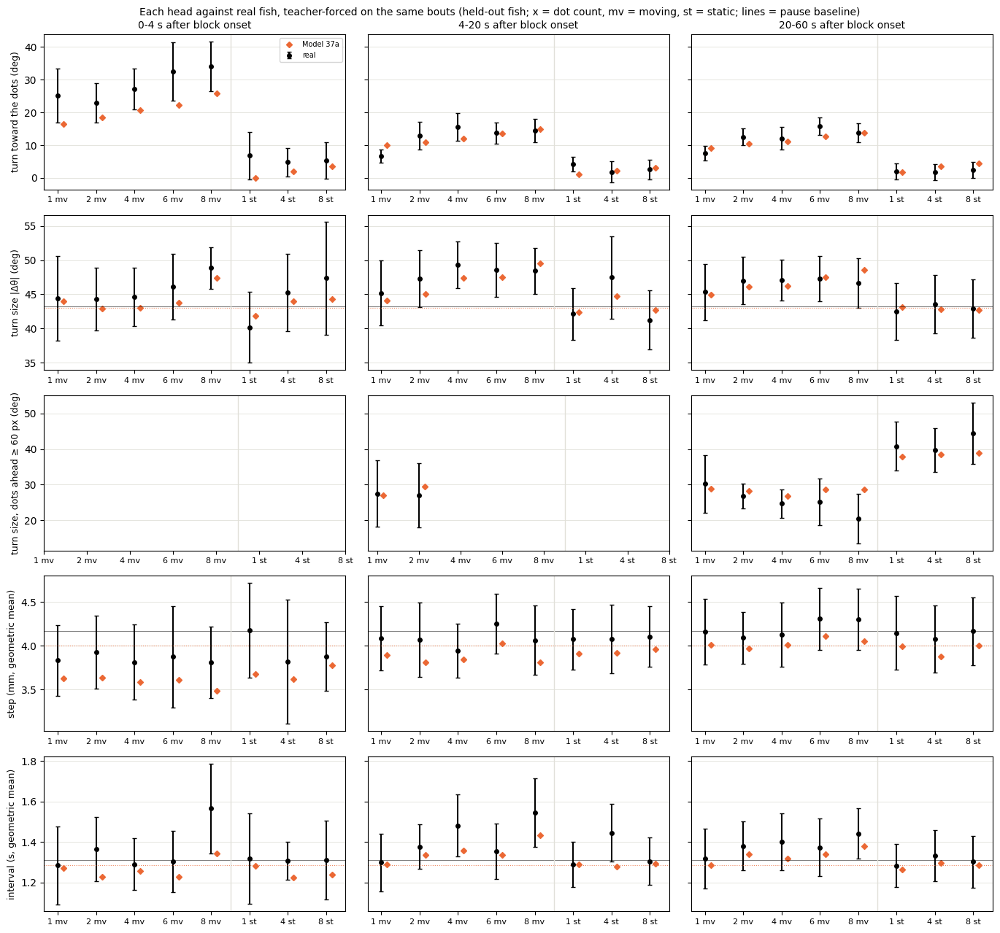

In [19]:
unit_eval.show('37a')

### D4, tau 200, seed 101


== held-out likelihood per head (bits per bout)
turn             7.628
displacement     4.503
interval         1.213
joint           13.344

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv  (15 rows) in 1103s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_rej
abs_dtheta_w1                                                  8.7585
sy

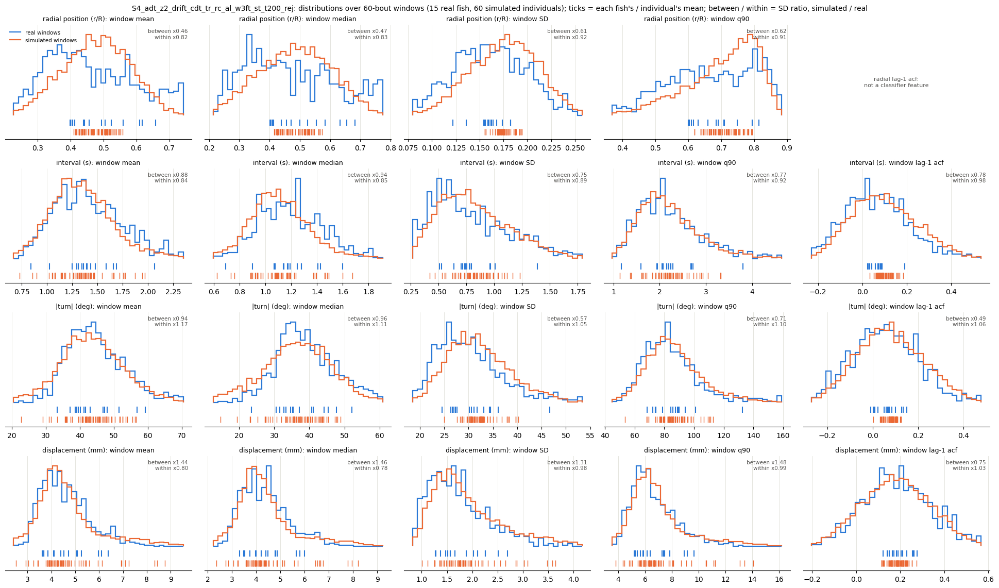


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold4.pt: 3 rollouts
dropped 11.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.50     1.04  0.15  1.01   3.0   5.0                  22.3 +/- 0.9  20.8 +/- 1.0
d2s3.5    2.03     1.52  2.64  2.68  11.0  17.0                  17.4 +/- 0.9  19.7 +/- 0.9
d4s3.5    1.18     0.72  4.68  3.88  19.0   9.0                  18.7 +/- 1.7  18.0 +/- 0.6
d6s3.5    1.13     0.74  4.62  4.05  13.0  13.0                  16.7 +/- 1.3  16.3 +/- 0.7
d8s3.5    1.51     1.37  4.97  2.64  11.0   7.0                  16.3 +/- 1.0  16.4 +/- 1.1

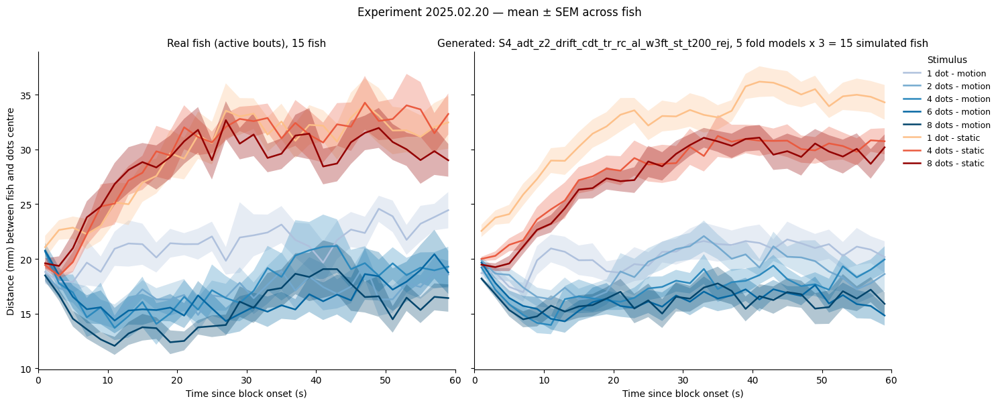


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

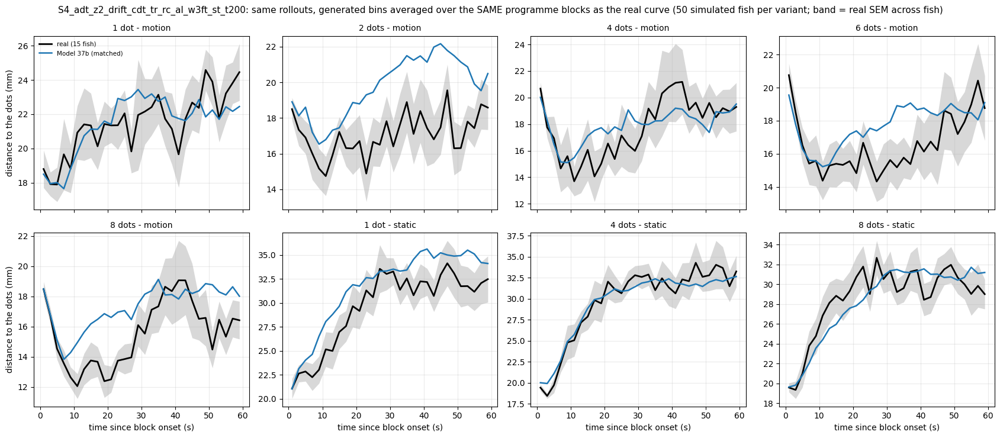


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200                  
           plateau   null attraction                                   plateau   null attraction
cond_label                                                                                      
d1s3.5       22.41  23.57       1.16                                     22.64  23.06       0.41
d2s3.5       17.39  23.58       6.19                                     20.87  23.08       2.21
d4s3.5       18.74  23.93       5.19                                     18.97  22.94       3.97
d6s3.5       16.69  23.12       6.43                                     18.10  23.09       5.00
d8s3.5       16.41  23.36       6.94                                     17.88  23.01   

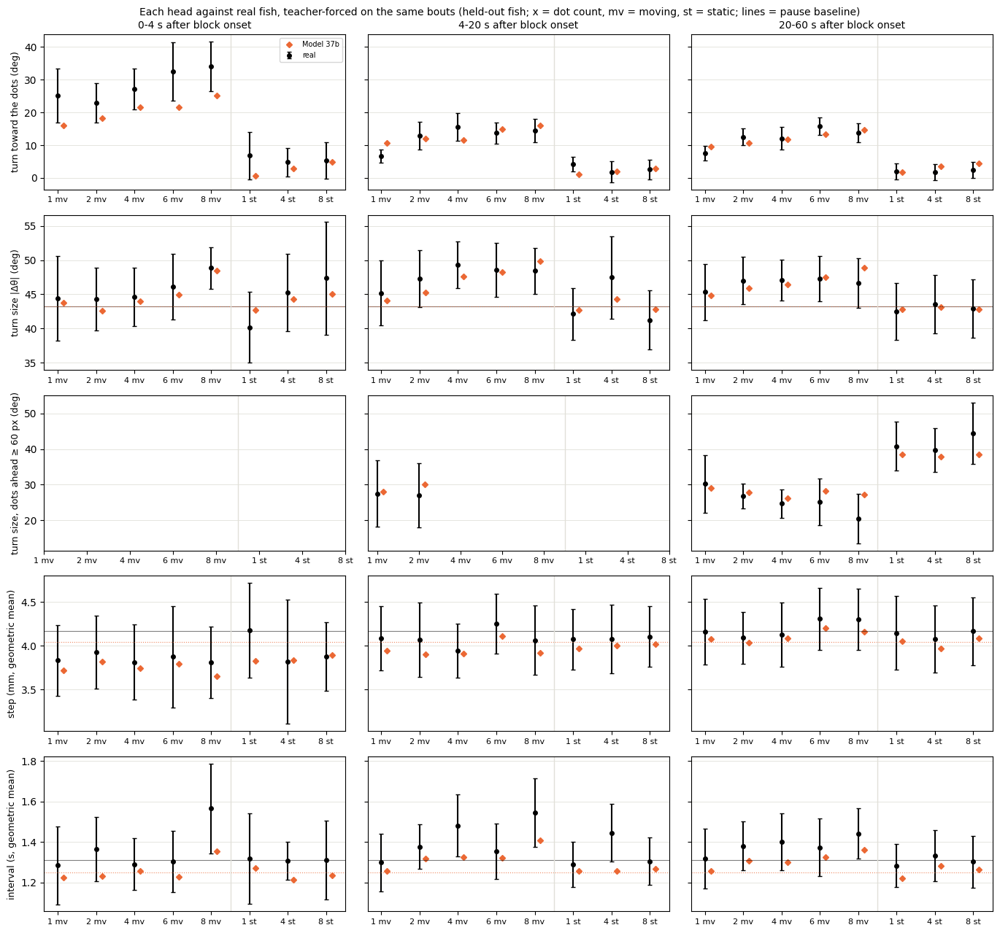

In [20]:
unit_eval.show('37b')

### F, tau 200, seed 0


== held-out likelihood per head (bits per bout)
turn             7.626
displacement     4.516
interval         1.205
joint           13.347

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last.csv  (15 rows) in 1010s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_rej
abs_dtheta_w

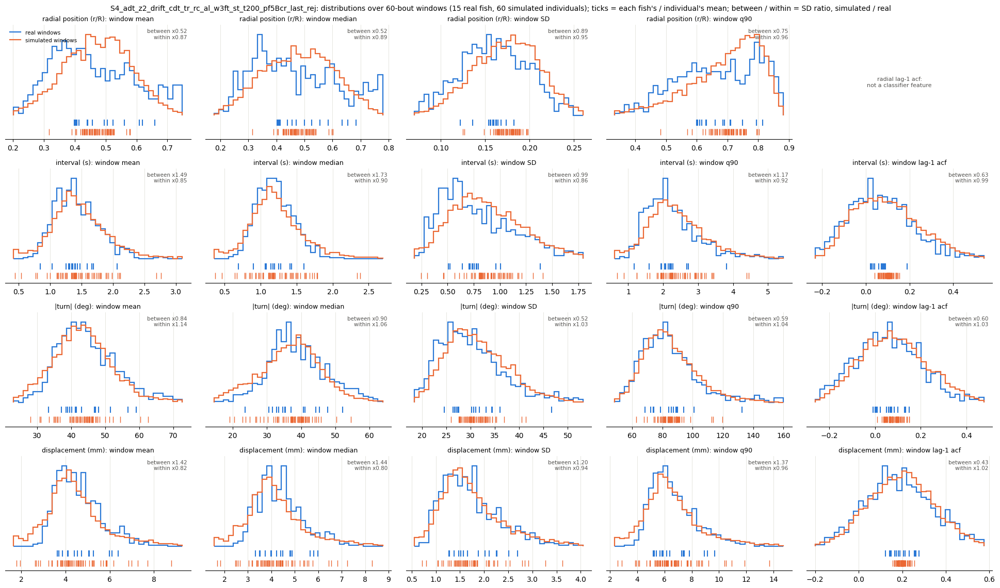


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.3% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.68     1.15  0.15  0.91   3.0   5.0                  22.3 +/- 0.9  21.0 +/- 1.1
d2s3.5    0.86     0.70  2.64  3.27  11.0   9.0                  17.4 +/- 0.9  17.3 +/- 1.3
d4s3.5    1.71     0.98  4.68  5.03  19.0   9.0                  18.7 +/- 1.7  16.7 +/- 1.2
d6s3.5    1.39     1.05  4.62  5.82  13.0  13.0                  16.7 +/- 1.3  16.4 +/- 0.8
d8s3.5    1.23     0.92  4.97  4.01  11.0   9.0                  16.3 +/- 1.0  

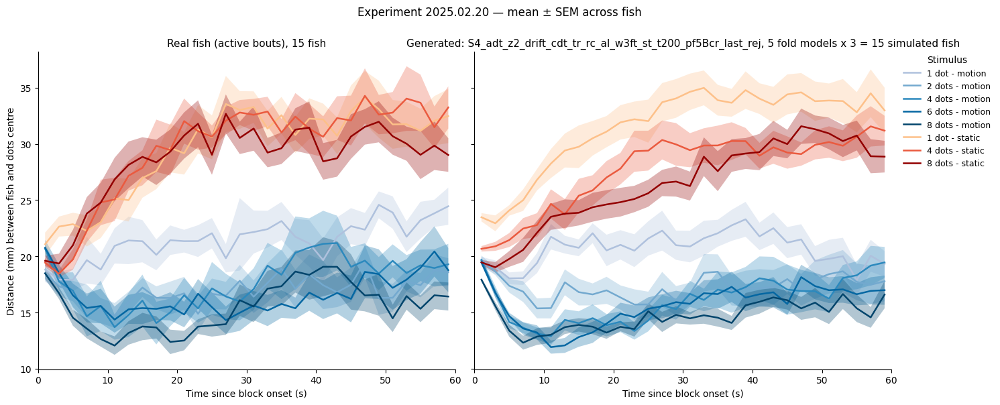


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

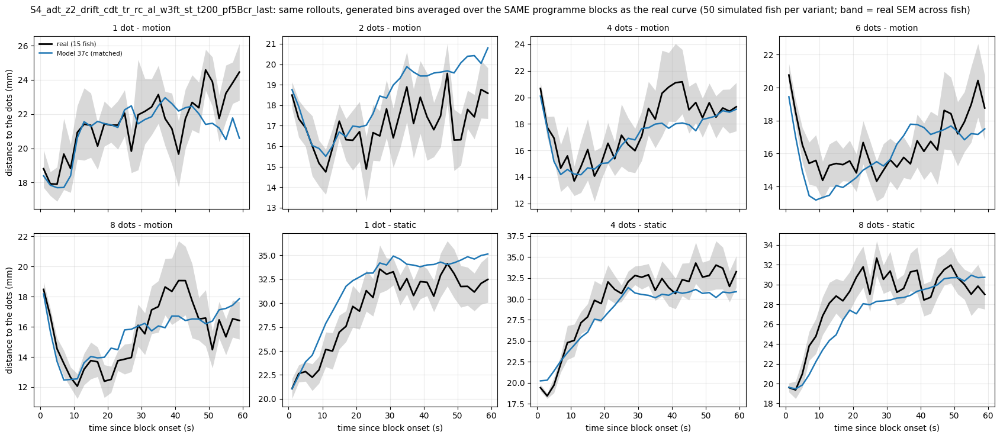


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last                  
           plateau   null attraction                                               plateau   null attraction
cond_label                                                                                                  
d1s3.5       22.41  23.57       1.16                                                 22.28  22.67       0.39
d2s3.5       17.39  23.58       6.19                                                 18.64  22.74       4.10
d4s3.5       18.74  23.93       5.19                                                 17.58  22.73       5.15
d6s3.5       16.69  23.12       6.43                                                 16.67  22.63       5.97
d8s3

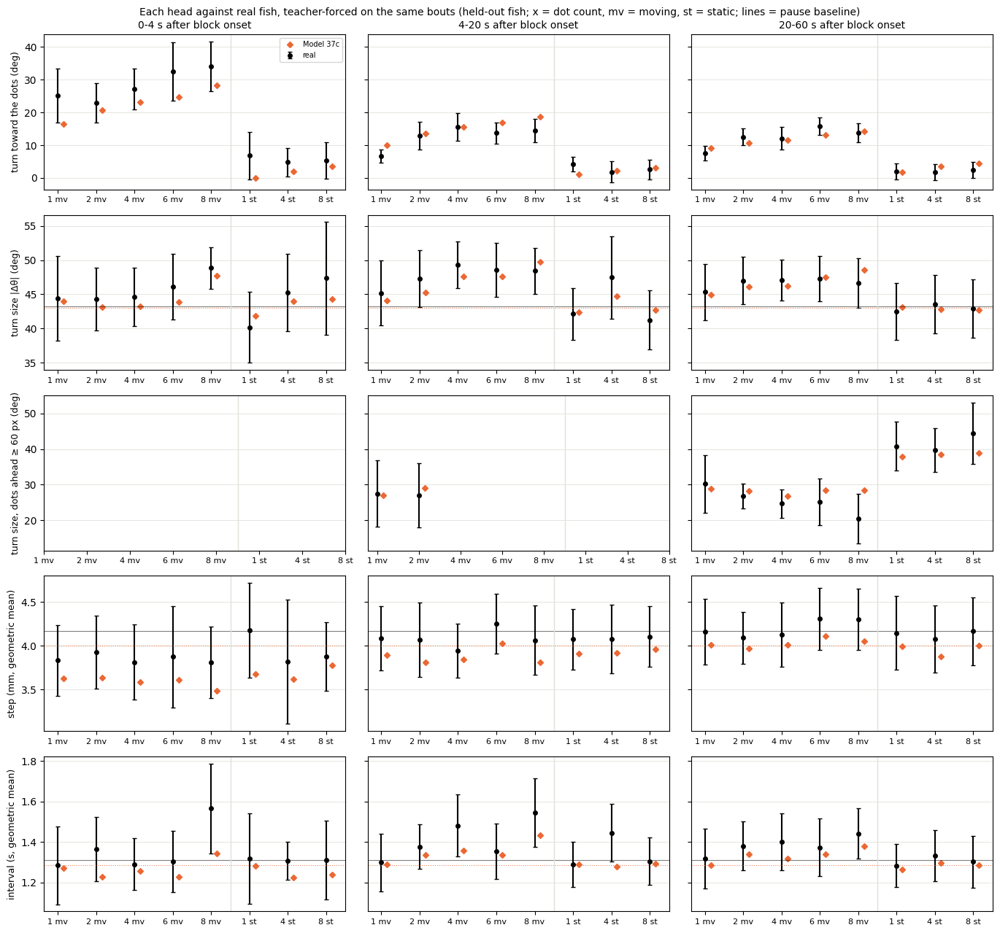

In [21]:
unit_eval.show('37c')

### F, tau 200, seed 101


== held-out likelihood per head (bits per bout)


turn             7.628
displacement     4.503
interval         1.213
joint           13.344

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last.csv  (15 rows) in 673s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_rej
abs_dtheta_w1                                                

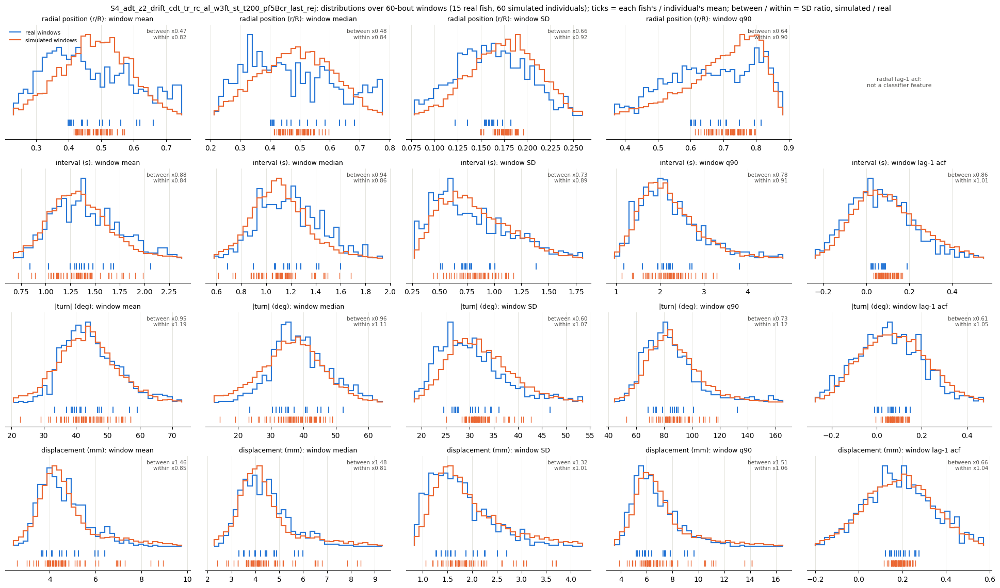


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.20     0.81  0.15  0.08   3.0   3.0                  22.3 +/- 0.9  21.5 +/- 1.0
d2s3.5    1.01     0.84  2.64  4.31  11.0  11.0                  17.4 +/- 0.9  17.8 +/- 0.9
d4s3.5    0.96     0.52  4.68  4.22  19.0   9.0                  18.7 +/- 1.7  17.8 +/- 0.9
d6s3.5    0.81     0.58  4.62  5.25  13.0  11.0                  16.7 +/- 1.3  16.5 +/- 0.9
d8s3.5    1.45     1.35  4.97  2.99  11.0   9.0                  16.3 +/- 1.0  

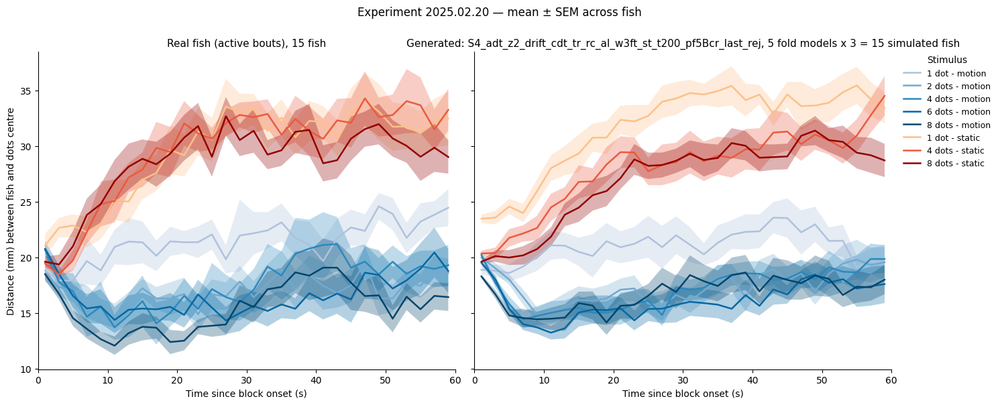


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

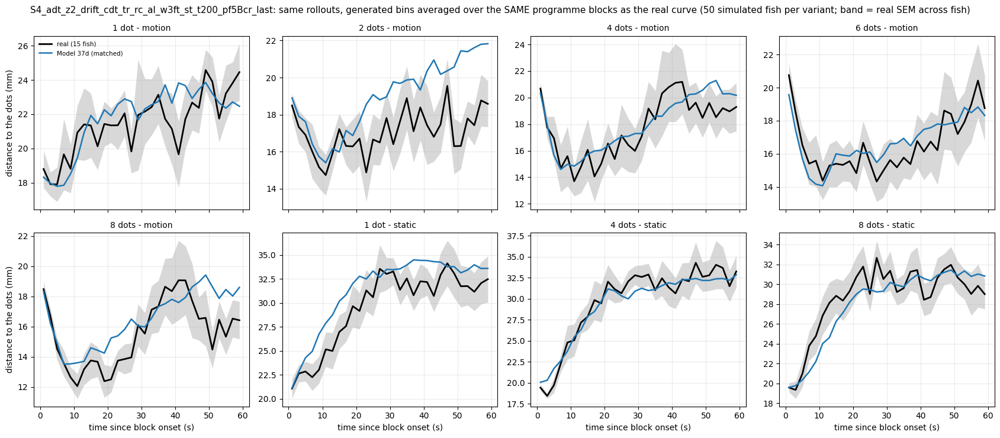


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last                  
           plateau   null attraction                                               plateau   null attraction
cond_label                                                                                                  
d1s3.5       22.41  23.57       1.16                                                 22.71  23.36       0.64
d2s3.5       17.39  23.58       6.19                                                 19.54  23.25       3.72
d4s3.5       18.74  23.93       5.19                                                 19.41  23.06       3.65
d6s3.5       16.69  23.12       6.43                                                 17.60  23.03       5.43
d8s3

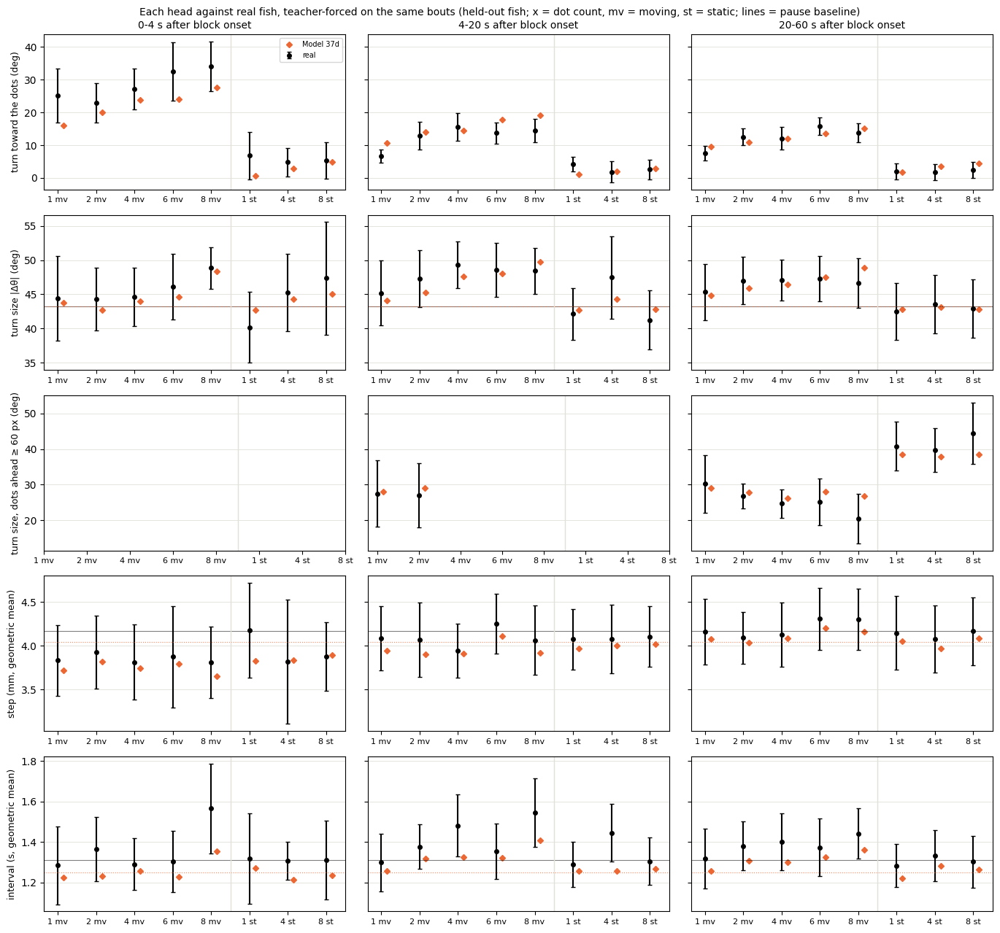

In [22]:
unit_eval.show('37d')

### D4, tau 200 + turn size, seed 0


== held-out likelihood per head (bits per bout)
turn             7.623
displacement     4.510
interval         1.208
joint           13.340

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz.csv  (15 rows) in 1207s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_rej
abs_dtheta_w1                                            

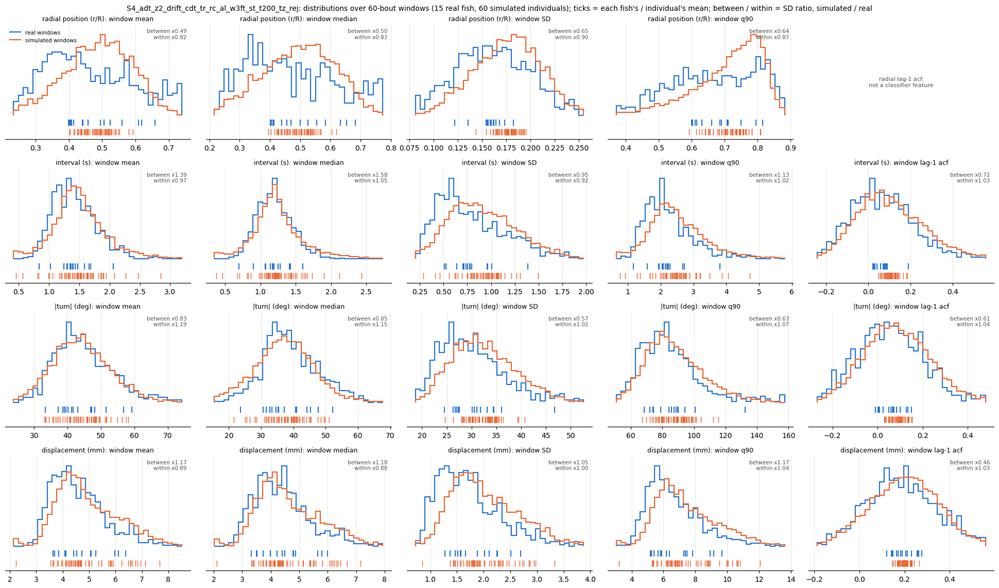


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_fold4.pt: 3 rollouts
dropped 11.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.55     1.06  0.15  0.73   3.0   5.0                  22.3 +/- 0.9  21.3 +/- 1.0
d2s3.5    2.71     2.11  2.64  3.47  11.0  11.0                  17.4 +/- 0.9  20.5 +/- 1.2
d4s3.5    1.84     1.15  4.68  3.55  19.0   7.0                  18.7 +/- 1.7  20.4 +/- 1.0
d6s3.5    1.26     0.92  4.62  3.39  13.0   7.0                  16.7 +/- 1.3  17.4 +/- 0.8
d8s3.5    1.37     1.24  4.97   2.7  11.0   7.0                  16.3 +/- 1.0  16.4 +/- 

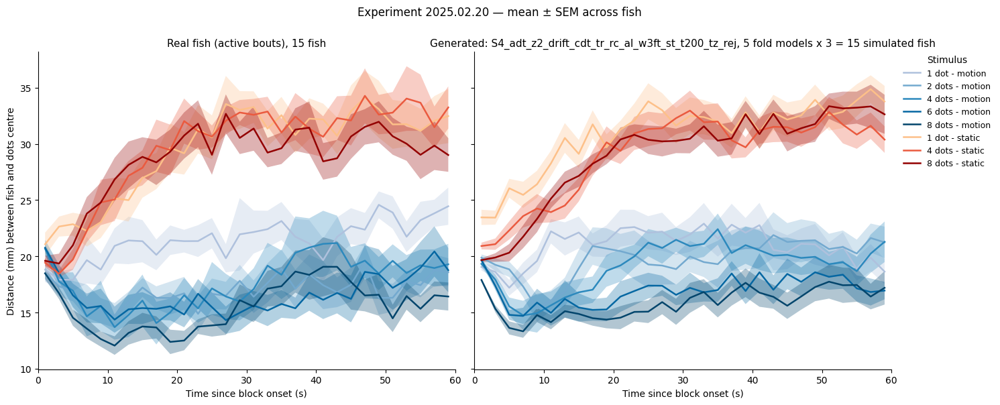


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

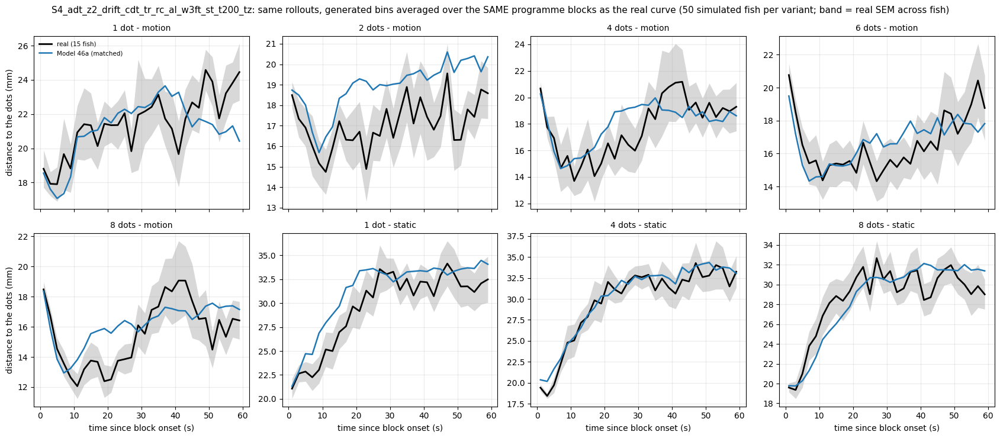


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz                  
           plateau   null attraction                                      plateau   null attraction
cond_label                                                                                         
d1s3.5       22.41  23.57       1.16                                        22.91  23.49       0.58
d2s3.5       17.39  23.58       6.19                                        20.94  23.43       2.49
d4s3.5       18.74  23.93       5.19                                        20.07  23.45       3.38
d6s3.5       16.69  23.12       6.43                                        17.80  23.29       5.48
d8s3.5       16.41  23.36       6.94                               

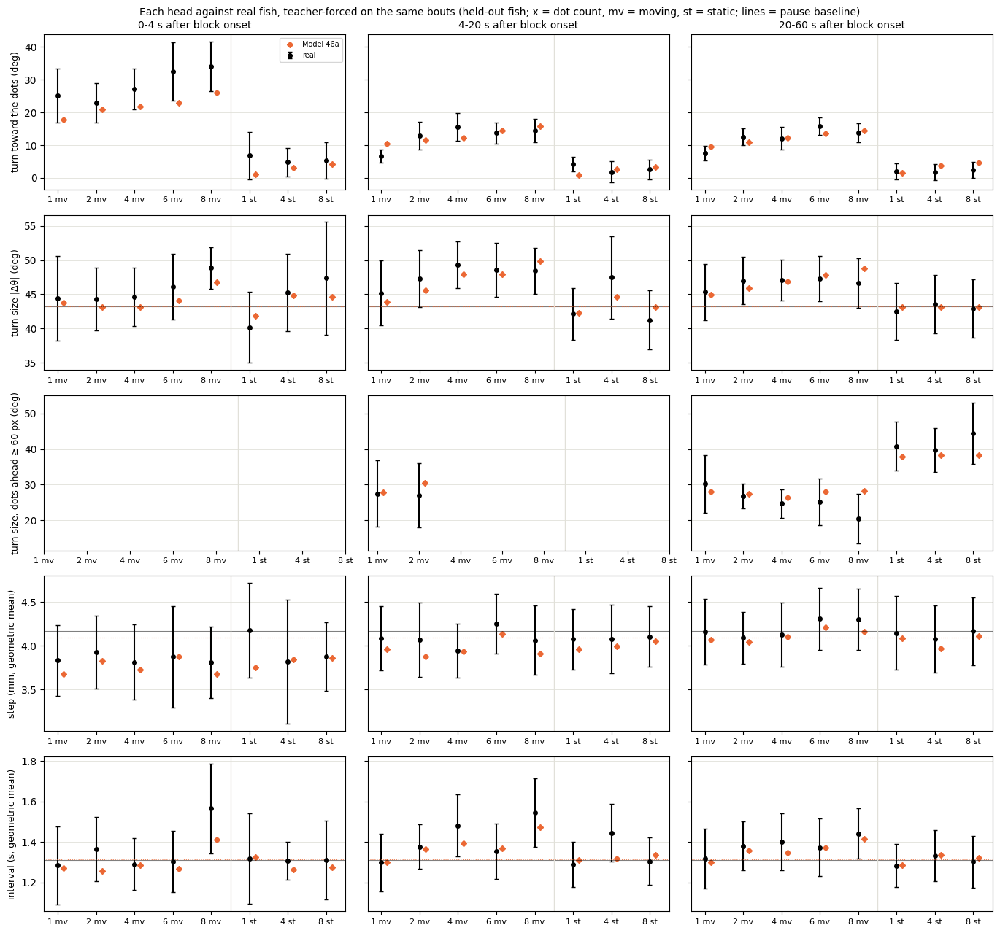

In [23]:
unit_eval.show('46a')

### D4, tau 200 + turn size, seed 101


== held-out likelihood per head (bits per bout)
turn             7.645
displacement     4.514
interval         1.202
joint           13.362

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz.csv  (15 rows) in 1174s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_rej
abs_dtheta_w1                                            

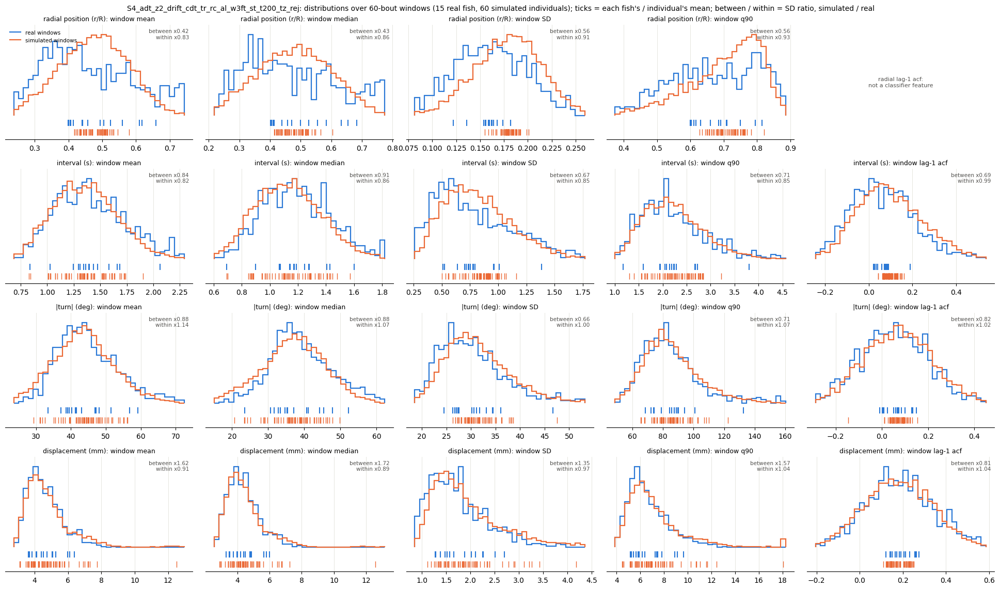


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_fold4.pt: 3 rollouts
dropped 12.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.52     1.04  0.15  0.82   3.0   7.0                  22.3 +/- 0.9  22.5 +/- 1.1
d2s3.5    1.43     1.18  2.64  2.98  11.0   9.0                  17.4 +/- 0.9  18.6 +/- 0.8
d4s3.5    1.11     0.71  4.68  3.88  19.0  19.0                  18.7 +/- 1.7  18.8 +/- 1.4
d6s3.5    1.33     0.96  4.62  5.42  13.0  11.0                  16.7 +/- 1.3  16.7 +/- 1.0
d8s3.5    1.33     0.97  4.97  4.64  11.0  13.0                  16.3 +/- 1.0  15.1 +/- 

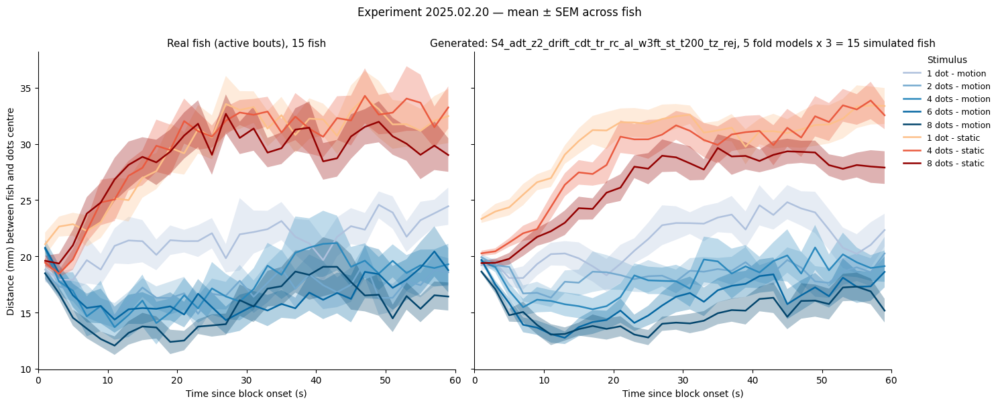


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

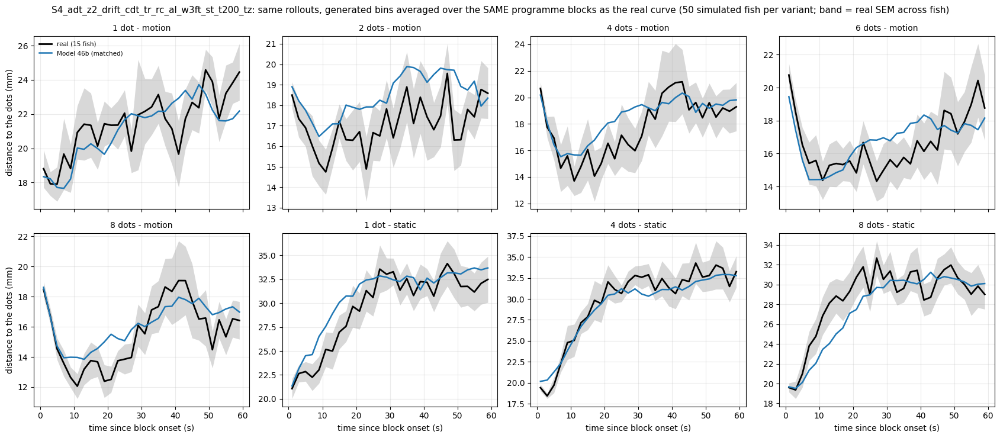


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz                  
           plateau   null attraction                                      plateau   null attraction
cond_label                                                                                         
d1s3.5       22.41  23.57       1.16                                        21.94  23.28       1.34
d2s3.5       17.39  23.58       6.19                                        18.77  22.63       3.86
d4s3.5       18.74  23.93       5.19                                        18.69  22.71       4.03
d6s3.5       16.69  23.12       6.43                                        17.60  22.60       5.00
d8s3.5       16.41  23.36       6.94                               

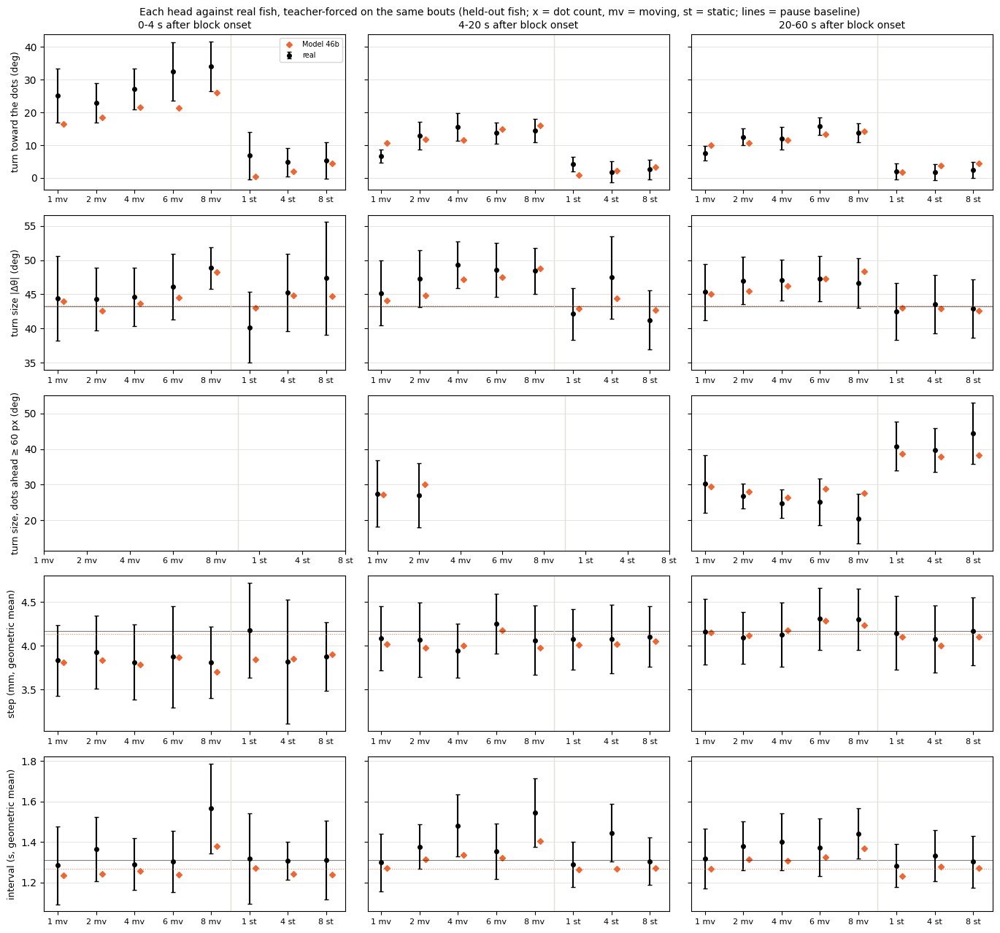

In [24]:
unit_eval.show('46b')

### F, tau 200 + turn size, seed 0


== held-out likelihood per head (bits per bout)
turn             7.624
displacement     4.510
interval         1.208
joint           13.341

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last.csv  (15 rows) in 1184s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_r

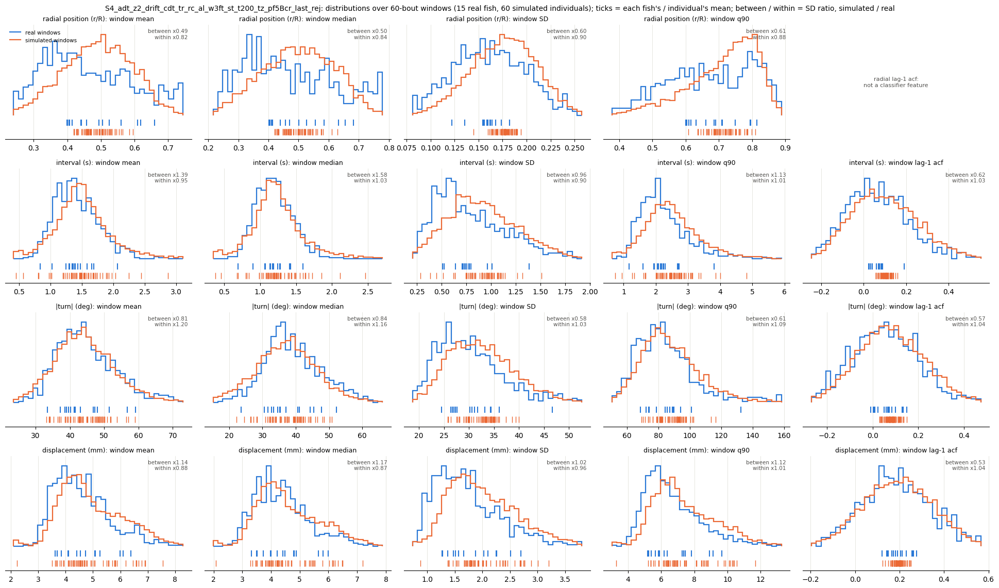


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.22     0.84  0.15  1.48   3.0   5.0                  22.3 +/- 0.9  21.7 +/- 1.2
d2s3.5    2.49     1.87  2.64  1.88  11.0   9.0                  17.4 +/- 0.9  20.5 +/- 1.2
d4s3.5    1.25     0.77  4.68  3.39  19.0   7.0                  18.7 +/- 1.7  18.4 +/- 1.4
d6s3.5    1.60     1.07  4.62  4.29  13.0  11.0                  16.7 +/- 1.3  18.5 +/- 1.2
d8s3.5    1.20     1.05  4.97  3.17  11.0  11.0                  16.3 +/- 1.

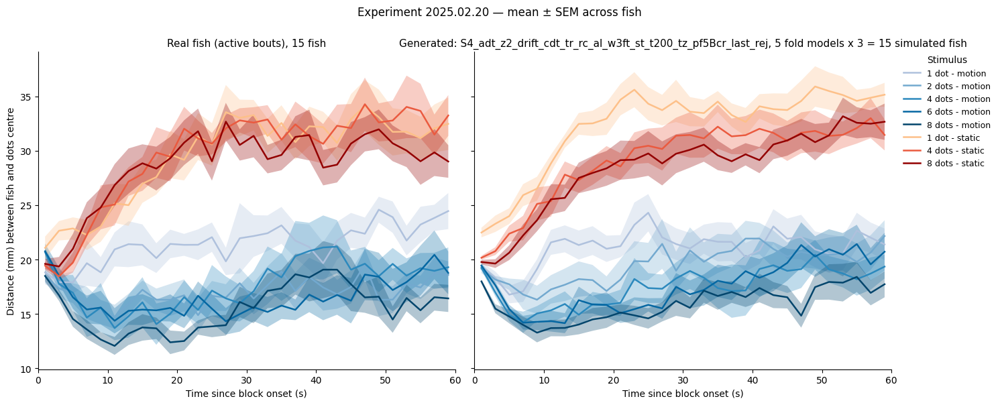


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

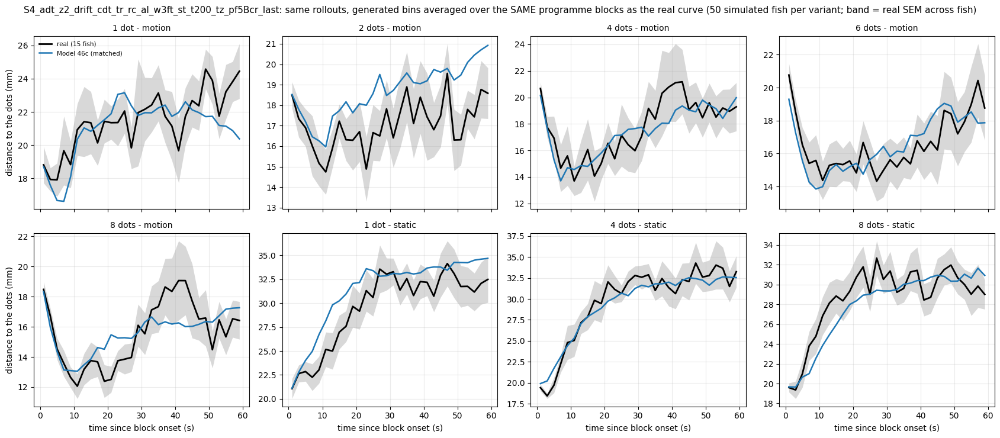


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last                  
           plateau   null attraction                                                  plateau   null attraction
cond_label                                                                                                     
d1s3.5       22.41  23.57       1.16                                                    22.65  23.59       0.94
d2s3.5       17.39  23.58       6.19                                                    20.46  23.45       2.99
d4s3.5       18.74  23.93       5.19                                                    18.80  23.54       4.74
d6s3.5       16.69  23.12       6.43                                                    18.22  

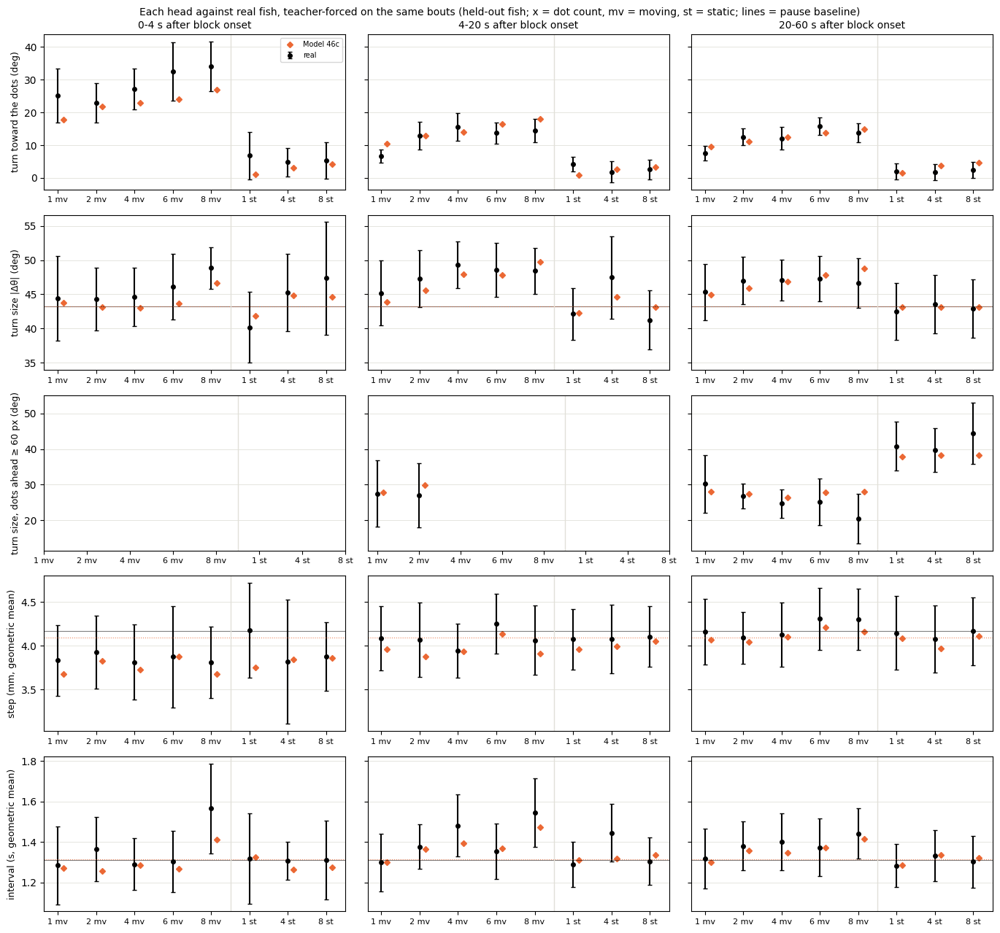

In [25]:
unit_eval.show('46c')

### F, tau 200 + turn size, seed 101


== held-out likelihood per head (bits per bout)
turn             7.646
displacement     4.514
interval         1.202
joint           13.362

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last.csv  (15 rows) in 1150s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_r

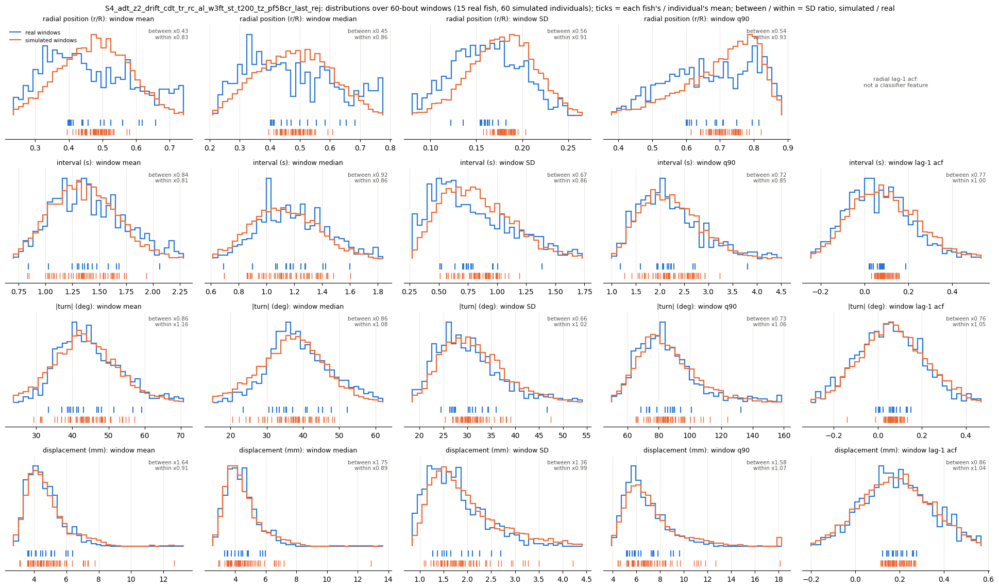


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.3% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.53     1.04  0.15  0.71   3.0   7.0                  22.3 +/- 0.9  20.7 +/- 1.0
d2s3.5    1.39     1.12  2.64  3.82  11.0  13.0                  17.4 +/- 0.9  18.7 +/- 0.7
d4s3.5    1.83     0.99  4.68  5.13  19.0  13.0                  18.7 +/- 1.7  16.7 +/- 0.7
d6s3.5    1.40     0.98  4.62  5.66  13.0  19.0                  16.7 +/- 1.3  16.2 +/- 1.2
d8s3.5    0.94     0.73  4.97  4.29  11.0   9.0                  16.3 +/- 1.

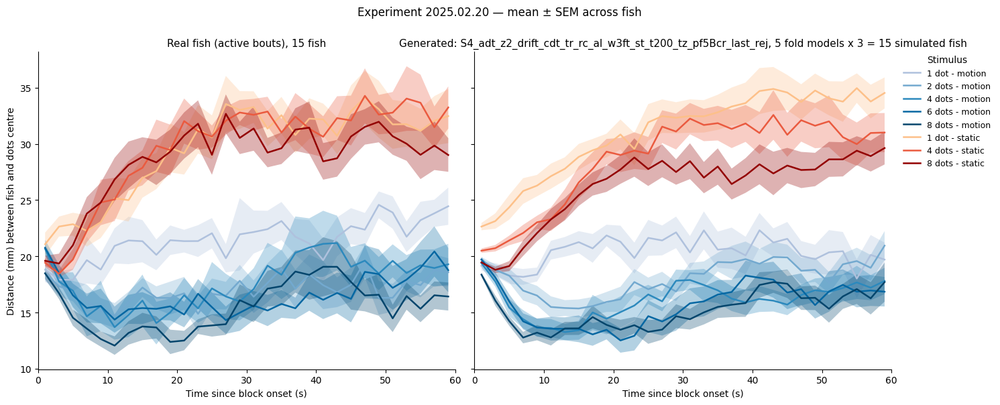


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

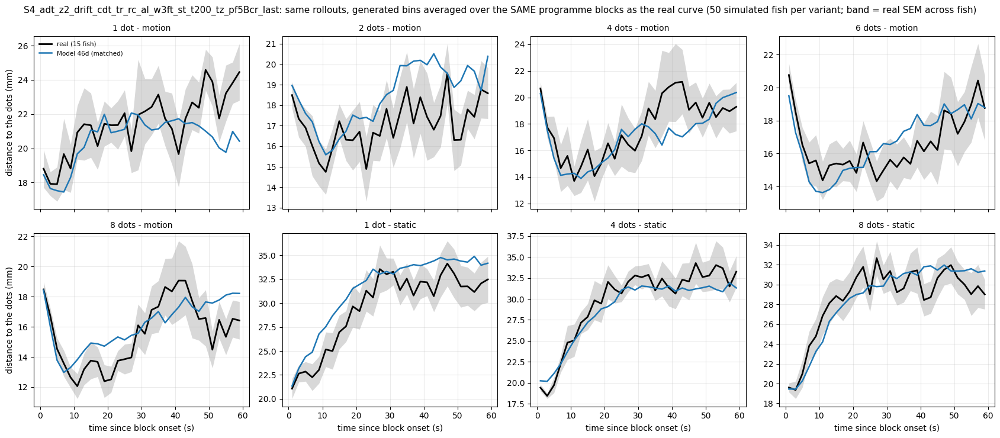


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last                  
           plateau   null attraction                                                  plateau   null attraction
cond_label                                                                                                     
d1s3.5       22.41  23.57       1.16                                                    21.24  22.60       1.35
d2s3.5       17.39  23.58       6.19                                                    19.20  22.86       3.66
d4s3.5       18.74  23.93       5.19                                                    17.68  22.87       5.20
d6s3.5       16.69  23.12       6.43                                                    17.24  

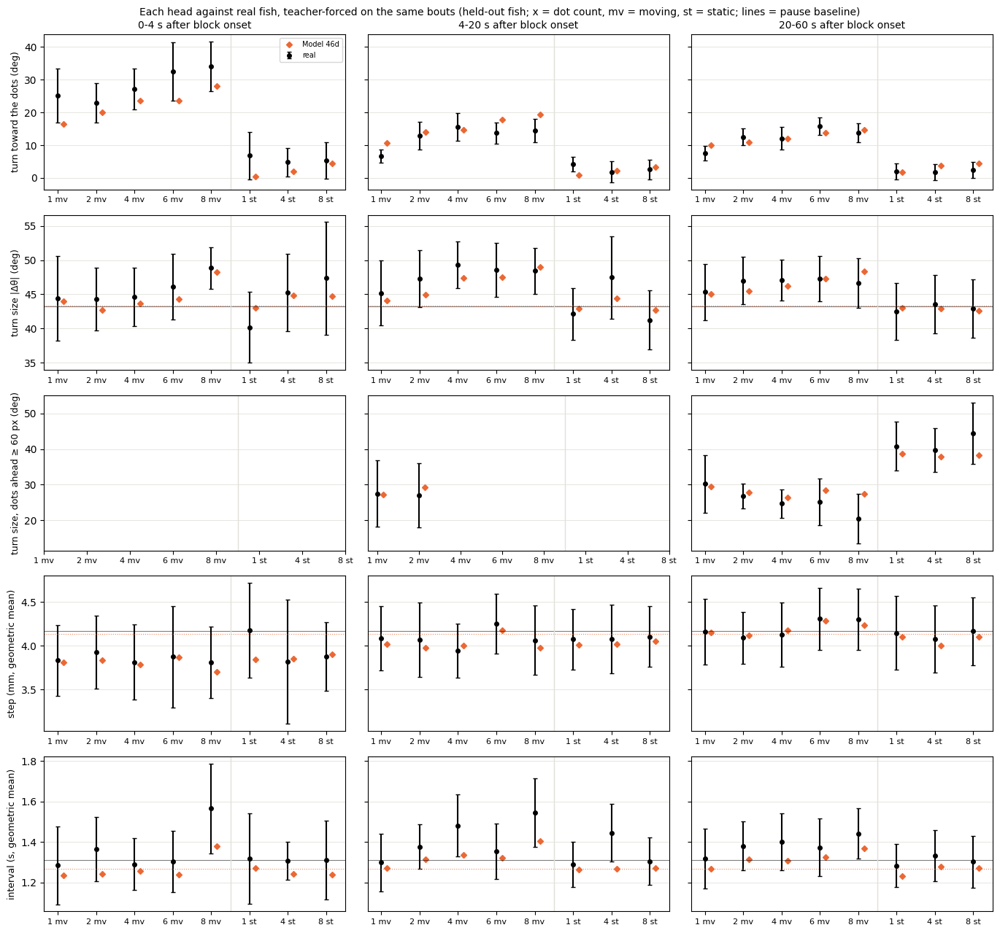

In [26]:
unit_eval.show('46d')

### D4, strength 0, seed 0


== held-out likelihood per head (bits per bout)


turn             7.627
displacement     4.513
interval         1.203
joint           13.344

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 848s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.7362
symbol_js                                                 0.0132
dt_w1           

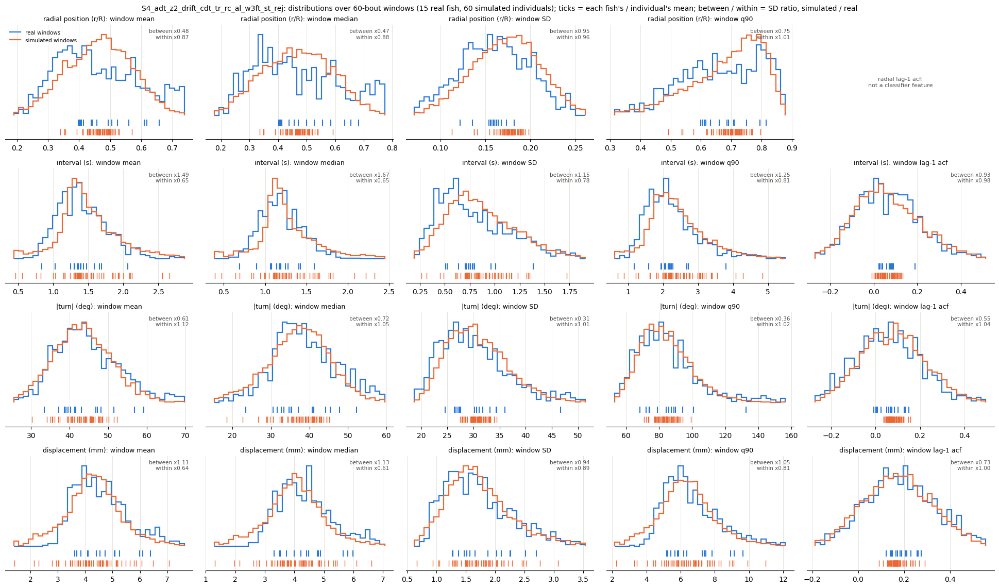


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 10.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.36     0.91  0.15  0.37   3.0   5.0                  22.3 +/- 0.9  20.7 +/- 1.0
d2s3.5    1.16     0.94  2.64  3.59  11.0  19.0                  17.4 +/- 0.9  18.0 +/- 1.0
d4s3.5    1.25     0.69  4.68  4.38  19.0  19.0                  18.7 +/- 1.7  17.2 +/- 1.1
d6s3.5    0.94     0.65  4.62  4.38  13.0  11.0                  16.7 +/- 1.3  16.3 +/- 0.9
d8s3.5    1.03     0.87  4.97  3.49  11.0  11.0                  16.3 +/- 1.0  15.9 +/- 1.1
d1s0

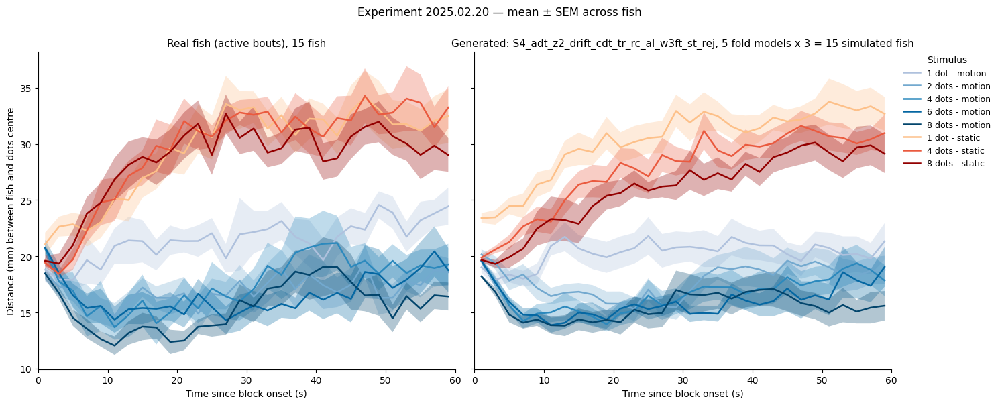


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

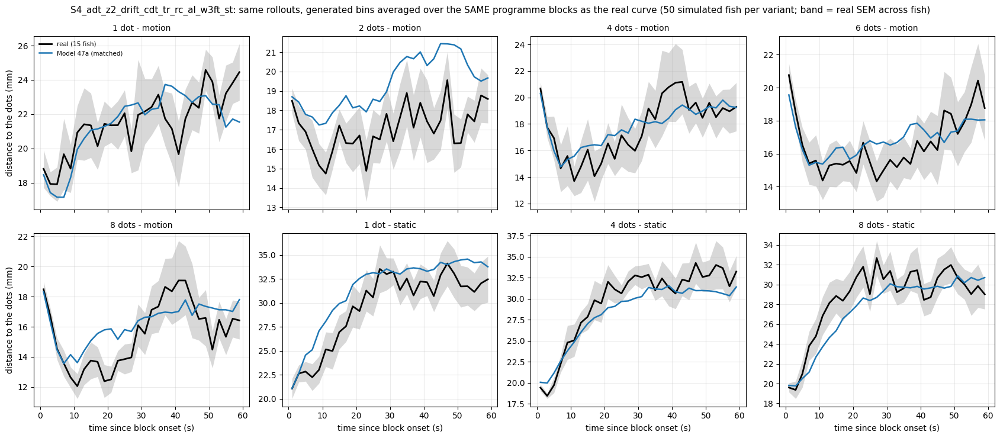


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                21.98  22.48       0.50
d2s3.5       17.39  23.58       6.19                                19.09  22.28       3.19
d4s3.5       18.74  23.93       5.19                                18.20  22.44       4.24
d6s3.5       16.69  23.12       6.43                                16.99  22.24       5.25
d8s3.5       16.41  23.36       6.94                                16.71  22.36       5.64

== turn toward the moving dots

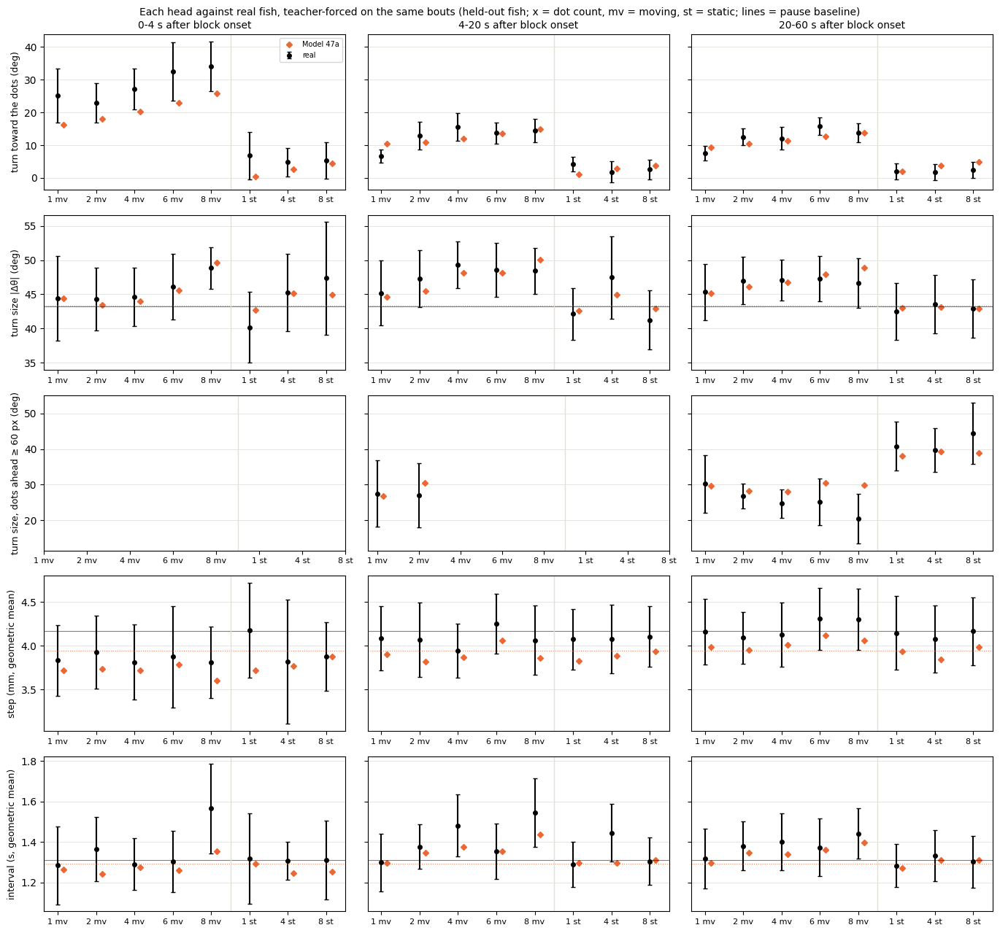

In [27]:
unit_eval.show('47a')

### D4, strength 0, seed 101


== held-out likelihood per head (bits per bout)


turn             7.630
displacement     4.520
interval         1.207
joint           13.356

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 831s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.2513
symbol_js                                                 0.0124
dt_w1           

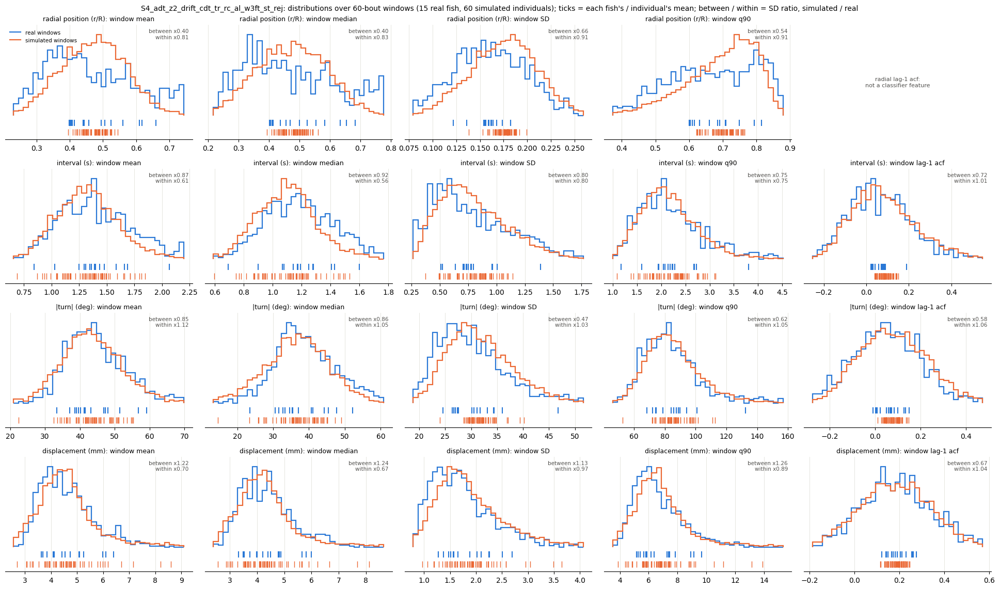


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 10.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.15     0.77  0.15  1.49   3.0   7.0                  22.3 +/- 0.9  21.8 +/- 1.2
d2s3.5    1.98     1.50  2.64  3.15  11.0  11.0                  17.4 +/- 0.9  19.8 +/- 1.2
d4s3.5    1.45     0.91  4.68  3.13  19.0   9.0                  18.7 +/- 1.7  18.7 +/- 0.9
d6s3.5    1.20     0.78  4.62  4.84  13.0  11.0                  16.7 +/- 1.3  16.6 +/- 0.7
d8s3.5    1.54     1.42  4.97  3.48  11.0   9.0                  16.3 +/- 1.0  17.1 +/- 0.9
d1s0

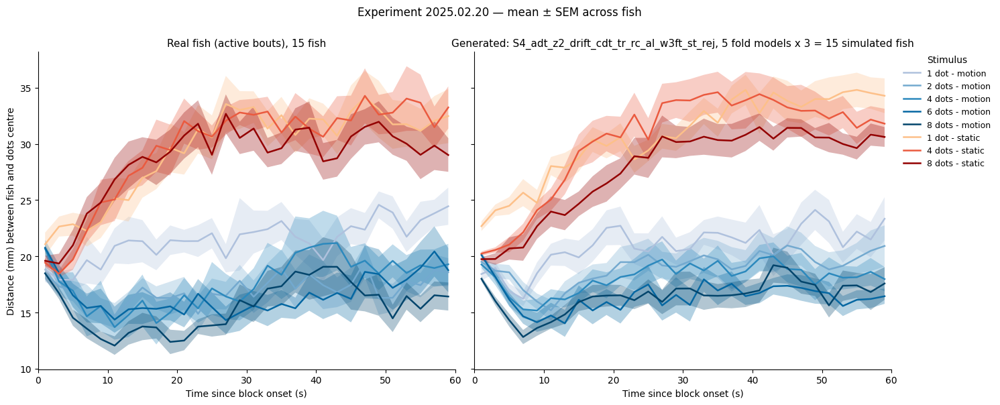


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

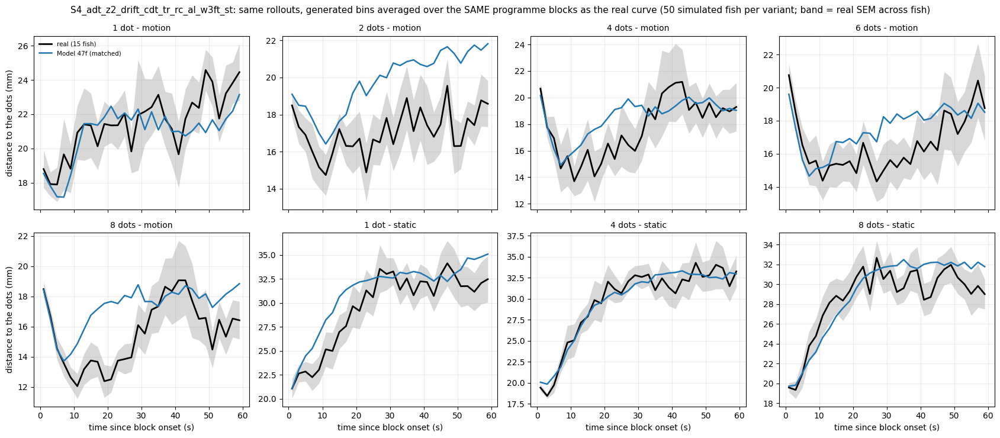


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                21.54  22.64       1.10
d2s3.5       17.39  23.58       6.19                                20.13  22.43       2.31
d4s3.5       18.74  23.93       5.19                                19.47  22.48       3.01
d6s3.5       16.69  23.12       6.43                                17.79  22.68       4.88
d8s3.5       16.41  23.36       6.94                                17.59  22.64       5.05

== turn toward the moving dots

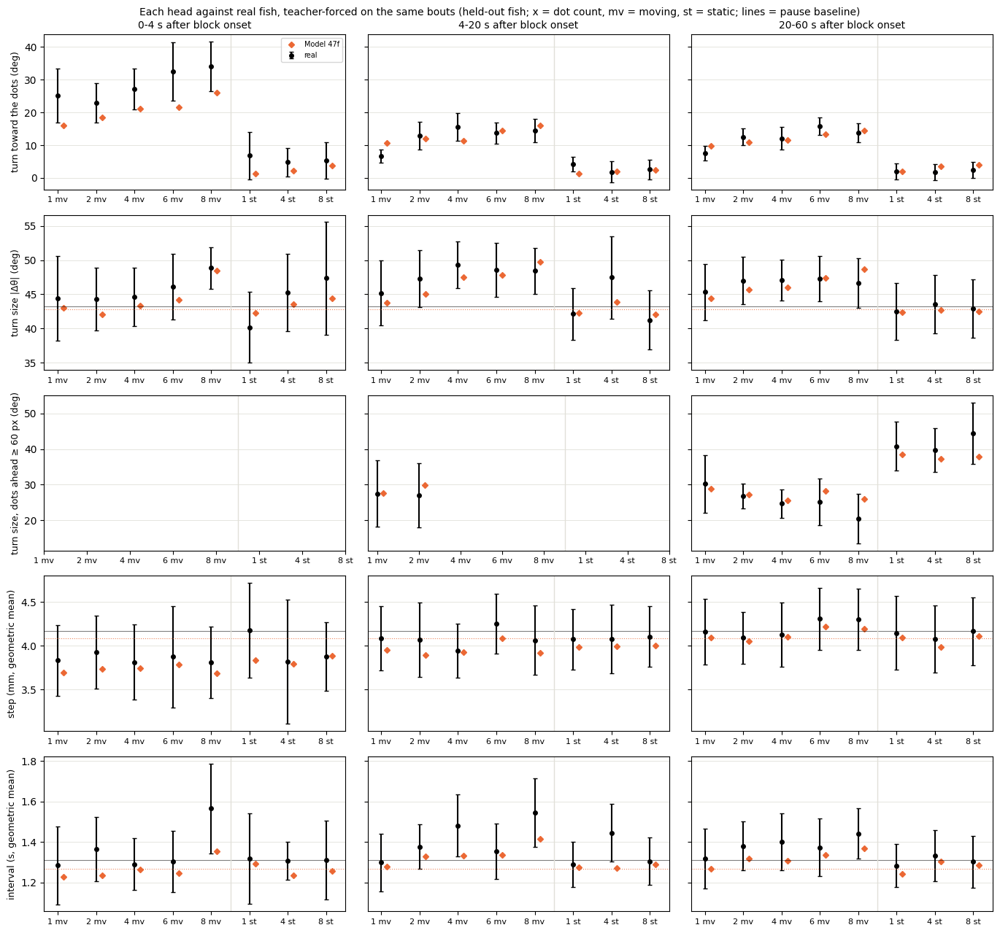

In [28]:
unit_eval.show('47f')

### D4, tau 70, half, seed 0


== held-out likelihood per head (bits per bout)


turn             7.627
displacement     4.513
interval         1.203
joint           13.344

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 831s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.7579
symbol_js                                                 0.0132
dt_w1           

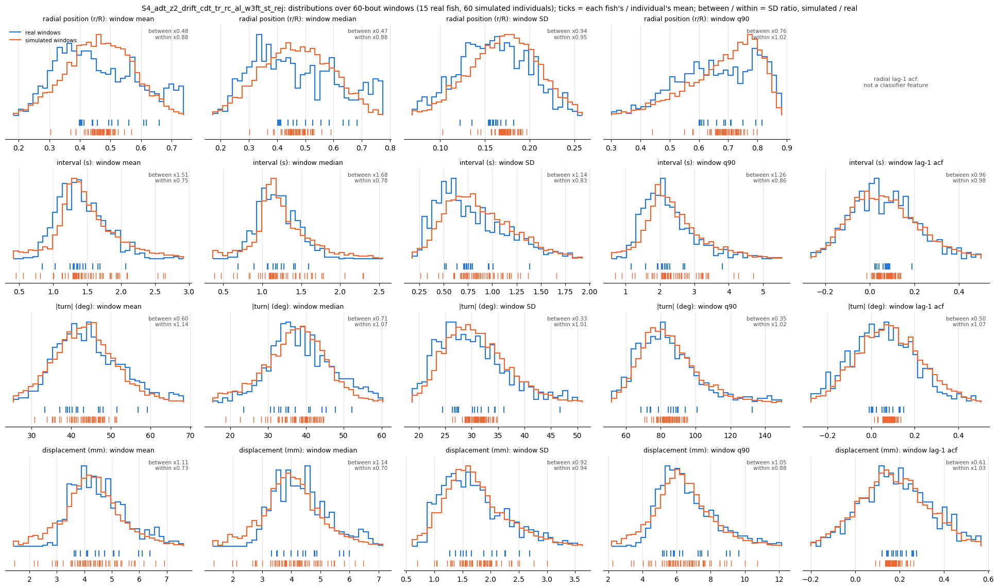


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 9.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.15     0.79  0.15  1.06   3.0   5.0                  22.3 +/- 0.9  21.6 +/- 0.9
d2s3.5    1.22     0.96  2.64  2.36  11.0  11.0                  17.4 +/- 0.9  18.1 +/- 0.9
d4s3.5    1.66     0.94  4.68  3.25  19.0   9.0                  18.7 +/- 1.7  17.3 +/- 0.9
d6s3.5    1.28     0.94  4.62  4.42  13.0  19.0                  16.7 +/- 1.3  17.2 +/- 1.0
d8s3.5    1.51     1.48  4.97  3.11  11.0   9.0                  16.3 +/- 1.0  17.1 +/- 1.1
d1s0 

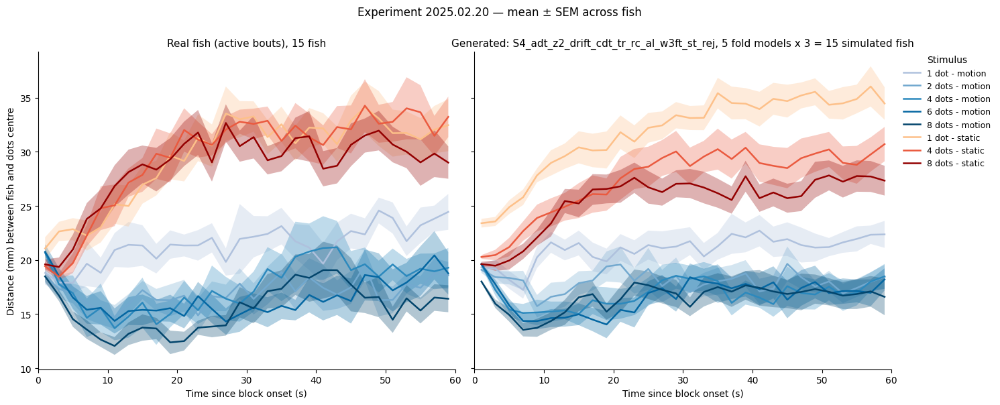


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

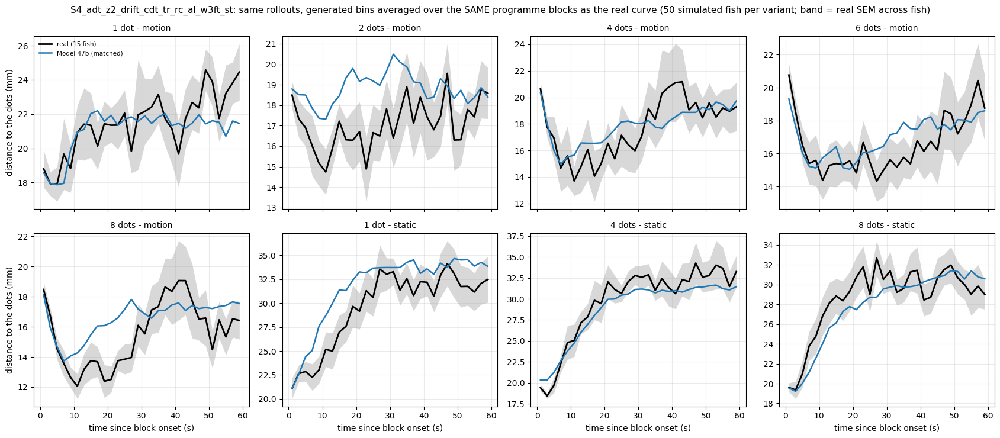


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                21.48  22.48       1.01
d2s3.5       17.39  23.58       6.19                                19.22  22.54       3.32
d4s3.5       18.74  23.93       5.19                                18.59  22.23       3.65
d6s3.5       16.69  23.12       6.43                                17.14  22.23       5.09
d8s3.5       16.41  23.36       6.94                                17.12  22.22       5.10

== turn toward the moving dots

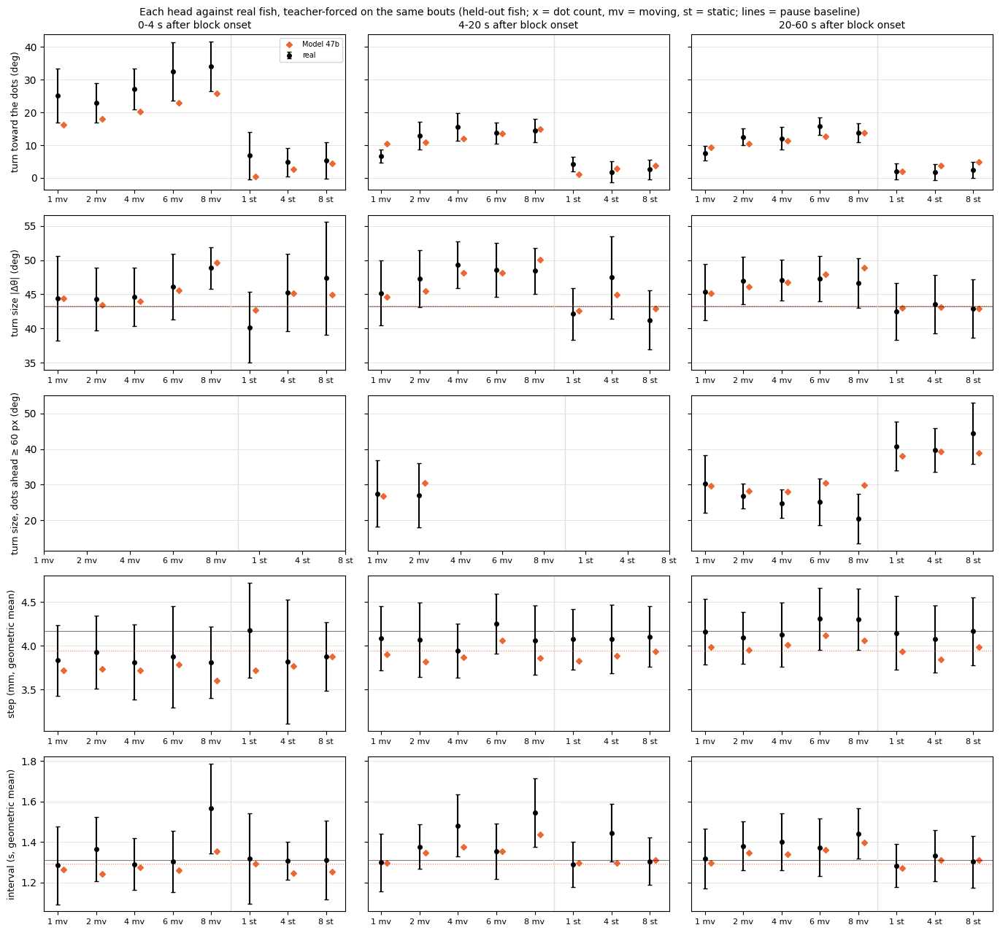

In [29]:
unit_eval.show('47b')

### D4, tau 70, half, seed 101


== held-out likelihood per head (bits per bout)


turn             7.630
displacement     4.520
interval         1.207
joint           13.356

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 591s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.1677
symbol_js                                                 0.0124
dt_w1           

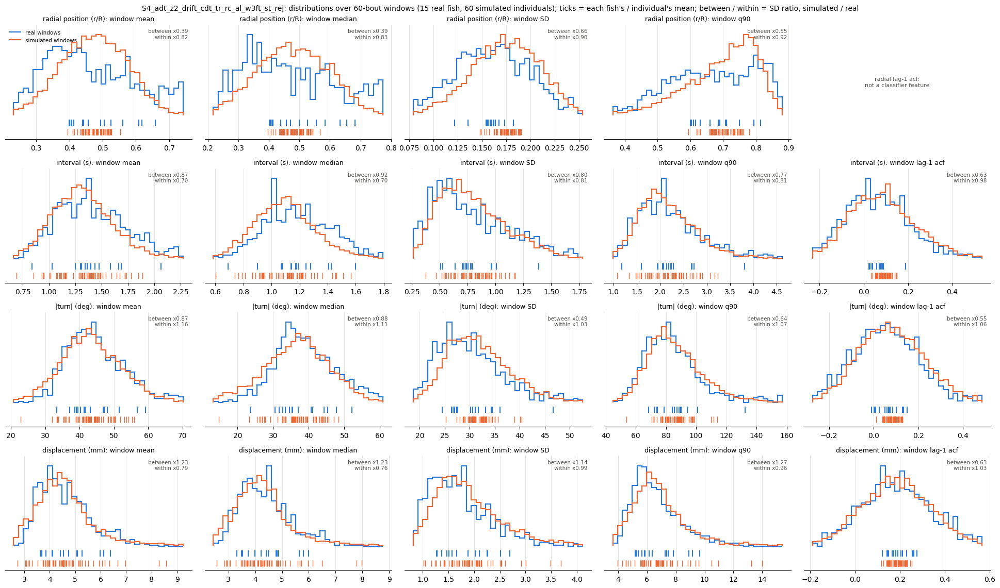


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 12.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.37     0.90  0.15  0.84   3.0   5.0                  22.3 +/- 0.9  21.4 +/- 1.0
d2s3.5    2.18     1.67  2.64   2.6  11.0  11.0                  17.4 +/- 0.9  19.9 +/- 1.0
d4s3.5    1.57     0.94  4.68  4.08  19.0   9.0                  18.7 +/- 1.7  18.1 +/- 0.8
d6s3.5    1.68     1.21  4.62   3.1  13.0   7.0                  16.7 +/- 1.3  18.8 +/- 1.2
d8s3.5    1.28     1.26  4.97  3.73  11.0  11.0                  16.3 +/- 1.0  17.4 +/- 0.7
d1s0

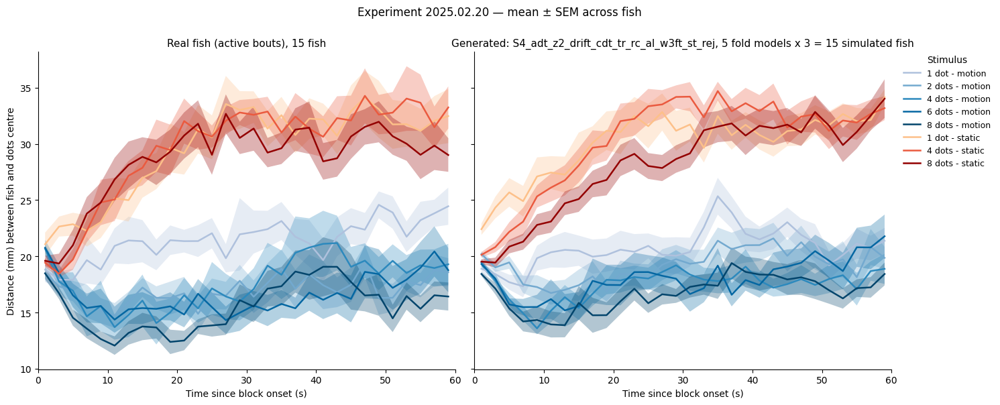


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

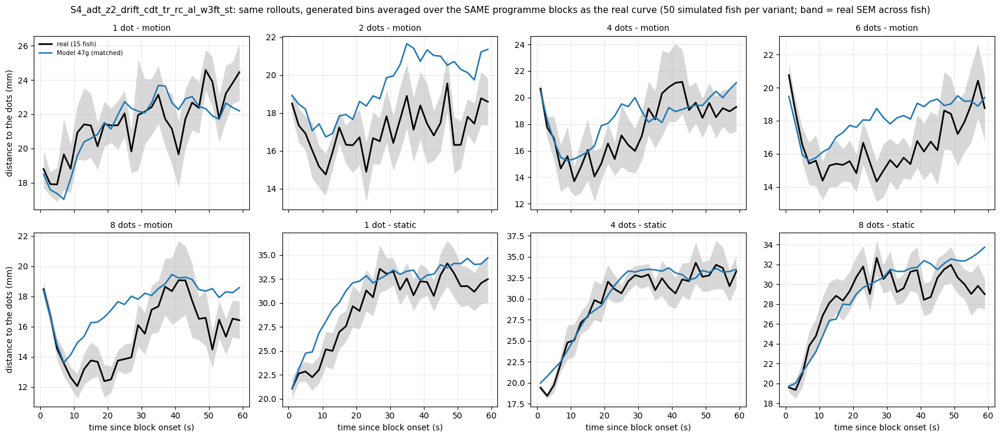


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                22.17  22.57       0.41
d2s3.5       17.39  23.58       6.19                                19.80  22.71       2.92
d4s3.5       18.74  23.93       5.19                                19.20  22.45       3.25
d6s3.5       16.69  23.12       6.43                                18.53  22.65       4.12
d8s3.5       16.41  23.36       6.94                                17.70  22.69       4.99

== turn toward the moving dots

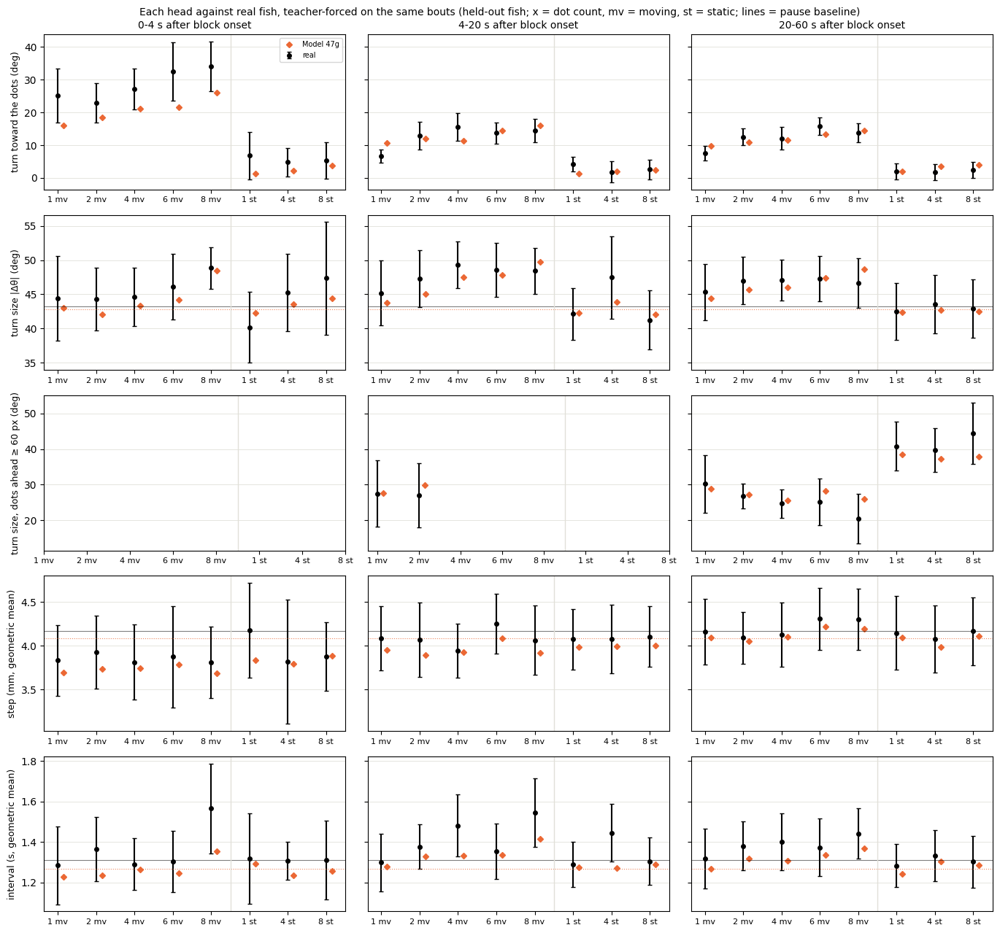

In [30]:
unit_eval.show('47g')

### D4, tau 70, full, seed 0


== held-out likelihood per head (bits per bout)


turn             7.627
displacement     4.513
interval         1.203
joint           13.344

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 820s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.7513
symbol_js                                                 0.0134
dt_w1           

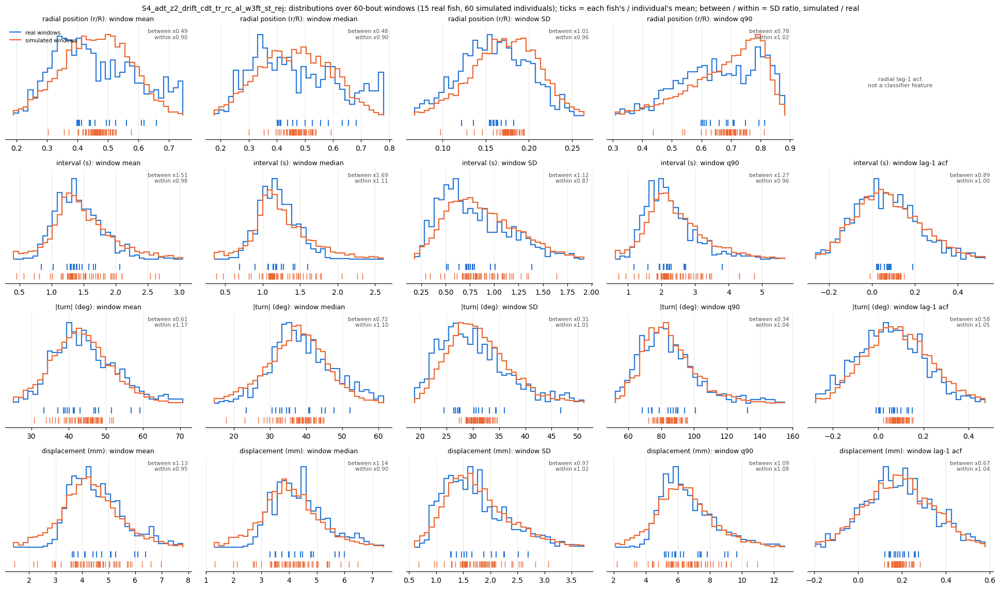


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 9.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.54     1.04  0.15  0.83   3.0   5.0                  22.3 +/- 0.9  20.7 +/- 0.8
d2s3.5    1.32     1.05  2.64   2.8  11.0   9.0                  17.4 +/- 0.9  18.4 +/- 0.9
d4s3.5    1.30     0.71  4.68  3.68  19.0   7.0                  18.7 +/- 1.7  17.6 +/- 0.9
d6s3.5    1.23     0.86  4.62  3.83  13.0  19.0                  16.7 +/- 1.3  17.8 +/- 1.0
d8s3.5    1.45     1.25  4.97  4.38  11.0   9.0                  16.3 +/- 1.0  16.3 +/- 0.9
d1s0 

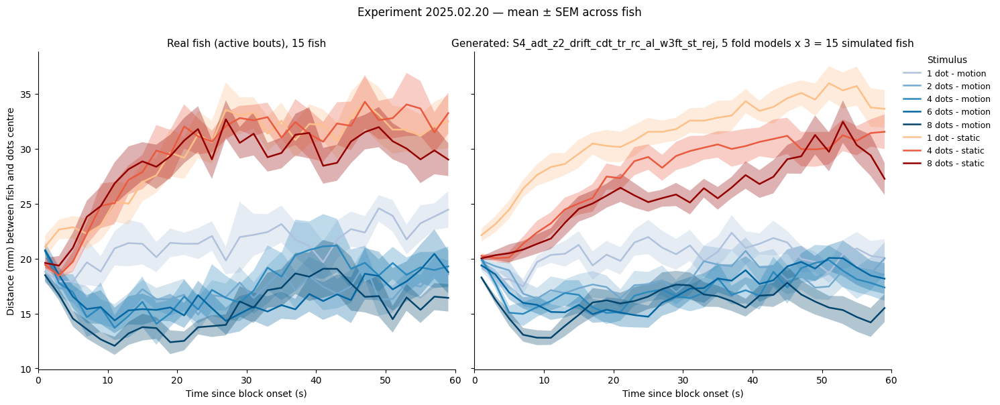


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

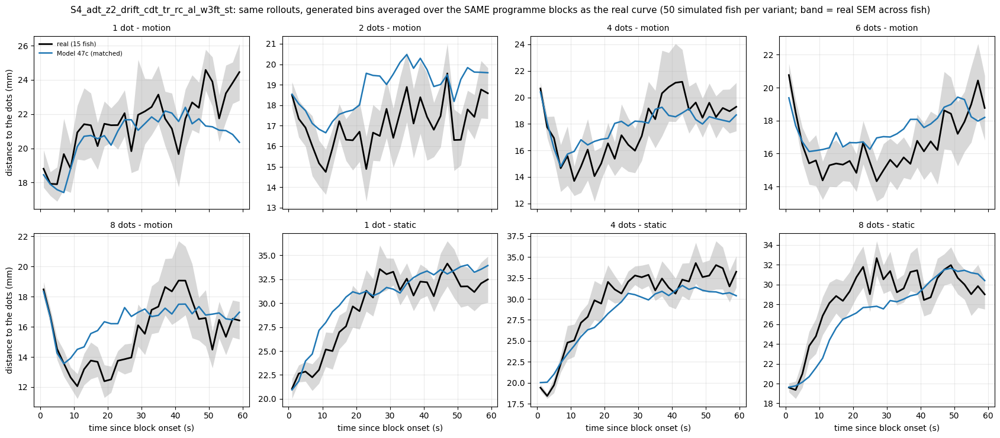


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                21.42  22.35       0.93
d2s3.5       17.39  23.58       6.19                                19.20  22.45       3.25
d4s3.5       18.74  23.93       5.19                                18.26  22.11       3.85
d6s3.5       16.69  23.12       6.43                                18.01  22.29       4.29
d8s3.5       16.41  23.36       6.94                                16.55  22.10       5.55

== turn toward the moving dots

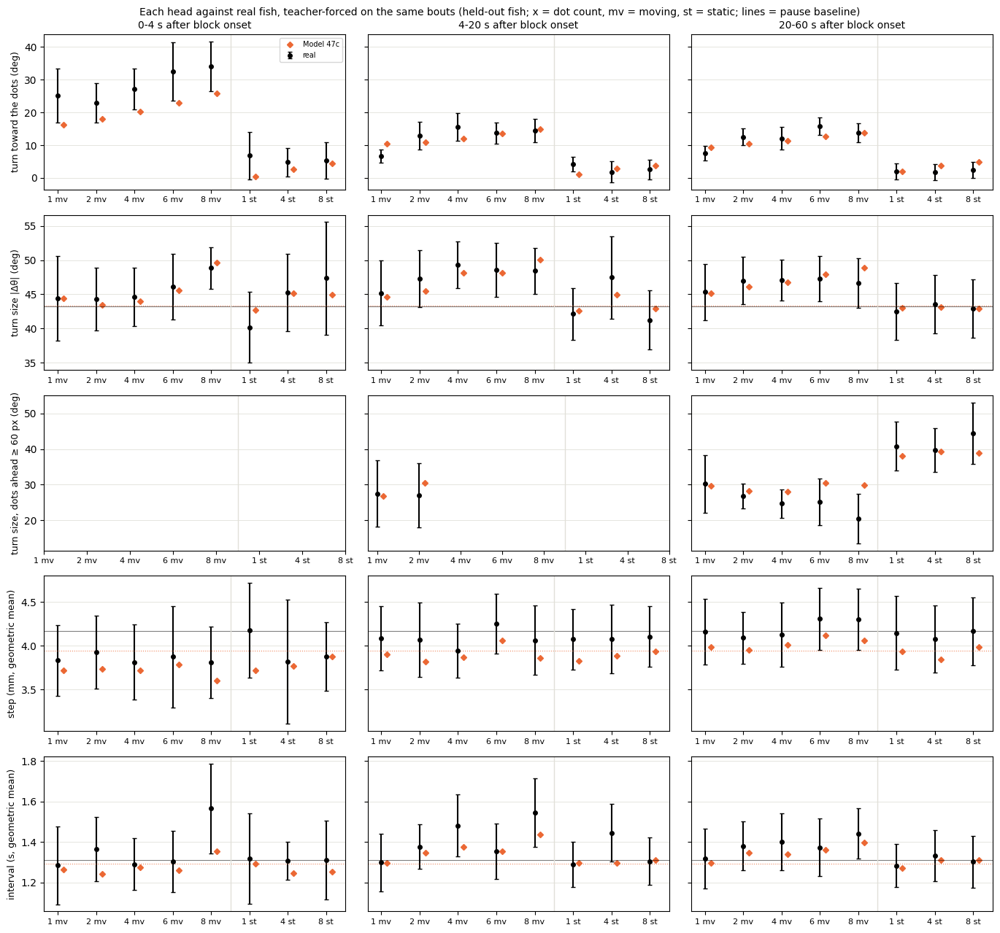

In [31]:
unit_eval.show('47c')

### D4, tau 70, full, seed 101


== held-out likelihood per head (bits per bout)


turn             7.630
displacement     4.520
interval         1.207
joint           13.356

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 593s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.2687
symbol_js                                                 0.0125
dt_w1           

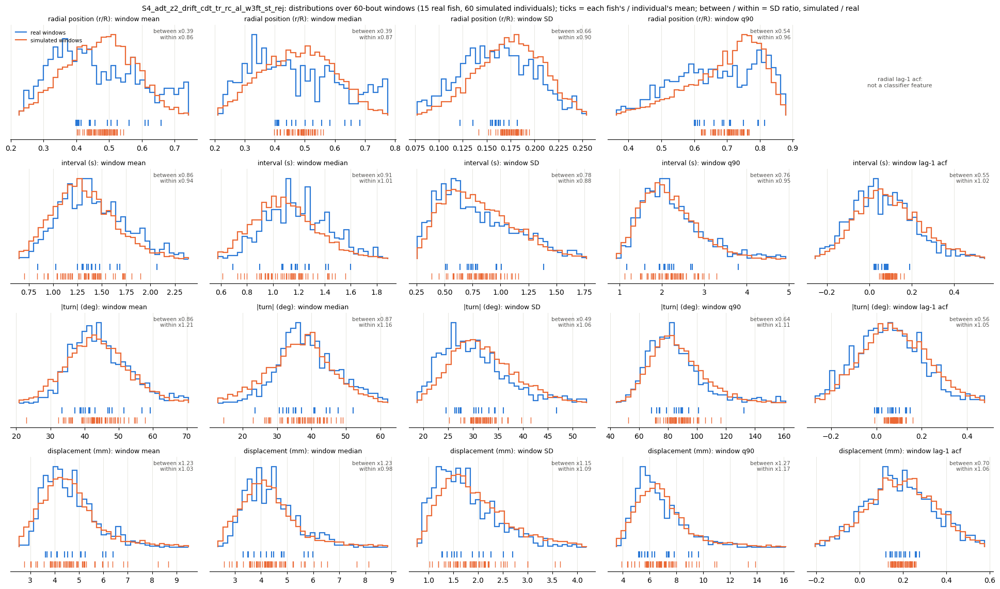


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 10.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.49     0.99  0.15   0.5   3.0   5.0                  22.3 +/- 0.9  23.6 +/- 0.9
d2s3.5    1.56     1.28  2.64  2.52  11.0  11.0                  17.4 +/- 0.9  18.5 +/- 0.9
d4s3.5    1.23     0.71  4.68  4.28  19.0   9.0                  18.7 +/- 1.7  18.8 +/- 0.6
d6s3.5    1.41     1.00  4.62  3.24  13.0   9.0                  16.7 +/- 1.3  17.0 +/- 0.9
d8s3.5    2.00     1.87  4.97  3.05  11.0   9.0                  16.3 +/- 1.0  17.4 +/- 0.9
d1s0

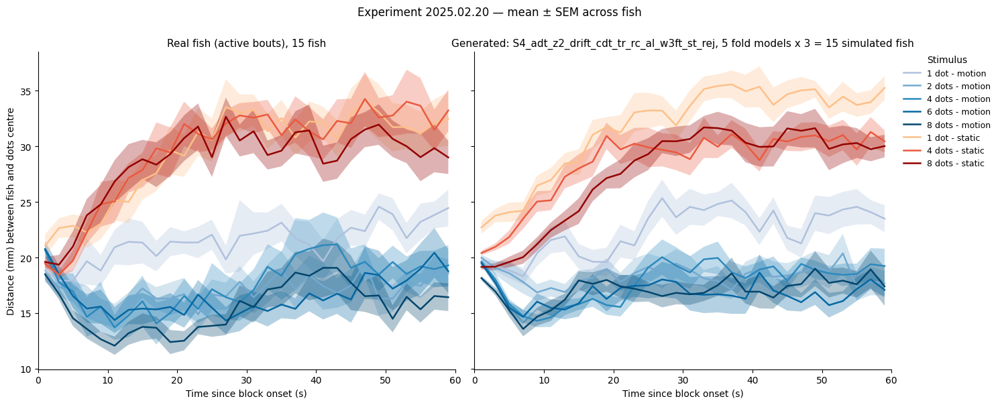


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

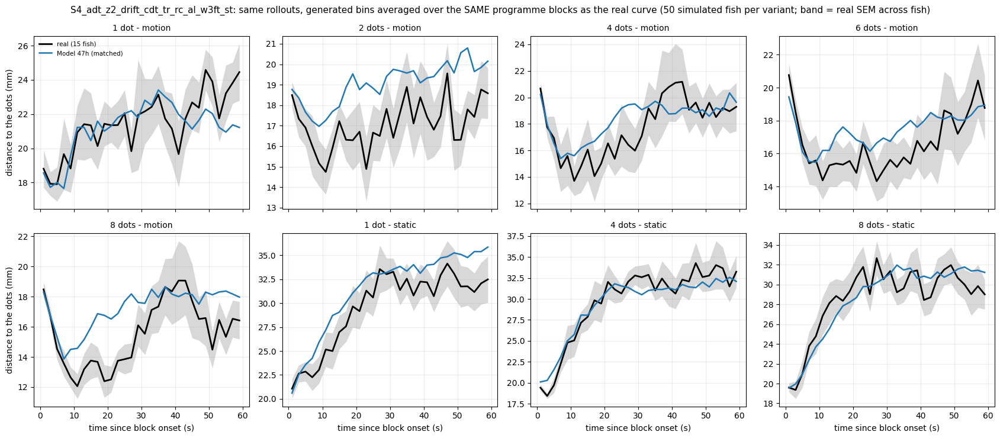


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                22.56  22.34      -0.23
d2s3.5       17.39  23.58       6.19                                18.88  22.24       3.36
d4s3.5       18.74  23.93       5.19                                19.37  22.57       3.20
d6s3.5       16.69  23.12       6.43                                18.29  22.38       4.09
d8s3.5       16.41  23.36       6.94                                17.84  22.35       4.51

== turn toward the moving dots

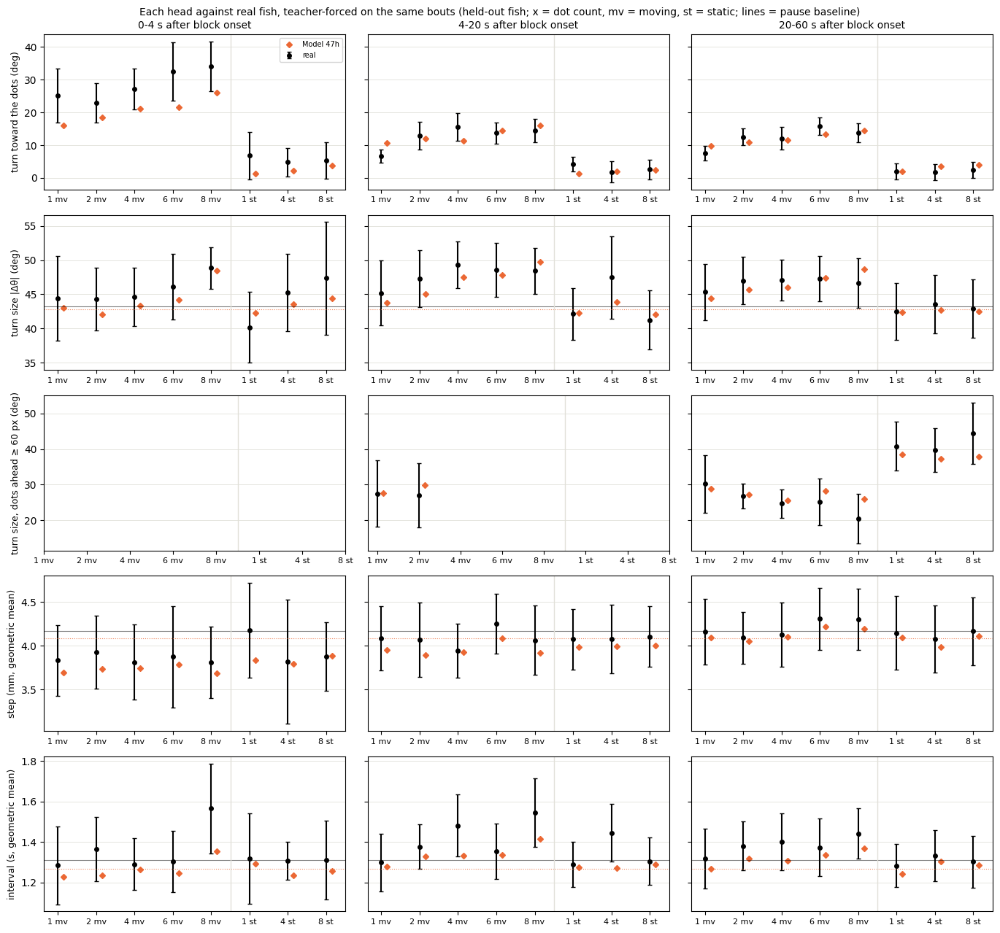

In [32]:
unit_eval.show('47h')

### D4, tau 200, half, seed 0


== held-out likelihood per head (bits per bout)


turn             7.626
displacement     4.515
interval         1.205
joint           13.347

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv  (15 rows) in 860s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_rej
abs_dtheta_w1                                                  9.0323
symbol_js                                          

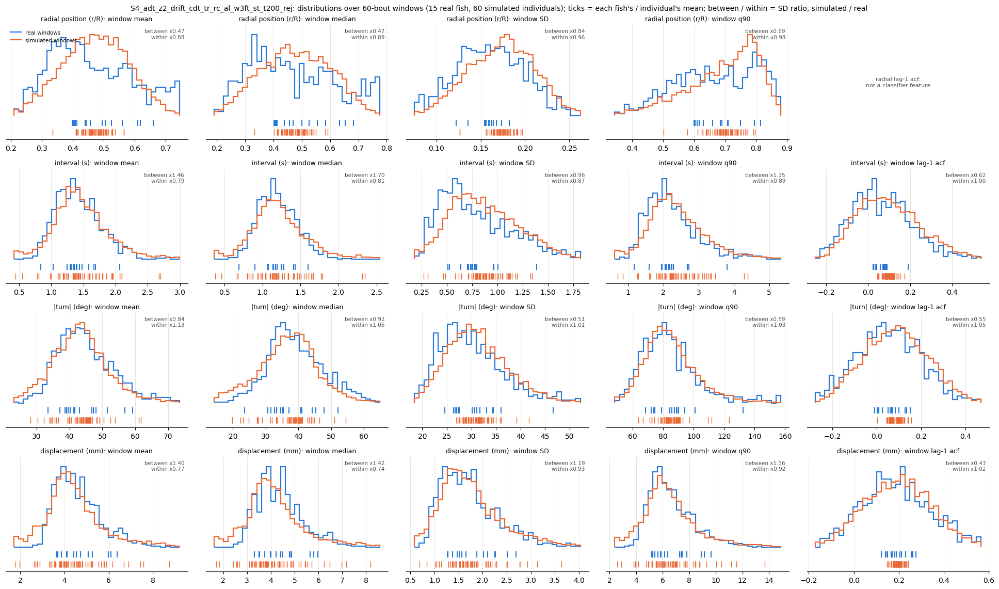


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold4.pt: 3 rollouts
dropped 9.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.22     0.78  0.15  0.89   3.0   5.0                  22.3 +/- 0.9  21.6 +/- 1.1
d2s3.5    0.93     0.76  2.64  3.03  11.0  11.0                  17.4 +/- 0.9  17.8 +/- 0.9
d4s3.5    1.56     0.90  4.68  5.66  19.0  13.0                  18.7 +/- 1.7  17.2 +/- 0.9
d6s3.5    1.15     0.79  4.62  4.25  13.0  13.0                  16.7 +/- 1.3  16.7 +/- 0.8
d8s3.5    1.36     1.05  4.97  3.92  11.0   9.0                  16.3 +/- 1.0  15.5 +/- 0.7


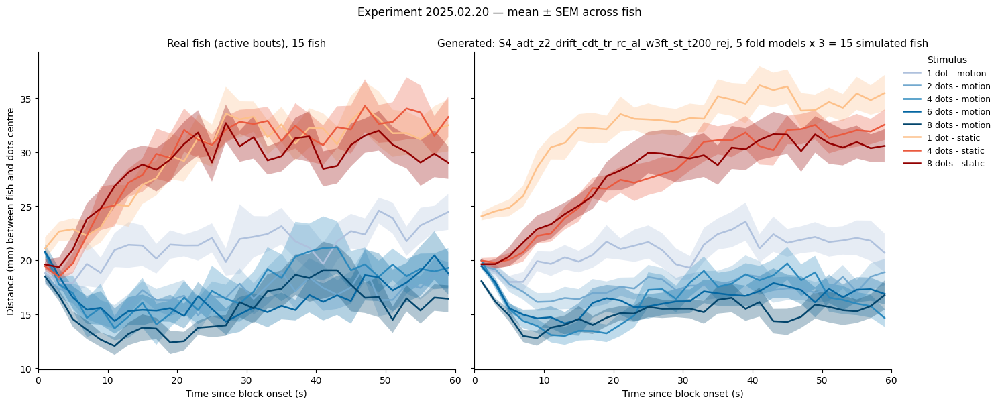


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

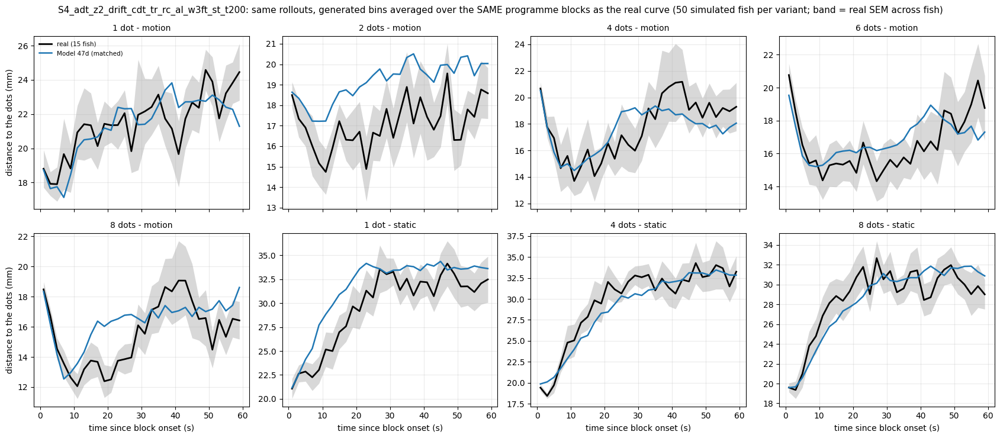


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200                  
           plateau   null attraction                                   plateau   null attraction
cond_label                                                                                      
d1s3.5       22.41  23.57       1.16                                     22.88  22.80      -0.08
d2s3.5       17.39  23.58       6.19                                     19.82  22.65       2.83
d4s3.5       18.74  23.93       5.19                                     18.18  22.76       4.59
d6s3.5       16.69  23.12       6.43                                     17.28  22.59       5.30
d8s3.5       16.41  23.36       6.94                                     17.05  22.76   

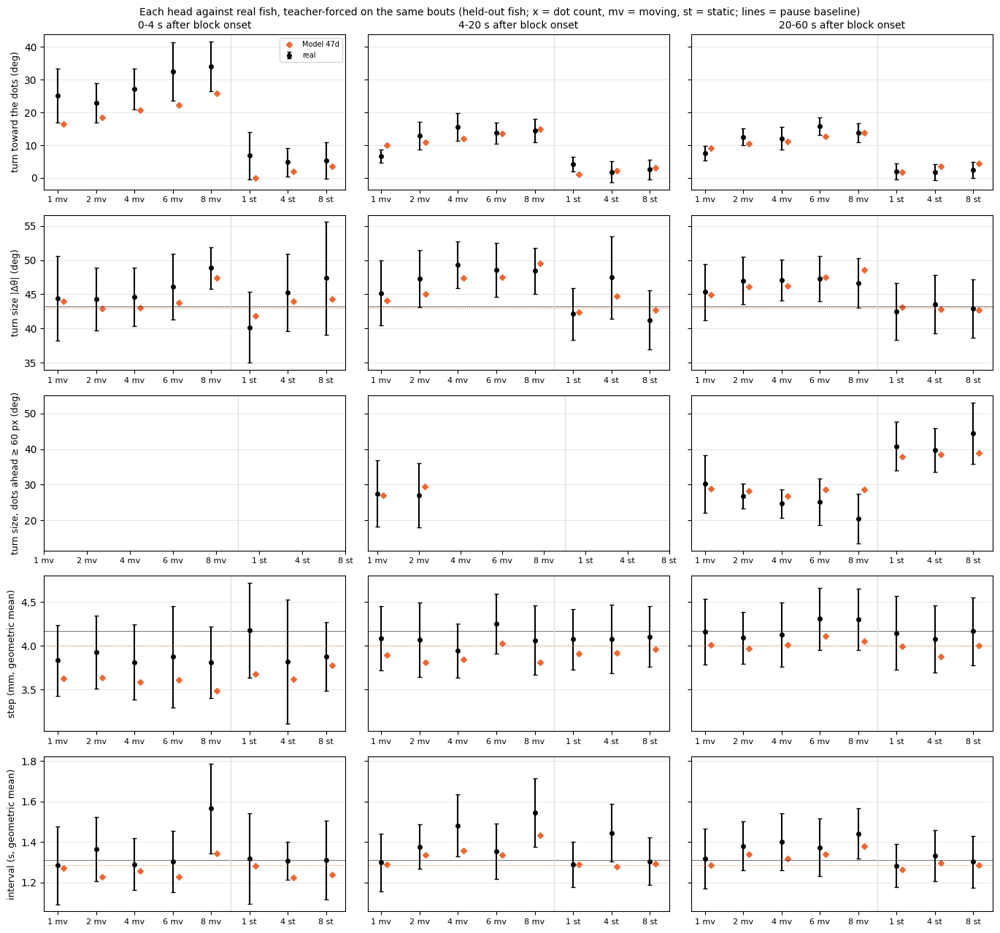

In [33]:
unit_eval.show('47d')

### D4, tau 200, half, seed 101


== held-out likelihood per head (bits per bout)


turn             7.628
displacement     4.503
interval         1.213
joint           13.344

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv  (15 rows) in 590s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_rej
abs_dtheta_w1                                                  8.7686
symbol_js                                          

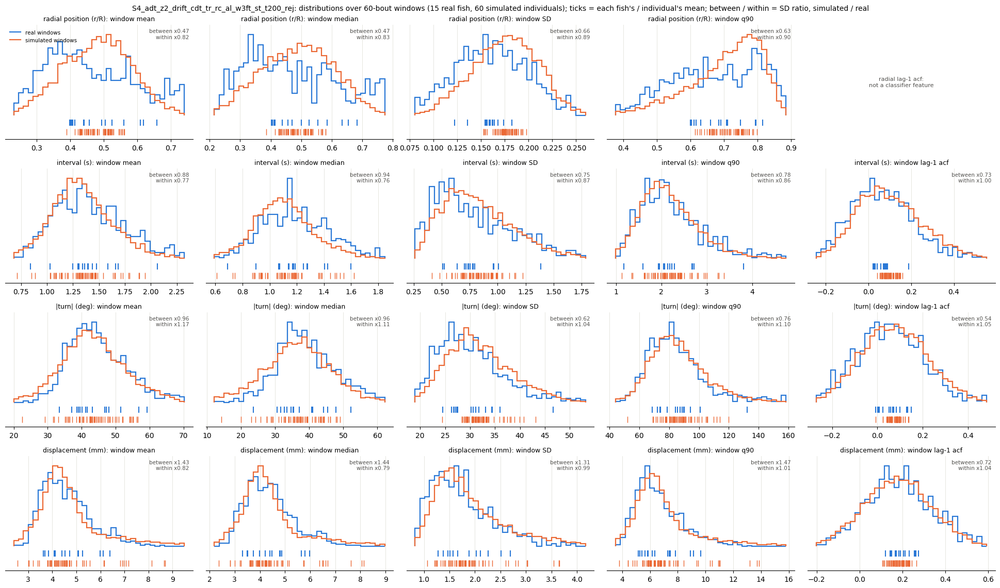


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold4.pt: 3 rollouts
dropped 10.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.16     0.74  0.15  0.93   3.0   5.0                  22.3 +/- 0.9  21.4 +/- 1.0
d2s3.5    1.76     1.35  2.64  2.59  11.0  19.0                  17.4 +/- 0.9  19.6 +/- 0.9
d4s3.5    0.96     0.59  4.68  3.93  19.0   9.0                  18.7 +/- 1.7  18.6 +/- 0.9
d6s3.5    1.53     1.14  4.62   2.9  13.0   9.0                  16.7 +/- 1.3  18.4 +/- 0.7
d8s3.5    1.76     1.66  4.97  2.65  11.0   9.0                  16.3 +/- 1.0  17.2 +/- 1.0

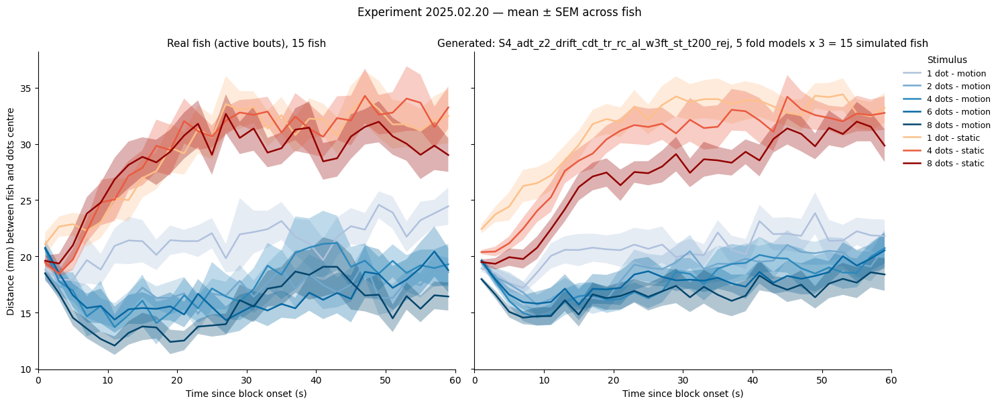


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

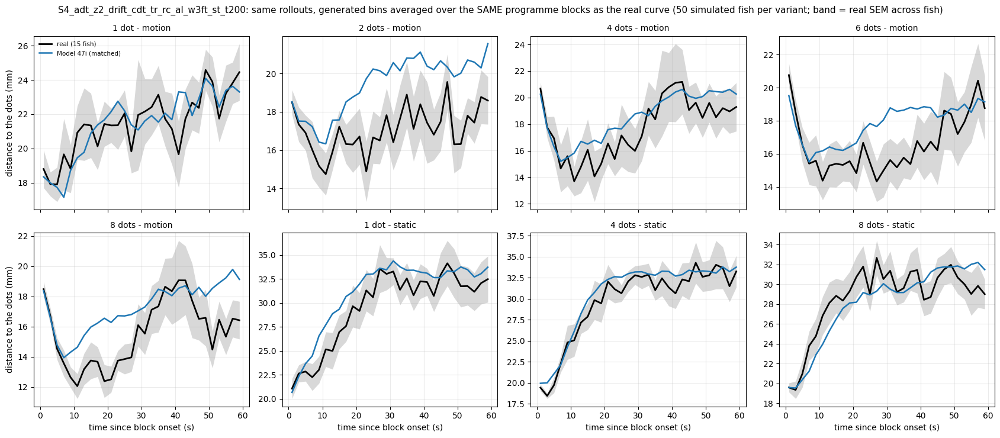


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200                  
           plateau   null attraction                                   plateau   null attraction
cond_label                                                                                      
d1s3.5       22.41  23.57       1.16                                     21.88  23.27       1.39
d2s3.5       17.39  23.58       6.19                                     20.34  23.04       2.70
d4s3.5       18.74  23.93       5.19                                     20.10  22.93       2.83
d6s3.5       16.69  23.12       6.43                                     18.98  23.08       4.11
d8s3.5       16.41  23.36       6.94                                     17.69  22.97   

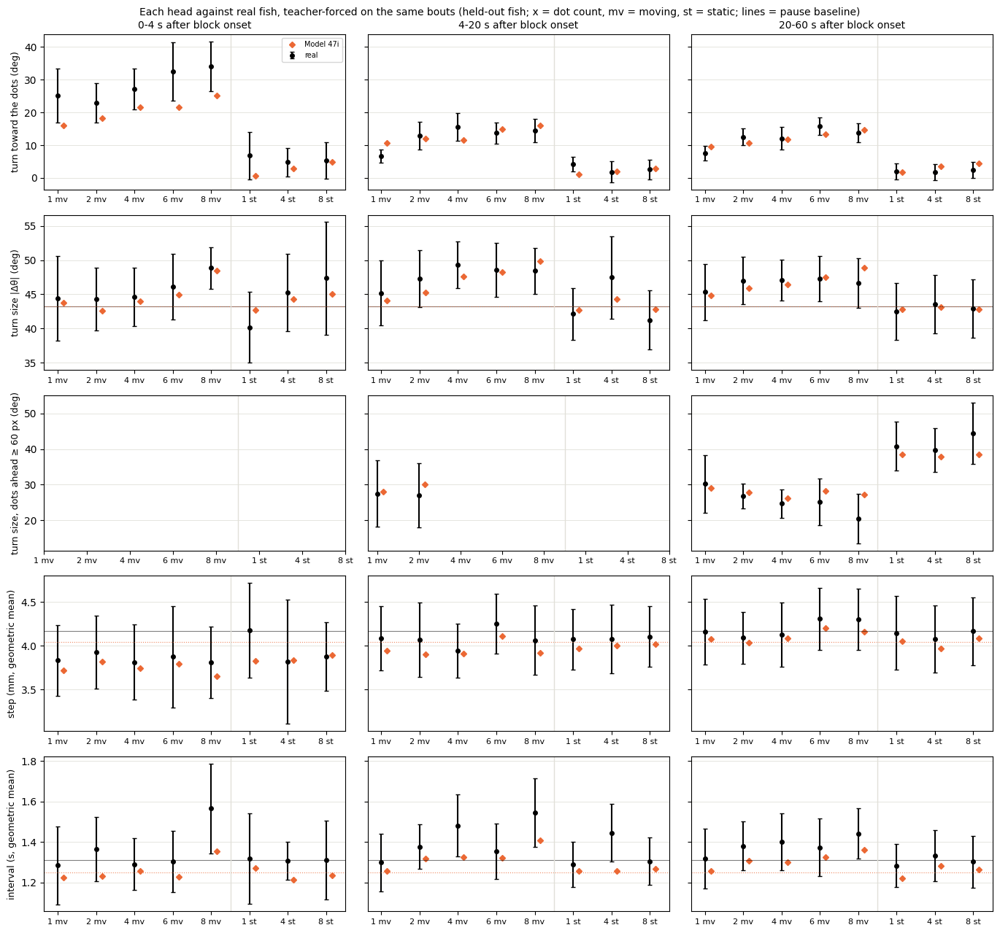

In [34]:
unit_eval.show('47i')

### D4, tau 200, full, seed 0


== held-out likelihood per head (bits per bout)
turn             7.626
displacement     4.515
interval         1.205
joint           13.347

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv  (15 rows) in 835s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_rej
abs_dtheta_w1                                                  9.0232
sym

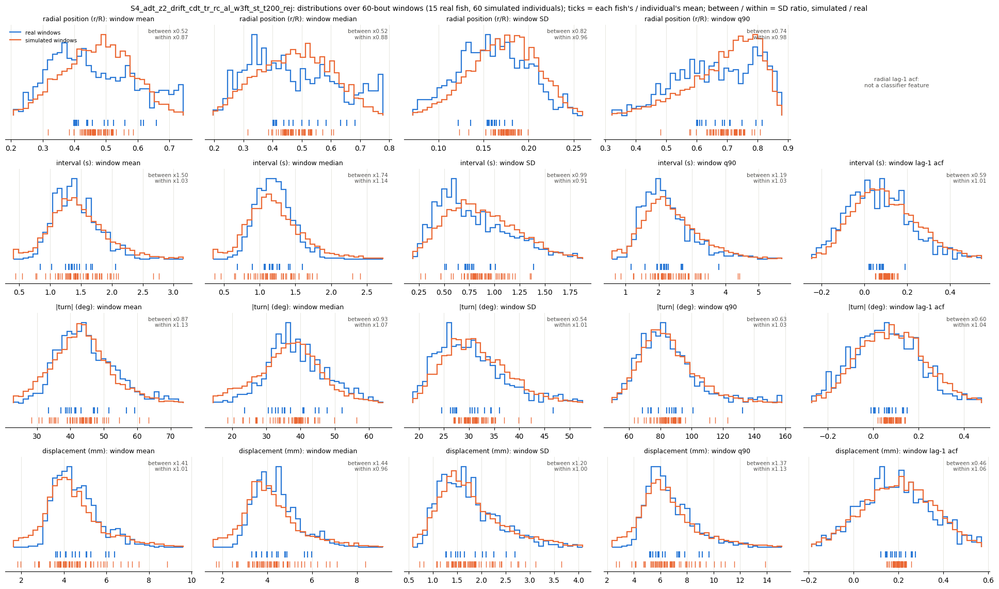


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold4.pt: 3 rollouts
dropped 10.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.16     0.77  0.15  0.71   3.0   5.0                  22.3 +/- 0.9  21.6 +/- 1.6
d2s3.5    0.91     0.73  2.64  3.11  11.0  11.0                  17.4 +/- 0.9  17.6 +/- 1.2
d4s3.5    1.55     0.87  4.68  5.21  19.0   9.0                  18.7 +/- 1.7  18.1 +/- 0.9
d6s3.5    1.15     0.79  4.62  4.91  13.0  11.0                  16.7 +/- 1.3  16.4 +/- 0.9
d8s3.5    1.42     1.13  4.97  4.25  11.0   9.0                  16.3 +/- 1.0  15.5 +/- 0.6

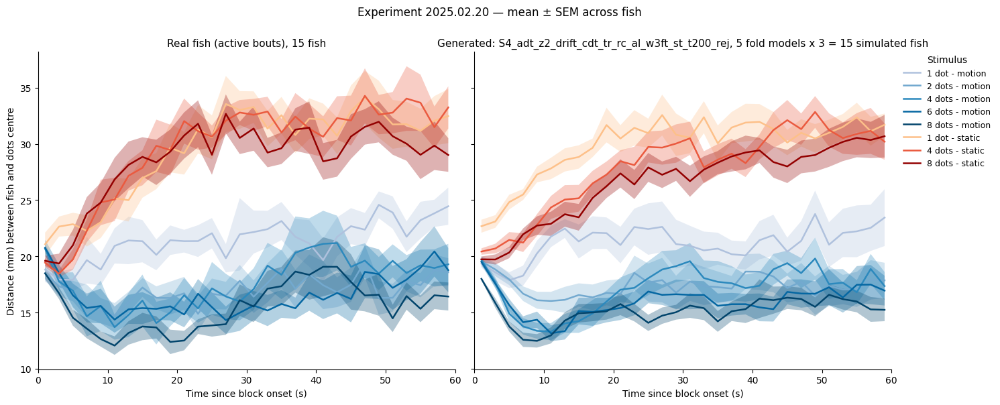


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

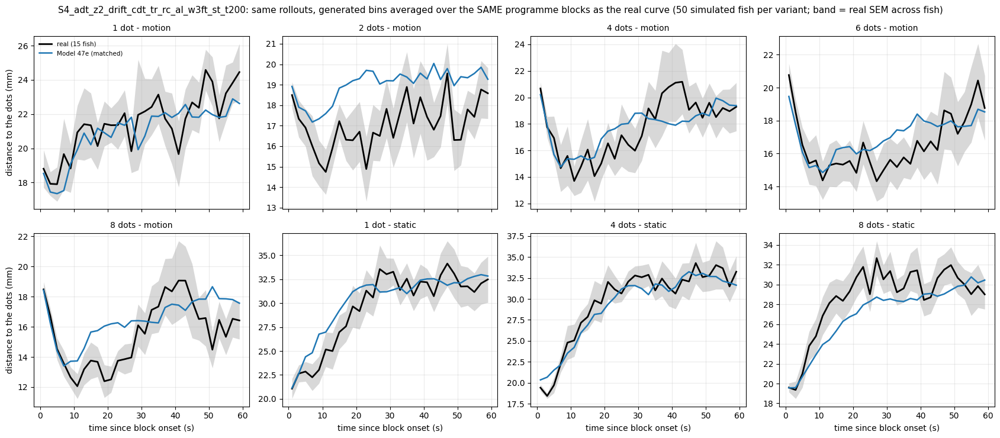


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200                  
           plateau   null attraction                                   plateau   null attraction
cond_label                                                                                      
d1s3.5       22.41  23.57       1.16                                     22.00  22.64       0.63
d2s3.5       17.39  23.58       6.19                                     18.98  22.77       3.79
d4s3.5       18.74  23.93       5.19                                     18.83  22.82       3.99
d6s3.5       16.69  23.12       6.43                                     17.75  22.86       5.11
d8s3.5       16.41  23.36       6.94                                     17.08  22.82   

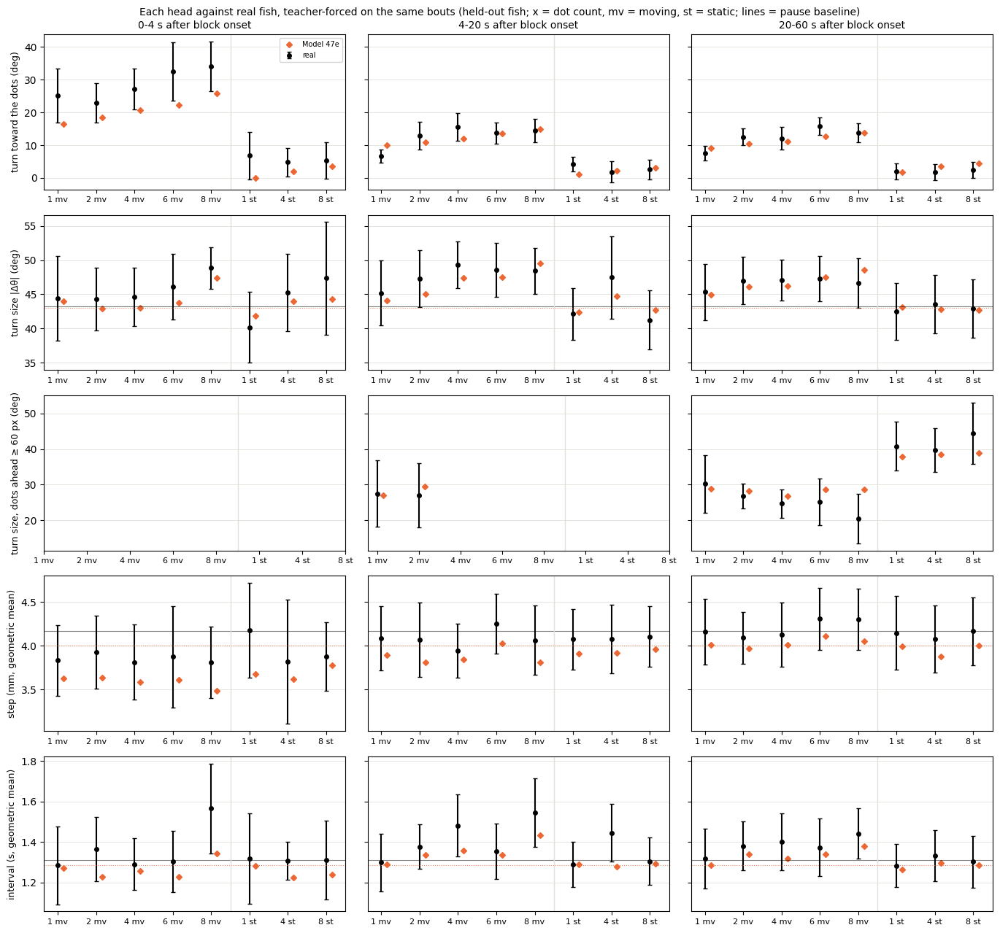

In [35]:
unit_eval.show('47e')

### D4, tau 200, full, seed 101


== held-out likelihood per head (bits per bout)


turn             7.628
displacement     4.503
interval         1.213
joint           13.344

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv  (15 rows) in 597s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_rej
abs_dtheta_w1                                                  8.7447
symbol_js                                          

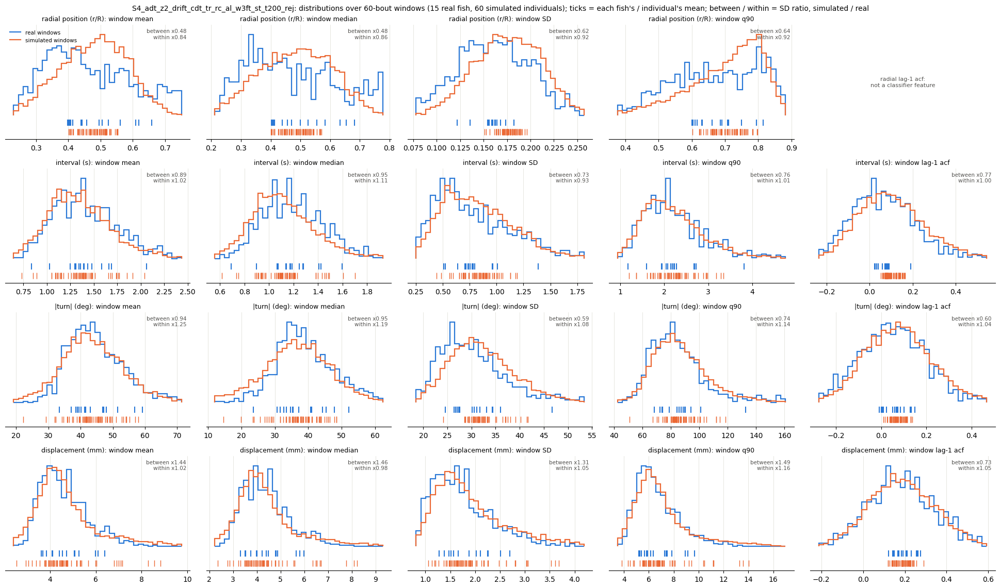


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold4.pt: 3 rollouts
dropped 10.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.18     0.78  0.15  0.34   3.0   5.0                  22.3 +/- 0.9  22.9 +/- 0.6
d2s3.5    1.66     1.29  2.64  2.62  11.0  11.0                  17.4 +/- 0.9  18.9 +/- 0.7
d4s3.5    0.95     0.60  4.68  4.03  19.0  19.0                  18.7 +/- 1.7  18.2 +/- 0.8
d6s3.5    1.03     0.75  4.62  3.81  13.0   9.0                  16.7 +/- 1.3  16.9 +/- 0.8
d8s3.5    1.74     1.62  4.97  3.17  11.0  11.0                  16.3 +/- 1.0  17.2 +/- 0.8

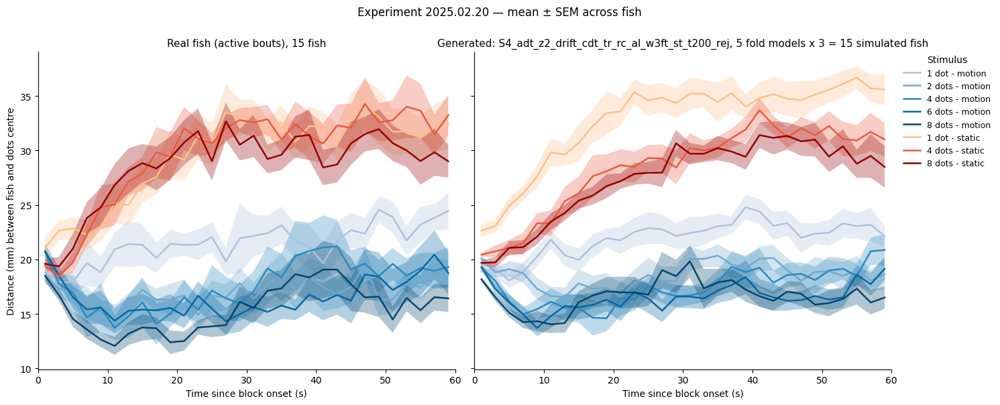


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

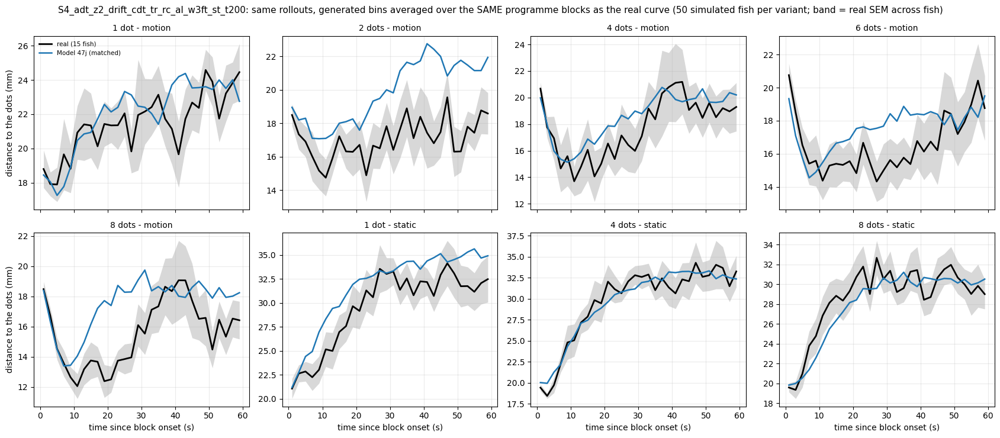


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200                  
           plateau   null attraction                                   plateau   null attraction
cond_label                                                                                      
d1s3.5       22.41  23.57       1.16                                     22.88  23.10       0.22
d2s3.5       17.39  23.58       6.19                                     19.91  22.72       2.81
d4s3.5       18.74  23.93       5.19                                     19.48  23.06       3.58
d6s3.5       16.69  23.12       6.43                                     18.79  22.83       4.04
d8s3.5       16.41  23.36       6.94                                     19.04  22.96   

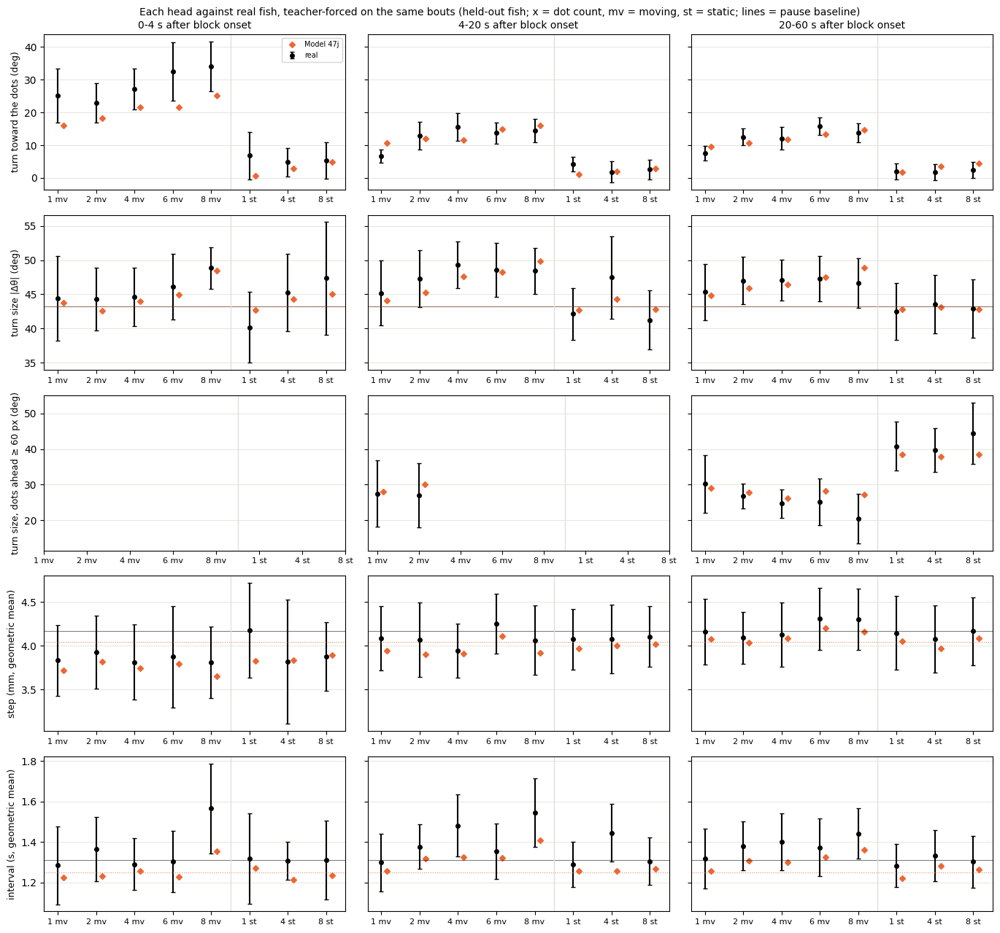

In [36]:
unit_eval.show('47j')

### F on D4 at strength 0, seed 0


== held-out likelihood per head (bits per bout)


turn             7.628
displacement     4.513
interval         1.203
joint           13.344

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv  (15 rows) in 266s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_rej
abs_dtheta_w1                                                         8.7359
symbol_js

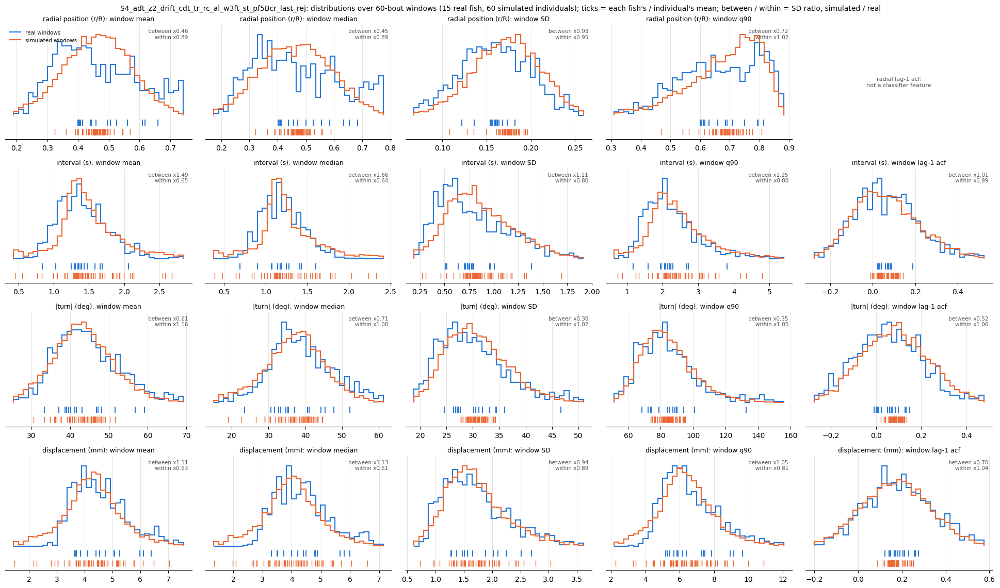


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.09     0.76  0.15  0.19   3.0   5.0                  22.3 +/- 0.9  21.7 +/- 0.9
d2s3.5    1.25     0.96  2.64  3.34  11.0  11.0                  17.4 +/- 0.9  18.5 +/- 1.2
d4s3.5    1.00     0.62  4.68   4.6  19.0  13.0                  18.7 +/- 1.7  18.4 +/- 1.0
d6s3.5    1.14     0.80  4.62  4.93  13.0  11.0                  16.7 +/- 1.3  17.1 +/- 1.1
d8s3.5    1.33     0.94  4.97  5.16  11.0  19.0                  16.3 +/- 1.0  14.8 

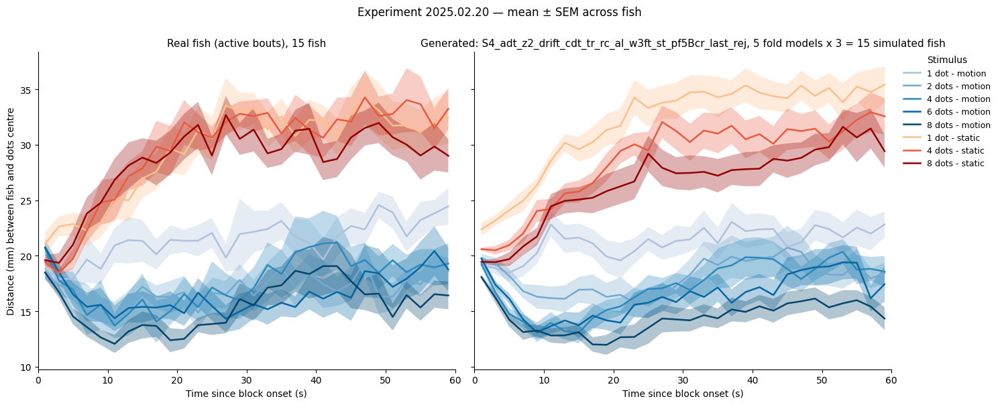


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

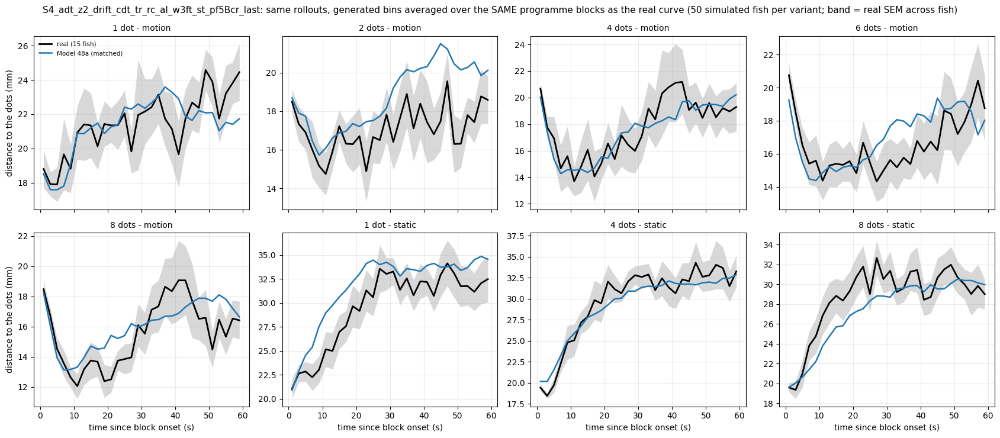


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last                  
           plateau   null attraction                                          plateau   null attraction
cond_label                                                                                             
d1s3.5       22.41  23.57       1.16                                            22.56  22.56       0.00
d2s3.5       17.39  23.58       6.19                                            19.50  22.44       2.94
d4s3.5       18.74  23.93       5.19                                            18.30  22.41       4.11
d6s3.5       16.69  23.12       6.43                                            17.81  22.85       5.03
d8s3.5       16.41  23.36       6.94   

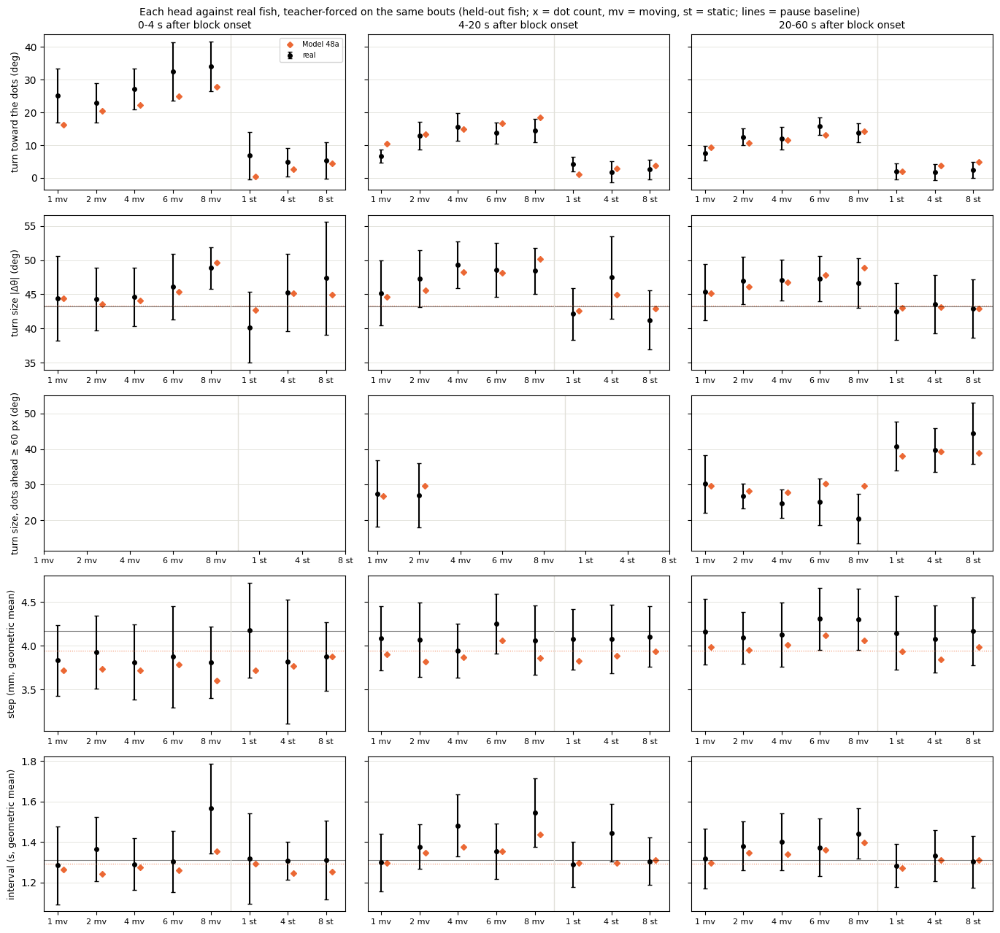

In [37]:
unit_eval.show('48a')

### F on D4 at strength 0, seed 101


== held-out likelihood per head (bits per bout)


turn             7.630
displacement     4.520
interval         1.207
joint           13.357

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv  (15 rows) in 258s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_rej
abs_dtheta_w1                                                         8.2673
symbol_js

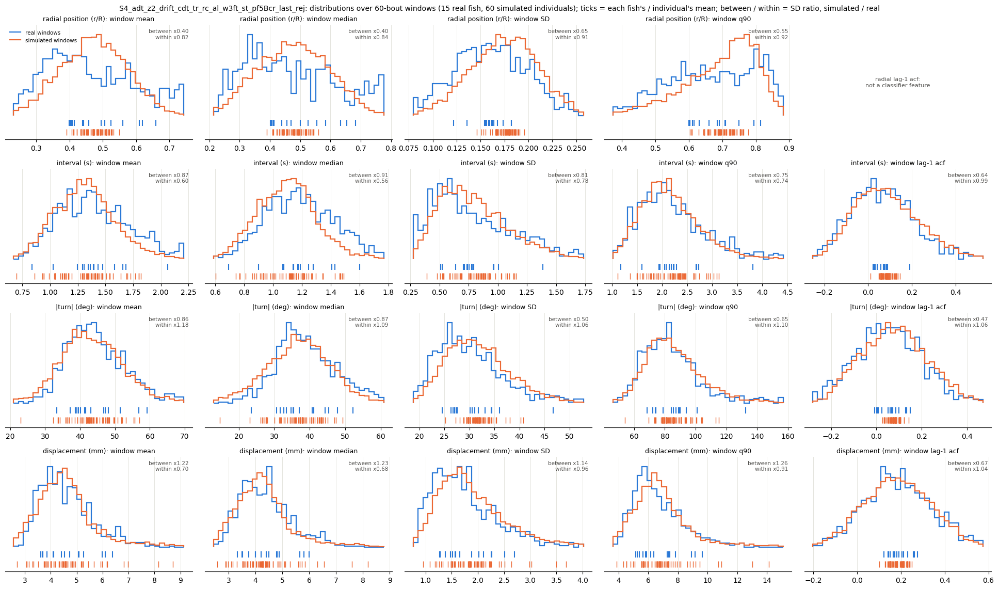


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 11.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.56     1.06  0.15  1.18   3.0   7.0                  22.3 +/- 0.9  23.9 +/- 1.0
d2s3.5    1.88     1.45  2.64  3.58  11.0  19.0                  17.4 +/- 0.9  19.7 +/- 1.1
d4s3.5    1.38     0.80  4.68   4.3  19.0  11.0                  18.7 +/- 1.7  18.3 +/- 0.8
d6s3.5    1.72     1.24  4.62  4.74  13.0  13.0                  16.7 +/- 1.3  18.0 +/- 0.9
d8s3.5    1.32     1.12  4.97  4.17  11.0  13.0                  16.3 +/- 1.0  16.5 

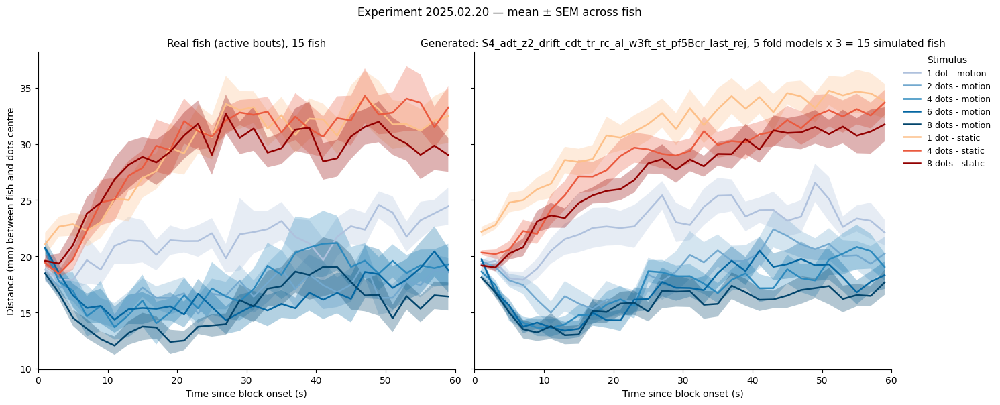


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

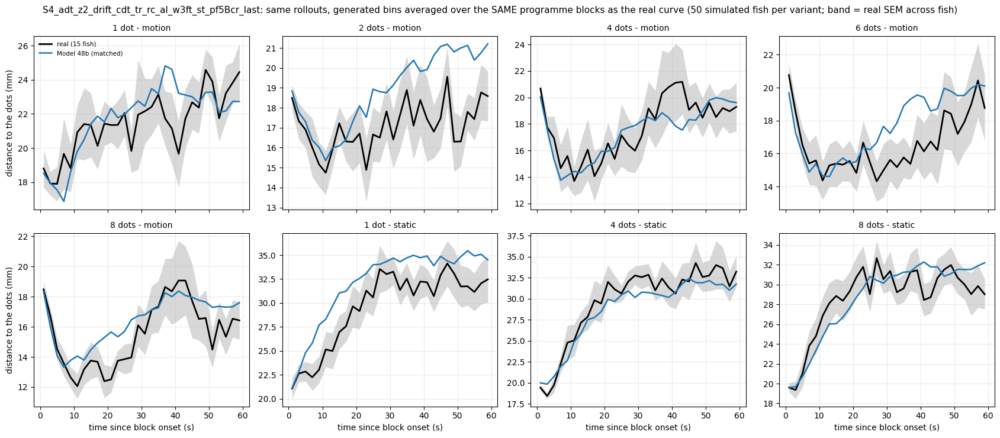


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last                  
           plateau   null attraction                                          plateau   null attraction
cond_label                                                                                             
d1s3.5       22.41  23.57       1.16                                            23.28  22.62      -0.66
d2s3.5       17.39  23.58       6.19                                            19.36  22.56       3.19
d4s3.5       18.74  23.93       5.19                                            18.14  22.62       4.47
d6s3.5       16.69  23.12       6.43                                            18.36  22.68       4.32
d8s3.5       16.41  23.36       6.94   

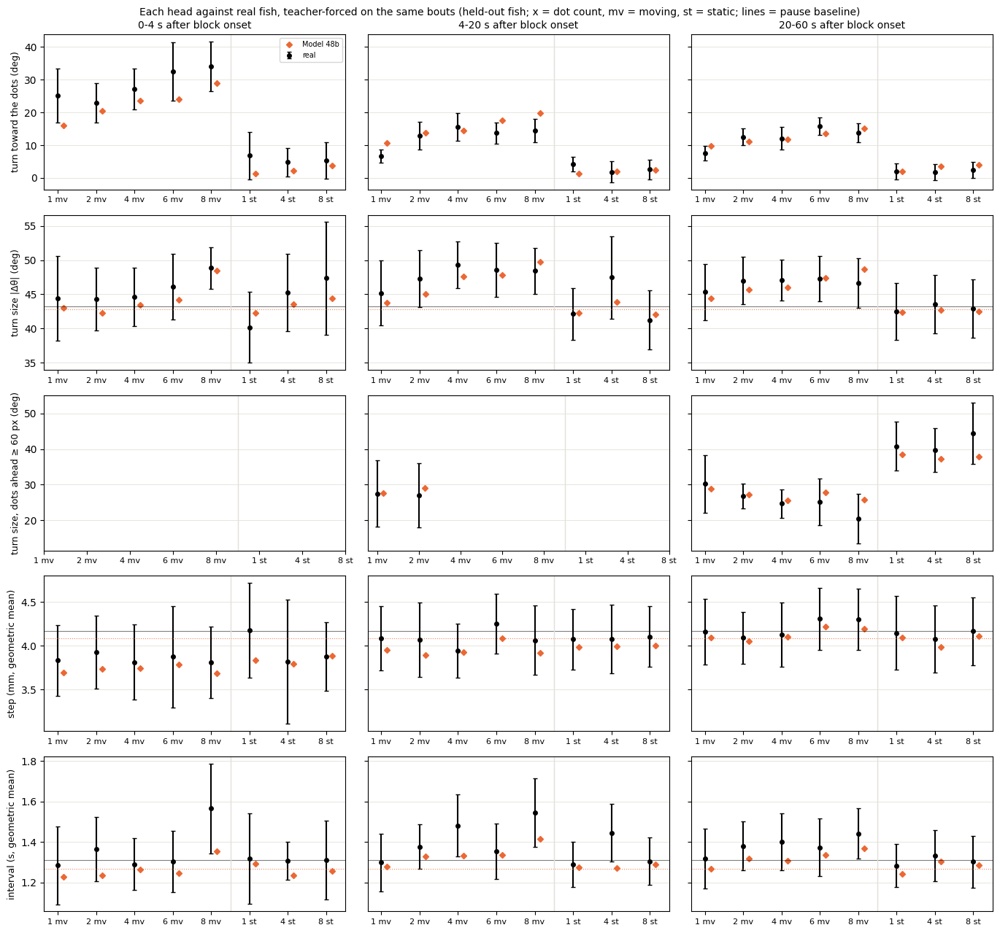

In [38]:
unit_eval.show('48b')

### M6, jump phase, seed 0


== held-out likelihood per head (bits per bout)
turn             7.651
displacement     4.548
interval         1.227
joint           13.427

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_jp'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_jp.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_jp.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_jp.csv  (15 rows) in 693s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_jp_rej
abs_dtheta_w1                                        7.6188
symbol_js                                            0.0103
dt_

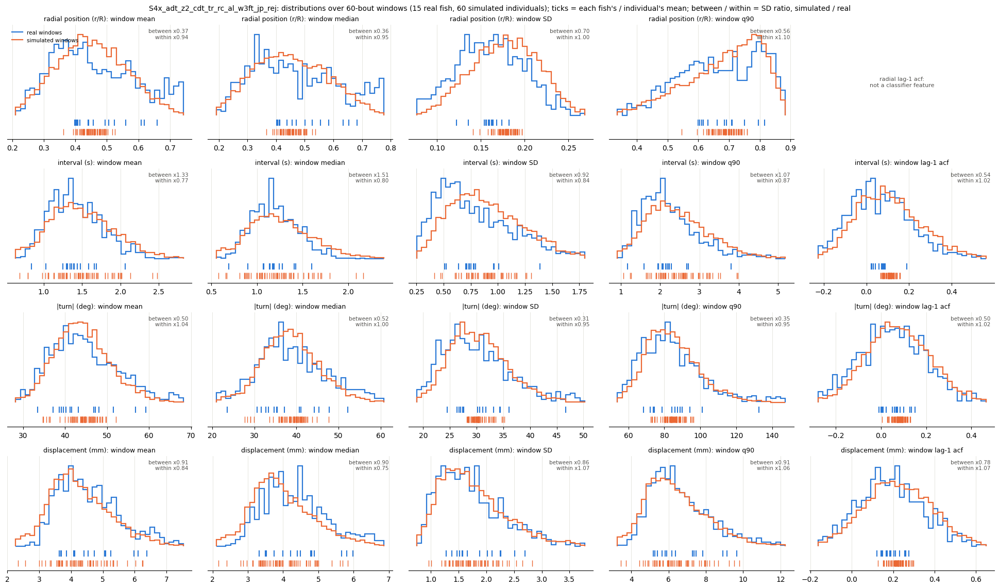


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_jp_fold4.pt: 3 rollouts
dropped 9.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.44     1.01  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  21.3 +/- 0.7
d2s3.5    2.02     1.62  2.64  1.55  11.0   9.0                  17.4 +/- 0.9  19.4 +/- 0.7
d4s3.5    1.92     1.14  4.68  3.33  19.0  11.0                  18.7 +/- 1.7  17.8 +/- 0.6
d6s3.5    1.55     1.05  4.62  4.59  13.0   9.0                  16.7 +/- 1.3  16.6 +/- 0.6
d8s3.5    1.43     1.40  4.97  1.55  11.0   7.0                  16.3 +/- 1.0  16.7 +/- 0.8
d1s0      

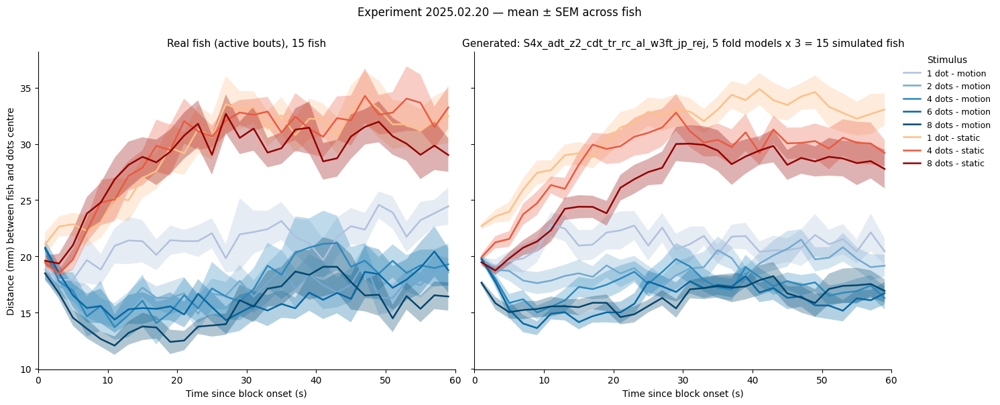


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

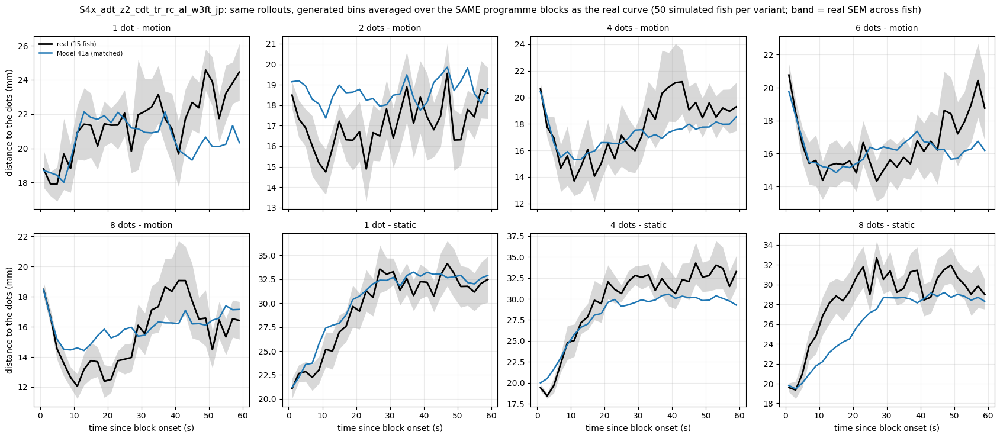


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_jp                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           21.02  21.75       0.73
d2s3.5       17.39  23.58       6.19                           18.42  21.80       3.38
d4s3.5       18.74  23.93       5.19                           17.22  21.80       4.58
d6s3.5       16.69  23.12       6.43                           16.33  21.61       5.29
d8s3.5       16.41  23.36       6.94                           16.20  21.87       5.67

== turn toward the moving dots by dot count
           real  S4x_adt_z

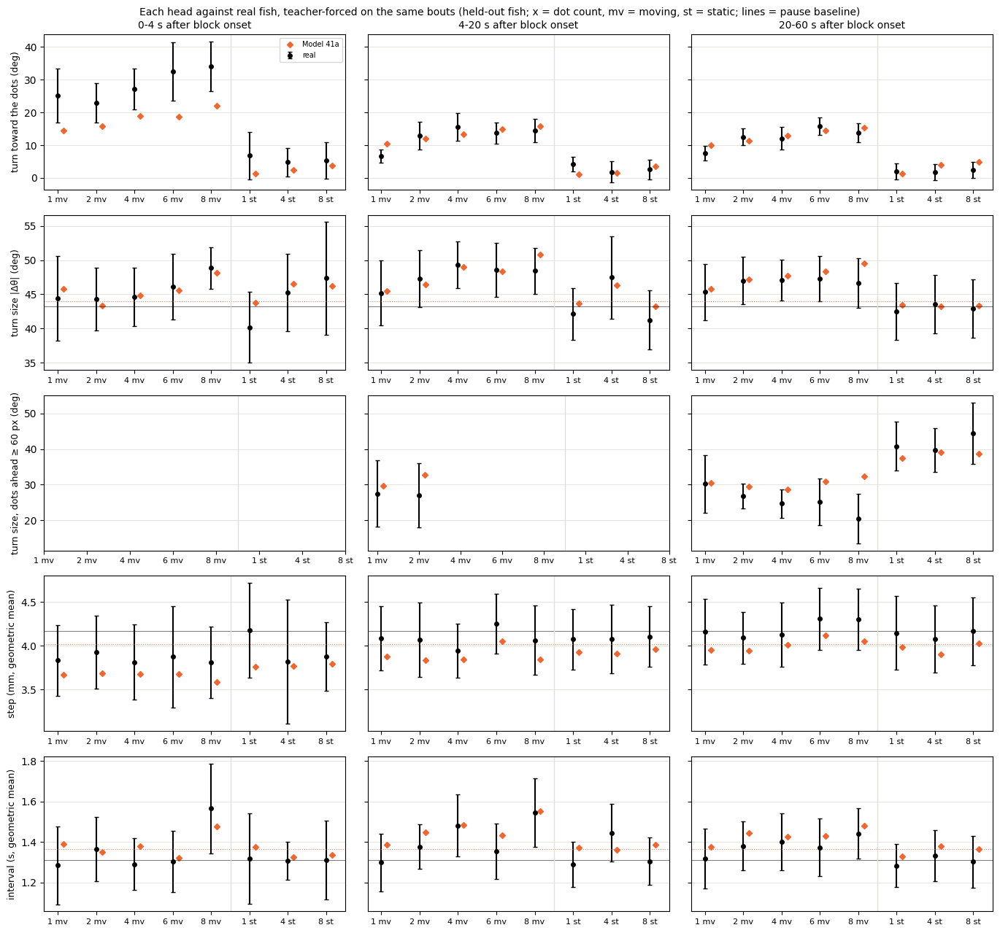

In [39]:
unit_eval.show('41a')

### M6, jump phase, seed 101


== held-out likelihood per head (bits per bout)
turn             7.663
displacement     4.517
interval         1.233
joint           13.413

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_jp'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_jp.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_jp.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_jp.csv  (15 rows) in 690s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_jp_rej
abs_dtheta_w1                                        8.6929
symbol_js                                            0.0143
dt_

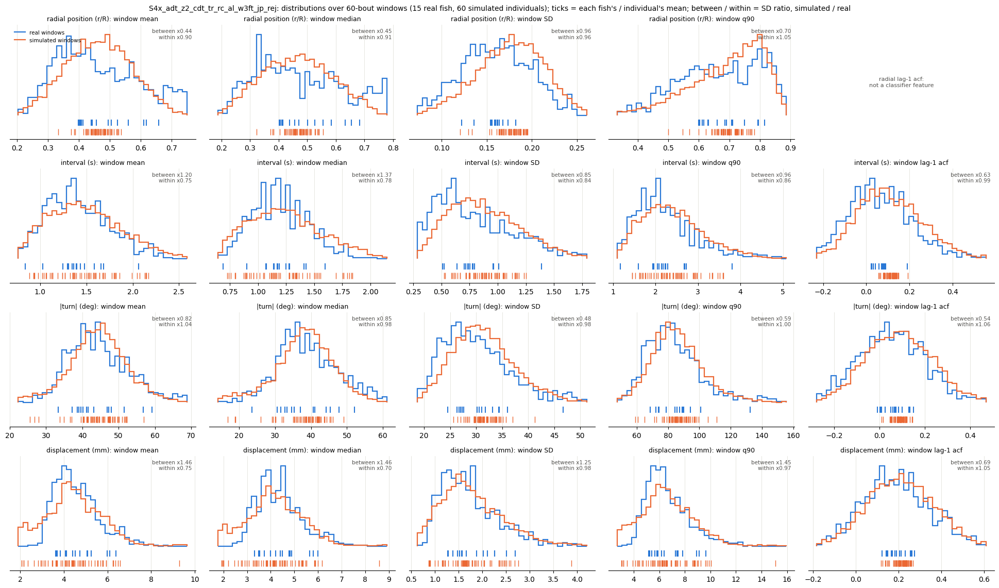


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_jp_fold4.pt: 3 rollouts
dropped 10.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.46     0.98  0.15  0.68   3.0   7.0                  22.3 +/- 0.9  20.7 +/- 0.7
d2s3.5    1.65     1.35  2.64  2.41  11.0  19.0                  17.4 +/- 0.9  18.8 +/- 1.0
d4s3.5    1.16     0.69  4.68  4.53  19.0   9.0                  18.7 +/- 1.7  18.0 +/- 1.1
d6s3.5    1.65     1.23  4.62  3.42  13.0   9.0                  16.7 +/- 1.3  18.2 +/- 1.1
d8s3.5    1.76     1.59  4.97  3.02  11.0   9.0                  16.3 +/- 1.0  16.4 +/- 1.0
d1s0     

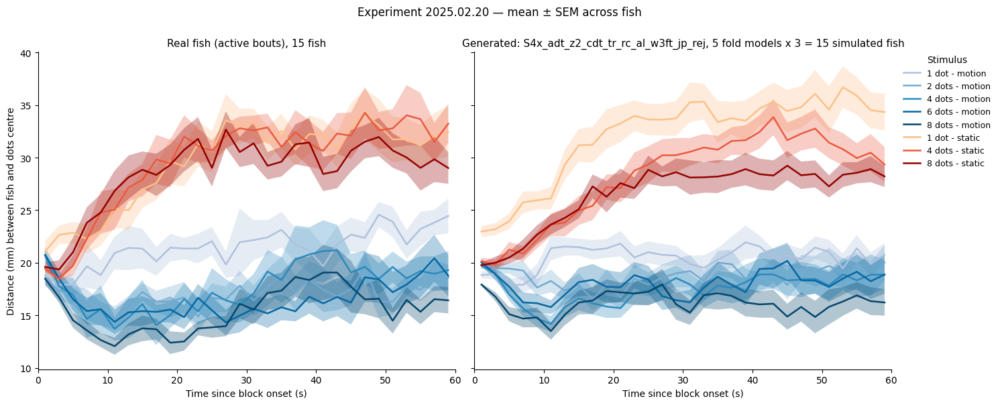


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

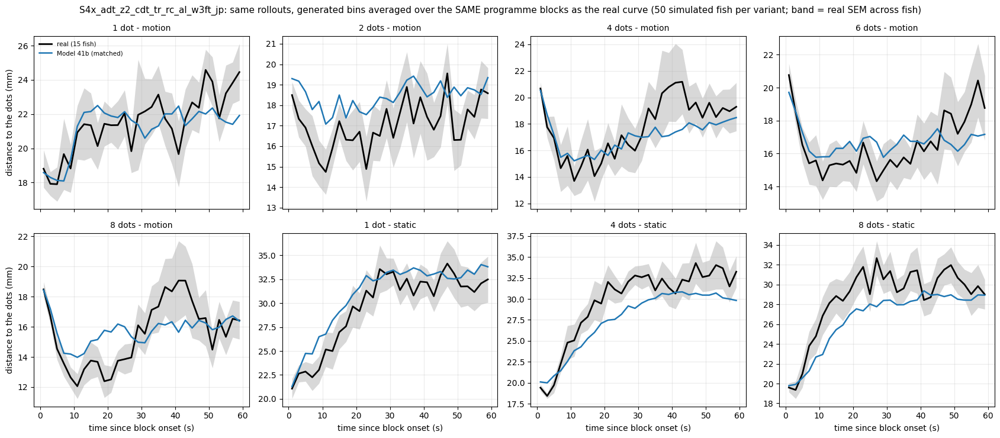


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_jp                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           21.47  22.50       1.03
d2s3.5       17.39  23.58       6.19                           18.85  22.35       3.49
d4s3.5       18.74  23.93       5.19                           17.37  22.19       4.82
d6s3.5       16.69  23.12       6.43                           16.67  22.34       5.66
d8s3.5       16.41  23.36       6.94                           15.99  22.53       6.54

== turn toward the moving dots by dot count
           real  S4x_adt_z

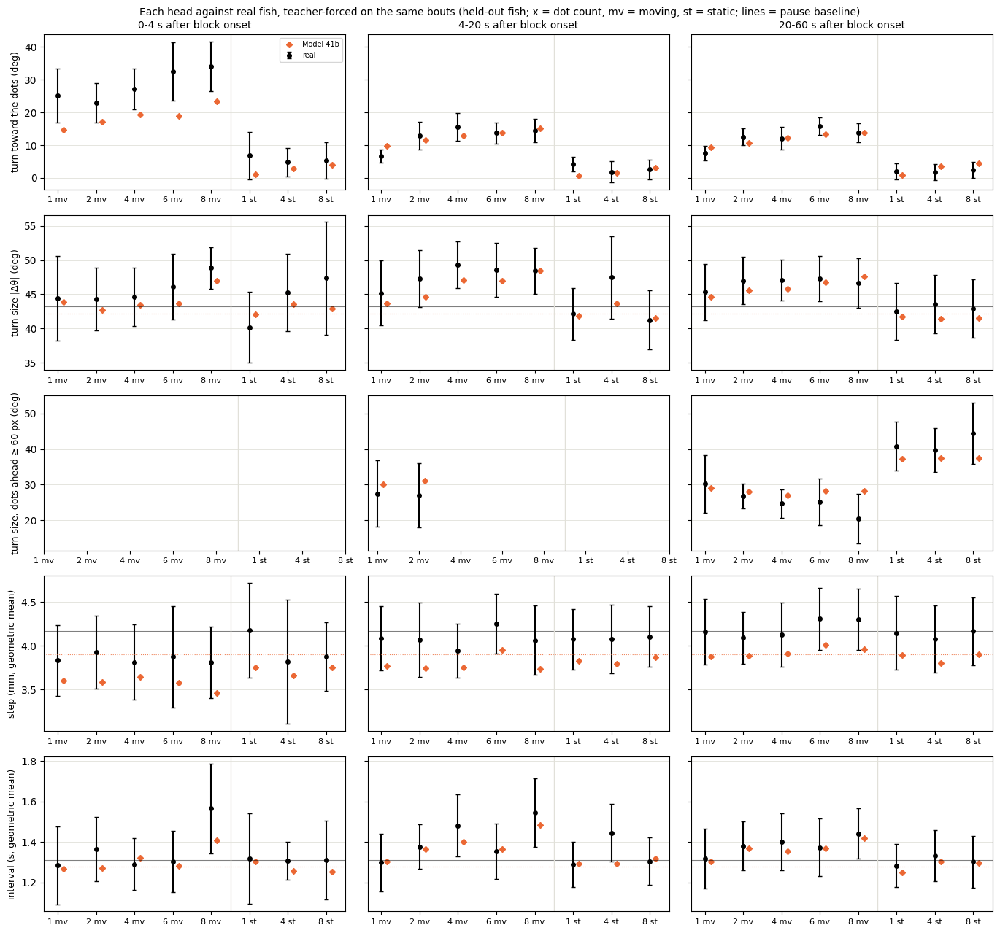

In [40]:
unit_eval.show('41b')

### D4, jump phase, seed 0


== held-out likelihood per head (bits per bout)
turn             7.639
displacement     4.509
interval         1.206
joint           13.353

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp.csv  (15 rows) in 702s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_rej
abs_dtheta_w1                                                8.7689
symbol_js      

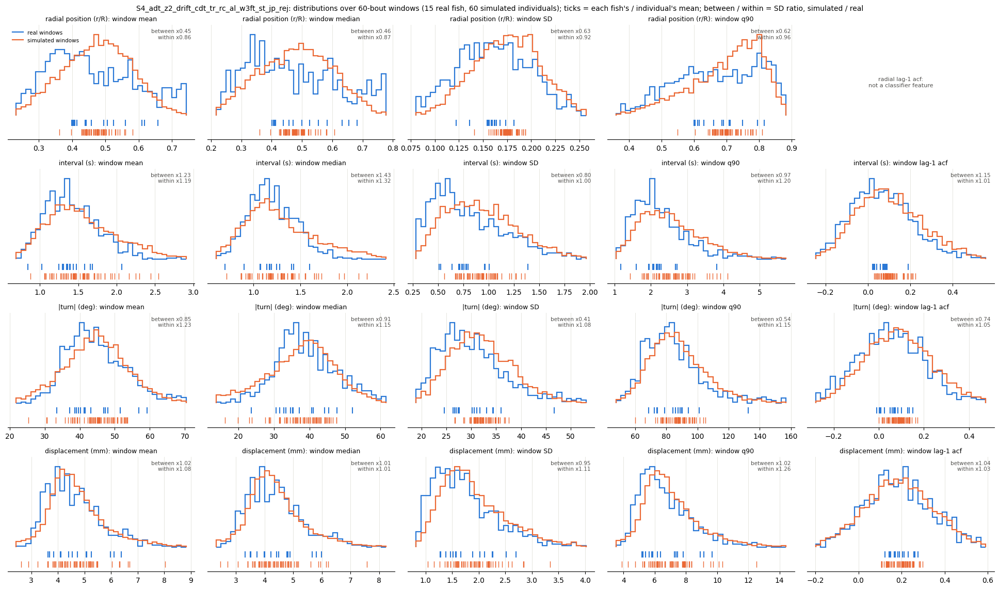


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_fold4.pt: 3 rollouts
dropped 12.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.62     1.12  0.15  0.51   3.0   5.0                  22.3 +/- 0.9  21.2 +/- 0.9
d2s3.5    1.21     0.97  2.64  2.31  11.0   9.0                  17.4 +/- 0.9  18.8 +/- 1.0
d4s3.5    1.38     0.86  4.68  3.41  19.0   9.0                  18.7 +/- 1.7  18.0 +/- 0.8
d6s3.5    1.66     1.19  4.62  3.67  13.0   7.0                  16.7 +/- 1.3  17.6 +/- 1.0
d8s3.5    1.70     1.34  4.97  2.89  11.0   9.0                  16.3 +/- 1.0  15.3 +/- 0.8
d

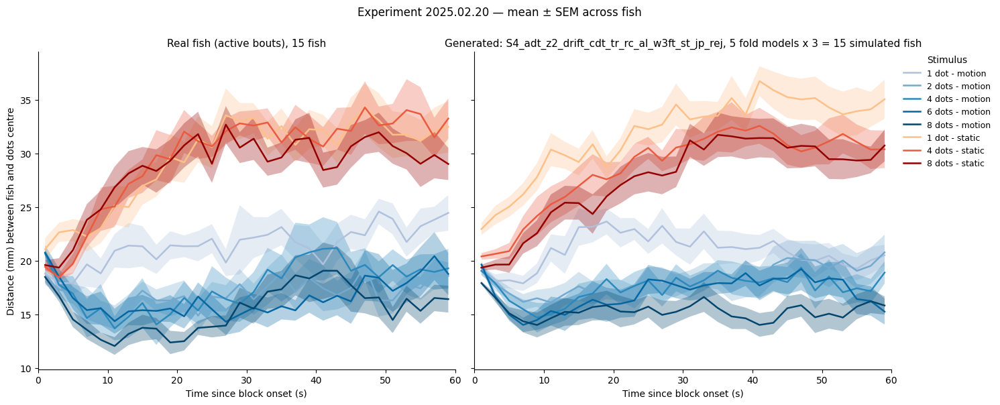


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

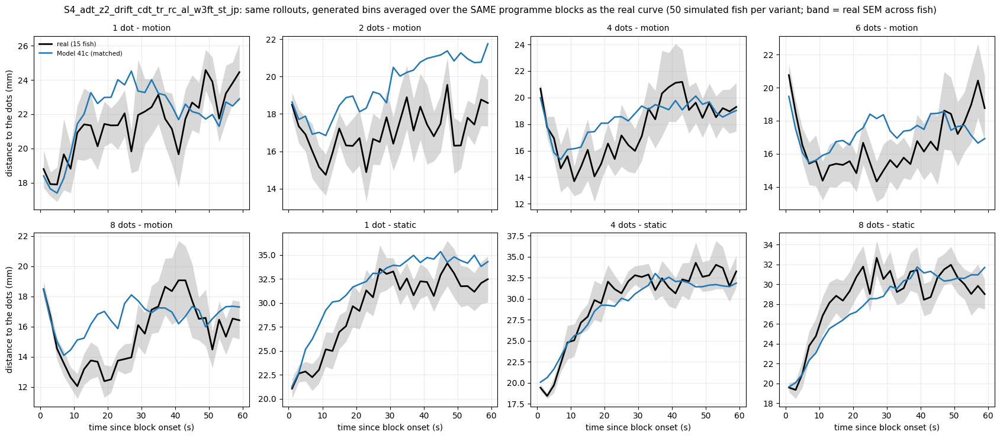


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp                  
           plateau   null attraction                                 plateau   null attraction
cond_label                                                                                    
d1s3.5       22.41  23.57       1.16                                   22.79  23.30       0.51
d2s3.5       17.39  23.58       6.19                                   20.00  22.84       2.84
d4s3.5       18.74  23.93       5.19                                   18.54  23.13       4.59
d6s3.5       16.69  23.12       6.43                                   18.00  23.05       5.05
d8s3.5       16.41  23.36       6.94                                   17.05  23.09       6.04

== tur

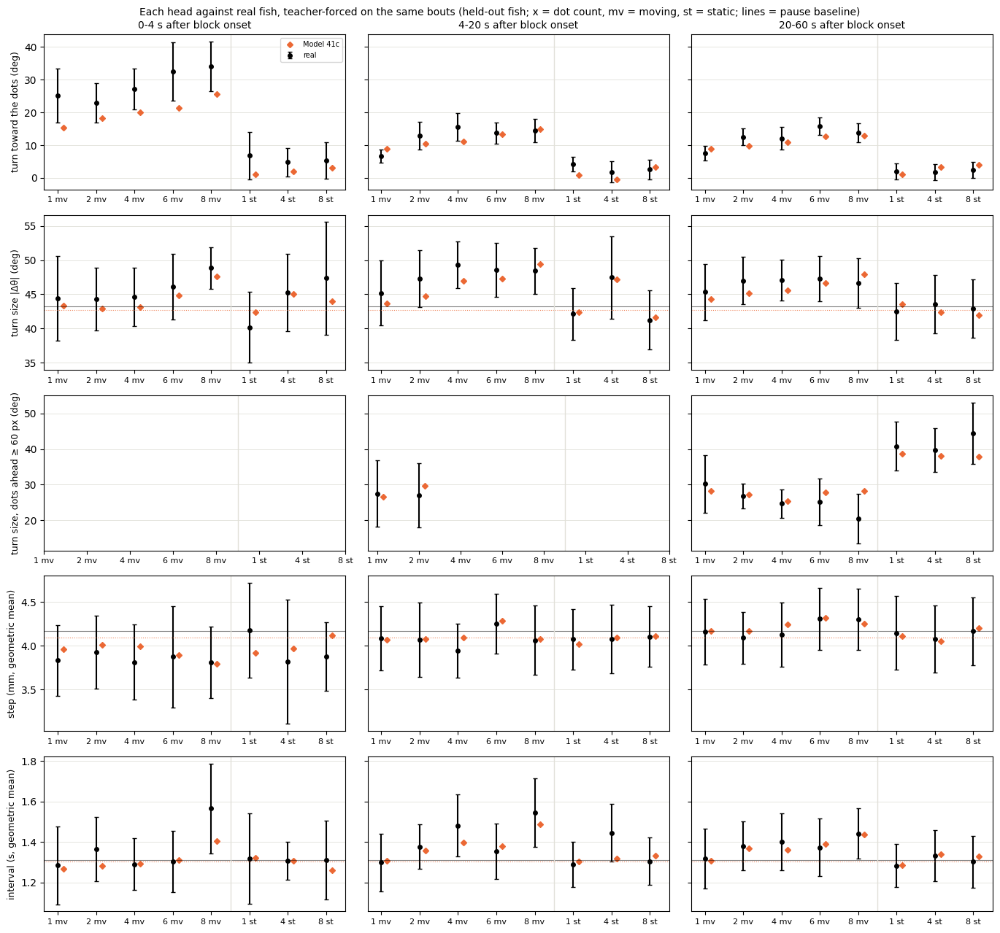

In [41]:
unit_eval.show('41c')

### D4, jump phase, seed 101


== held-out likelihood per head (bits per bout)


turn             7.622
displacement     4.502
interval         1.231
joint           13.354

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp.csv  (15 rows) in 600s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_rej
abs_dtheta_w1                                                8.4661
symbol_js                                                    0.

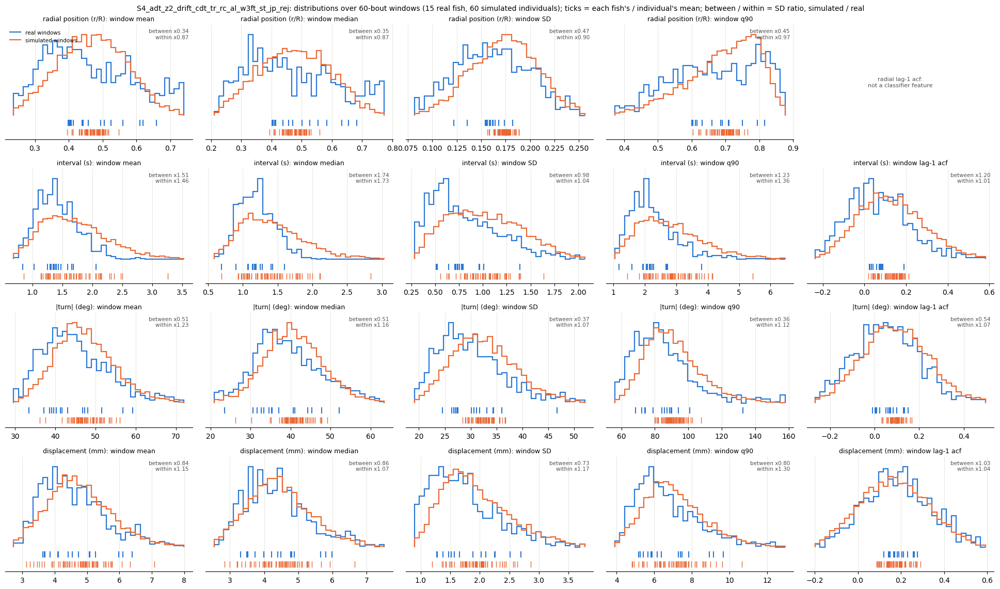


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_fold4.pt: 3 rollouts
dropped 14.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.80     1.21  0.15   0.4   3.0   5.0                  22.3 +/- 0.9  23.2 +/- 0.8
d2s3.5    4.31     3.34  2.64  0.86  11.0   9.0                  17.4 +/- 0.9  22.7 +/- 0.8
d4s3.5    2.13     1.41  4.68  1.57  19.0   5.0                  18.7 +/- 1.7  20.4 +/- 1.1
d6s3.5    2.76     1.95  4.62  2.64  13.0   7.0                  16.7 +/- 1.3  20.1 +/- 1.3
d8s3.5    2.32     2.20  4.97  2.03  11.0   7.0                  16.3 +/- 1.0  18.1 +/- 1.1
d

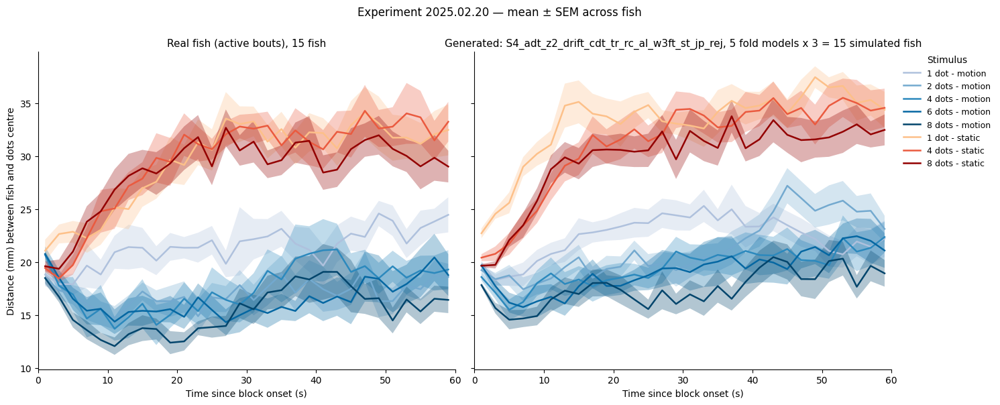


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

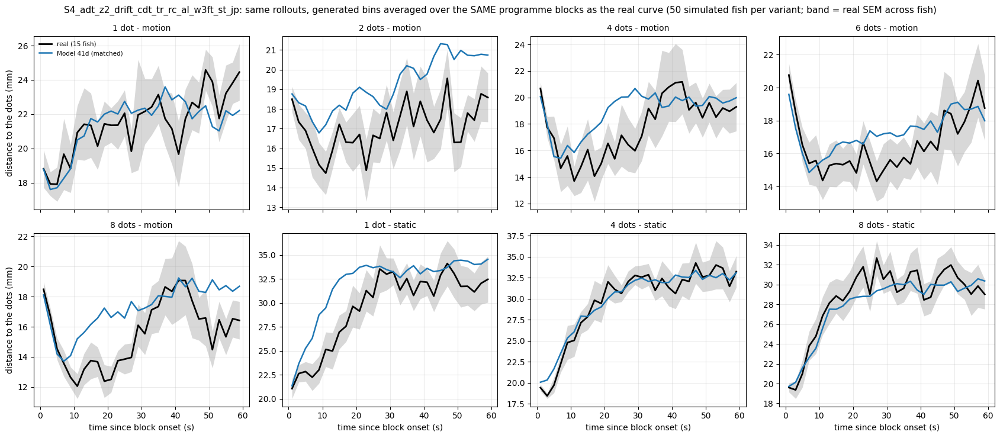


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp                  
           plateau   null attraction                                 plateau   null attraction
cond_label                                                                                    
d1s3.5       22.41  23.57       1.16                                   23.46  23.73       0.27
d2s3.5       17.39  23.58       6.19                                   20.94  23.97       3.03
d4s3.5       18.74  23.93       5.19                                   19.74  23.62       3.88
d6s3.5       16.69  23.12       6.43                                   19.02  23.61       4.59
d8s3.5       16.41  23.36       6.94                                   18.28  23.63       5.36

== tur

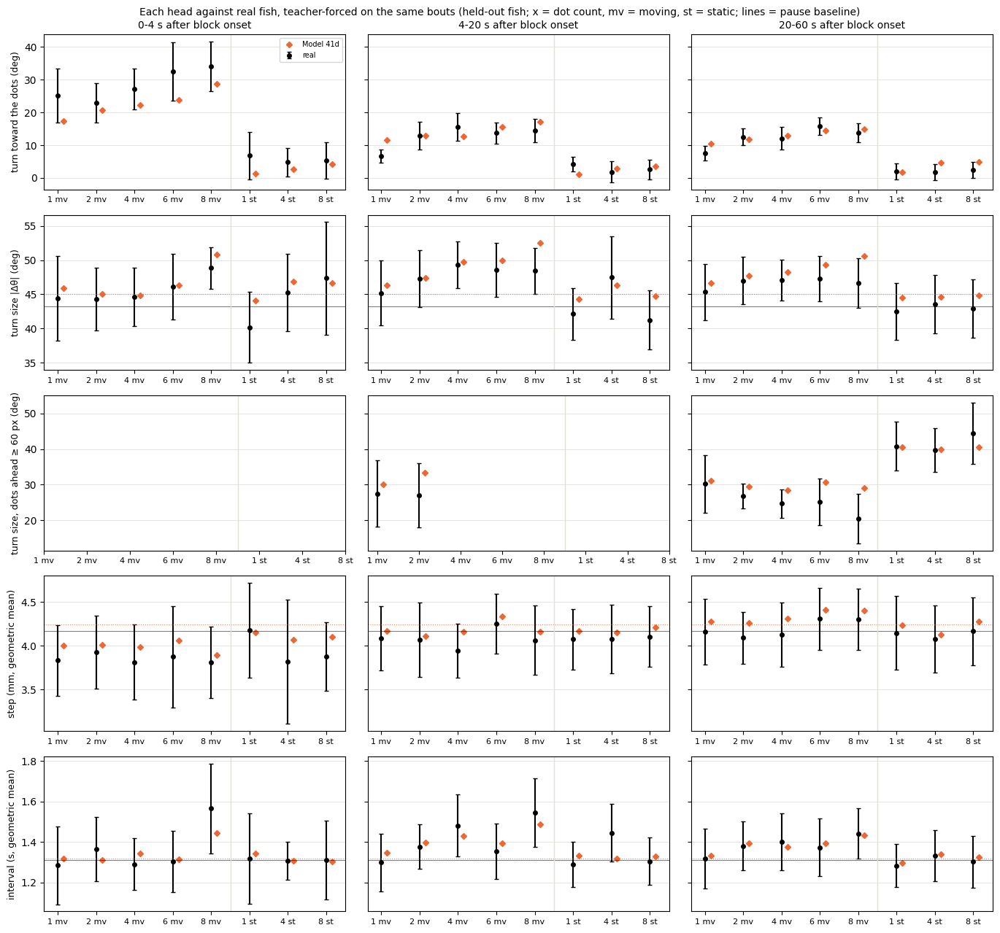

In [42]:
unit_eval.show('41d')

### F, jump phase, seed 0


== held-out likelihood per head (bits per bout)
turn             7.639
displacement     4.509
interval         1.206
joint           13.353

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr_last.csv  (15 rows) in 801s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr_last_rej
abs_dtheta_w1          

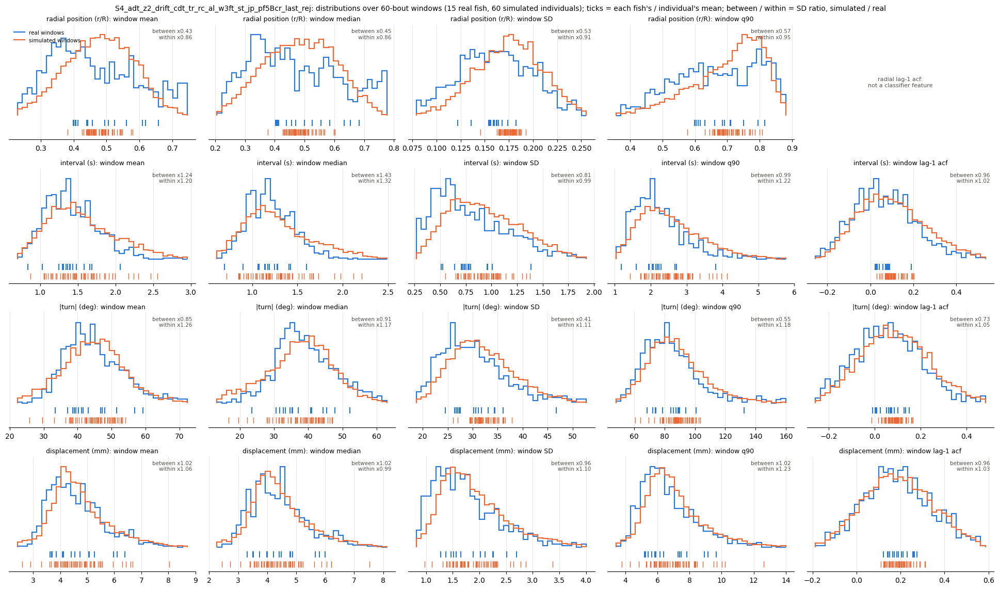


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 11.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.61     1.09  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  22.8 +/- 0.9
d2s3.5    1.71     1.29  2.64  2.87  11.0  15.0                  17.4 +/- 0.9  19.5 +/- 0.9
d4s3.5    1.05     0.67  4.68  4.26  19.0  15.0                  18.7 +/- 1.7  18.5 +/- 1.0
d6s3.5    1.28     0.84  4.62  4.46  13.0   9.0                  16.7 +/- 1.3  15.6 +/- 1.0
d8s3.5    1.15     0.86  4.97  4.15  11.0  13.0                  16.3 +/- 1.0  15

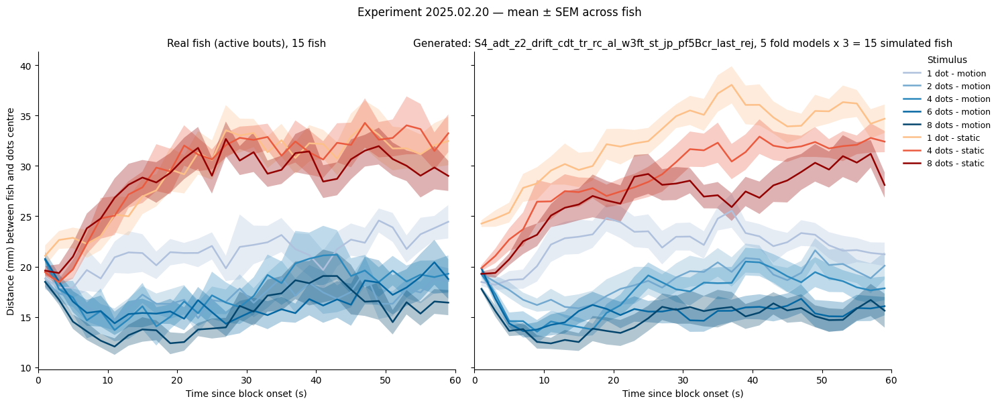


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

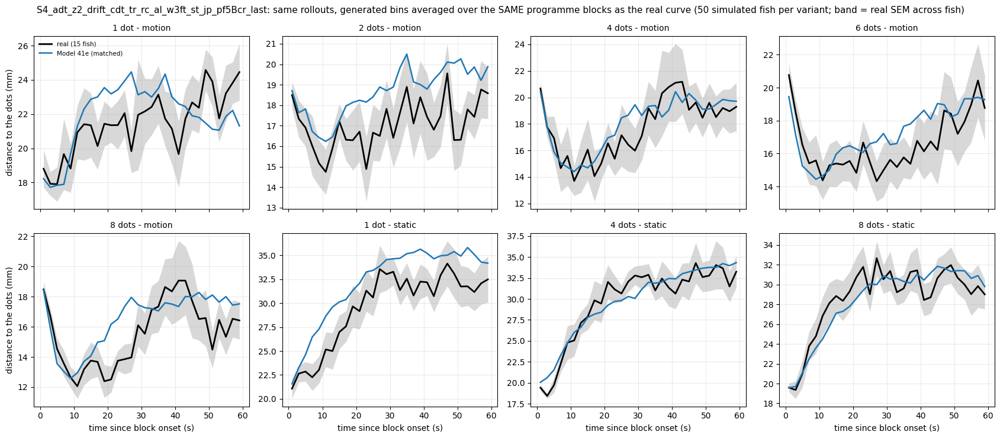


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr_last                  
           plateau   null attraction                                             plateau   null attraction
cond_label                                                                                                
d1s3.5       22.41  23.57       1.16                                               23.10  23.49       0.38
d2s3.5       17.39  23.58       6.19                                               20.06  23.39       3.33
d4s3.5       18.74  23.93       5.19                                               19.44  23.29       3.85
d6s3.5       16.69  23.12       6.43                                               17.55  23.23       5.67
d8s3.5       16.41

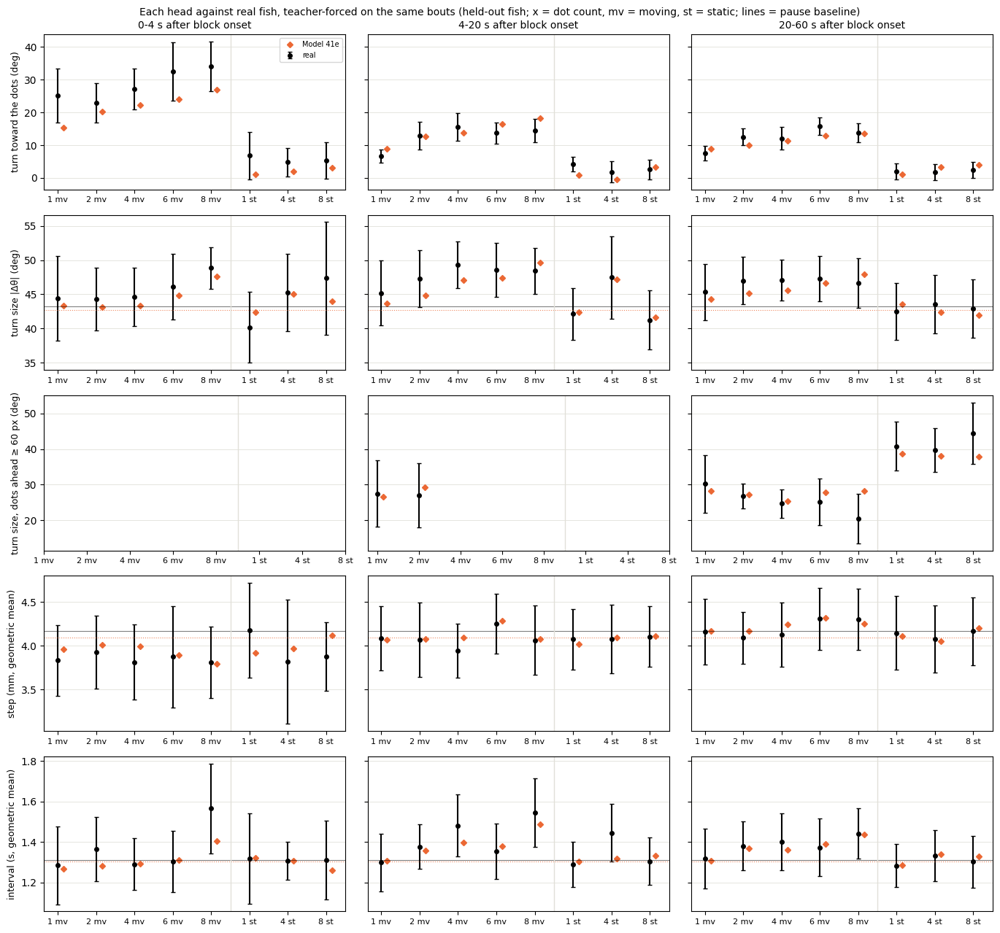

In [43]:
unit_eval.show('41e')

### F, jump phase, seed 101


== held-out likelihood per head (bits per bout)


turn             7.622
displacement     4.502
interval         1.231
joint           13.354

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr_last.csv  (15 rows) in 786s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr_last_rej
abs_dtheta_w1                                                          

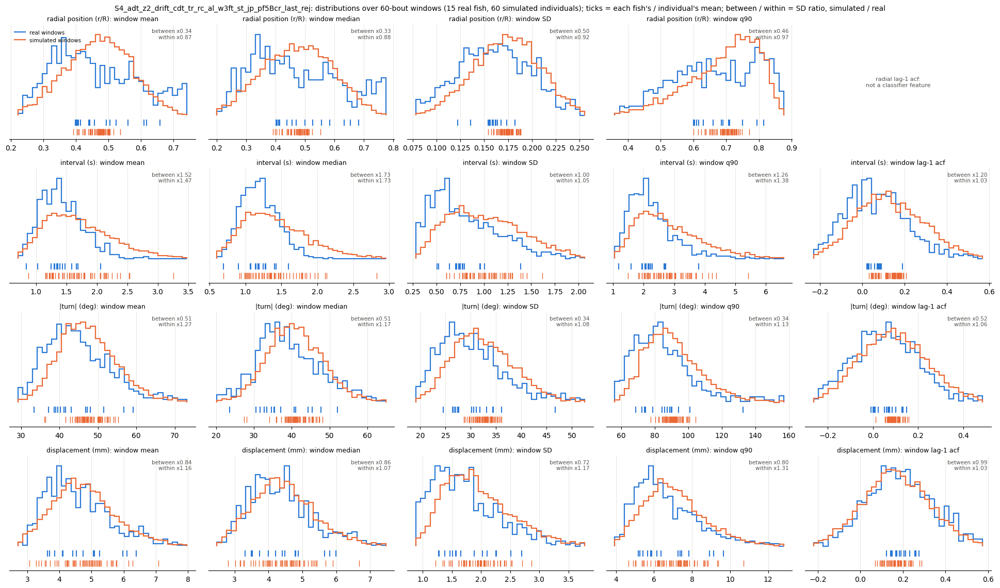


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 14.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.64     1.12  0.15  0.07   3.0   3.0                  22.3 +/- 0.9  23.1 +/- 0.9
d2s3.5    3.03     2.28  2.64  2.76  11.0   9.0                  17.4 +/- 0.9  21.5 +/- 1.1
d4s3.5    1.80     1.17  4.68  3.09  19.0   7.0                  18.7 +/- 1.7  19.0 +/- 0.7
d6s3.5    2.11     1.58  4.62  3.37  13.0   9.0                  16.7 +/- 1.3  19.2 +/- 0.9
d8s3.5    2.22     1.99  4.97  2.92  11.0   7.0                  16.3 +/- 1.0  18

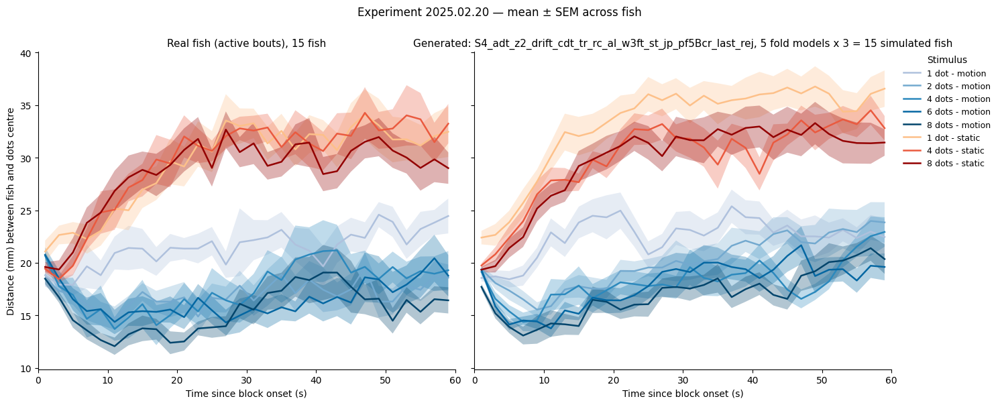


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

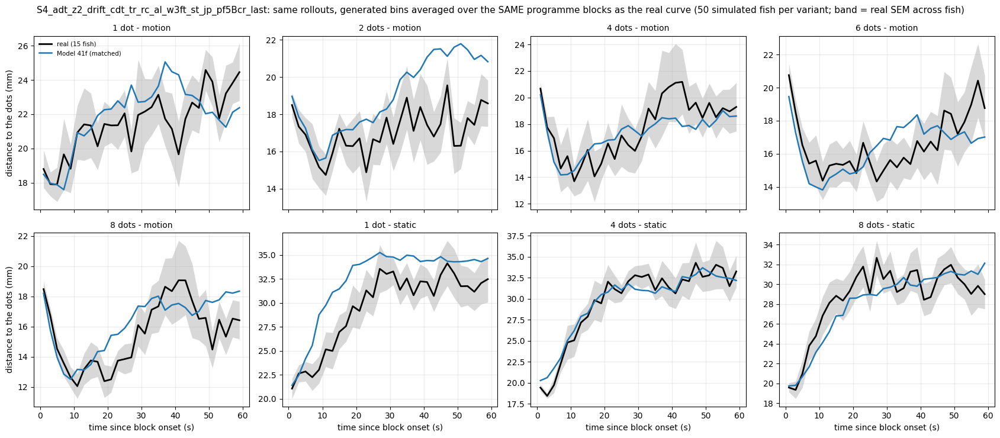


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_jp_pf5Bcr_last                  
           plateau   null attraction                                             plateau   null attraction
cond_label                                                                                                
d1s3.5       22.41  23.57       1.16                                               24.08  23.82      -0.25
d2s3.5       17.39  23.58       6.19                                               21.20  23.59       2.39
d4s3.5       18.74  23.93       5.19                                               18.85  23.75       4.91
d6s3.5       16.69  23.12       6.43                                               17.80  24.02       6.21
d8s3.5       16.41

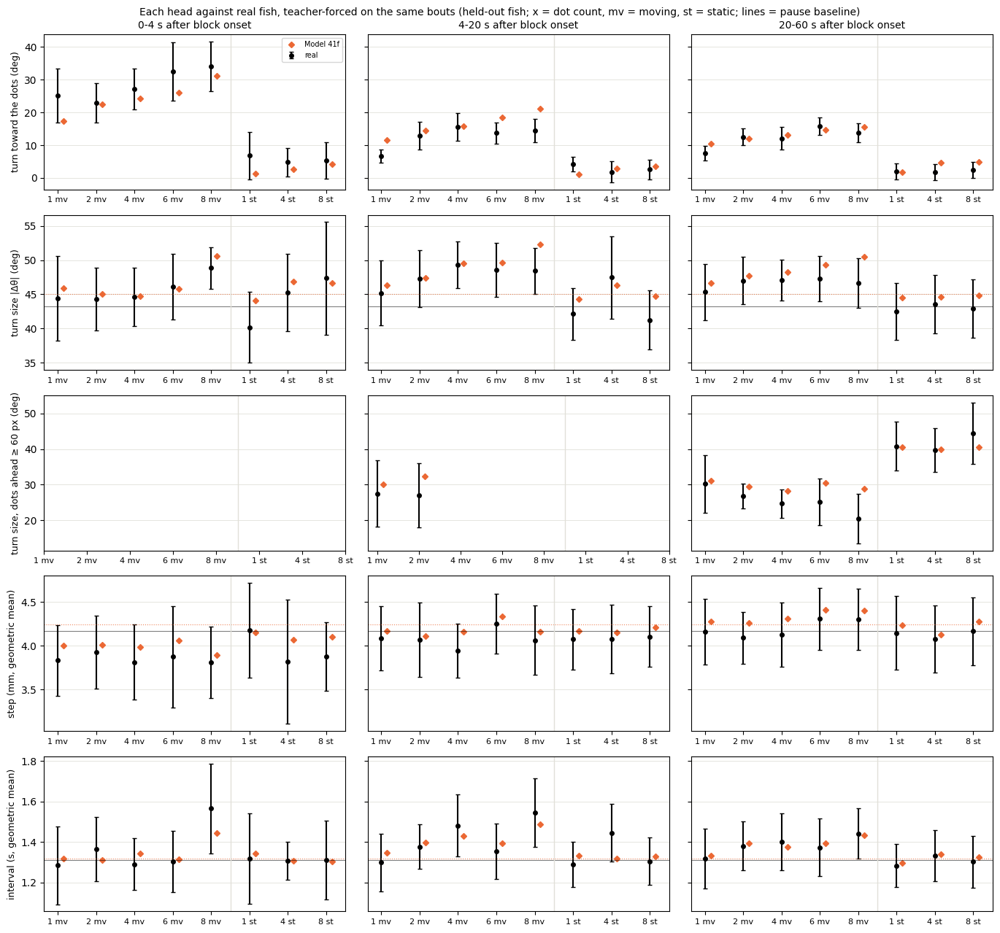

In [44]:
unit_eval.show('41f')

### M6, floor 2 px, seed 0


== held-out likelihood per head (bits per bout)
turn             7.665
displacement     4.498
interval         1.213
joint           13.376

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4xlo_adt_z2_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4xlo_adt_z2_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4xlo_adt_z2_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4xlo_adt_z2_cdt_tr_rc_al_w3ft.csv  (15 rows) in 1582s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4xlo_adt_z2_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                       8.3792
symbol_js                                           0.0116
dt_w1    

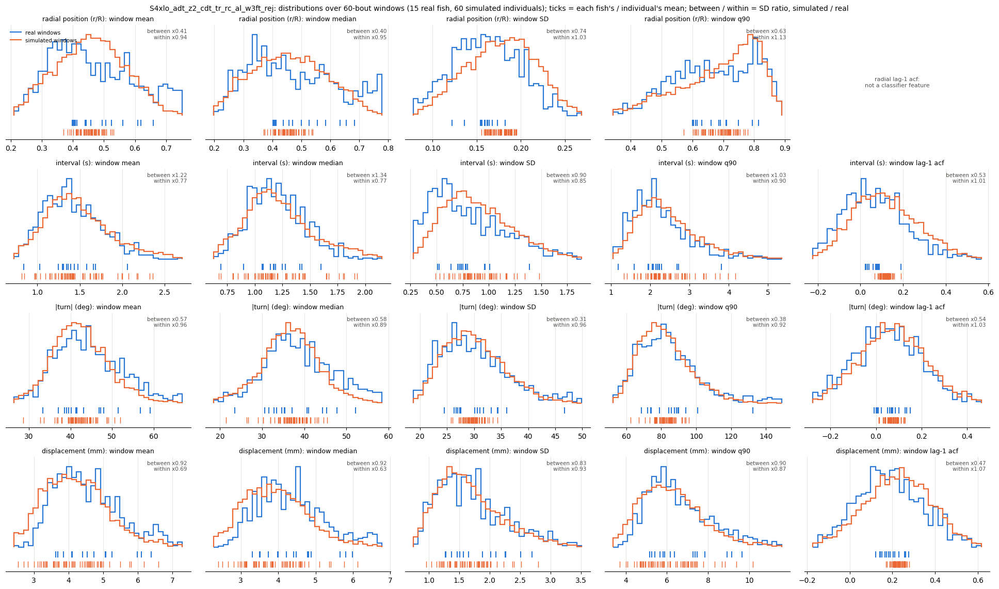


== distance to the dots across the block
  S4xlo_adt_z2_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 10.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.64     1.11  0.15  1.91   3.0   7.0                  22.3 +/- 0.9  20.6 +/- 0.9
d2s3.5    1.42     1.08  2.64  3.63  11.0   9.0                  17.4 +/- 0.9  18.9 +/- 0.8
d4s3.5    1.50     0.86  4.68  4.99  19.0   9.0                  18.7 +/- 1.7  17.6 +/- 0.7
d6s3.5    0.99     0.68  4.62  3.62  13.0   9.0                  16.7 +/- 1.3  16.5 +/- 0.6
d8s3.5    1.65     1.62  4.97  2.14  11.0   9.0                  16.3 +/- 1.0  17.2 +/- 0.6
d1s0      

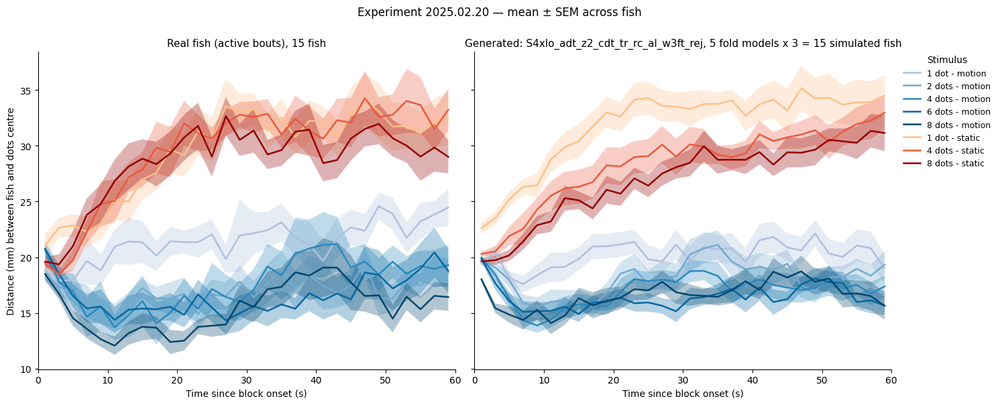


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

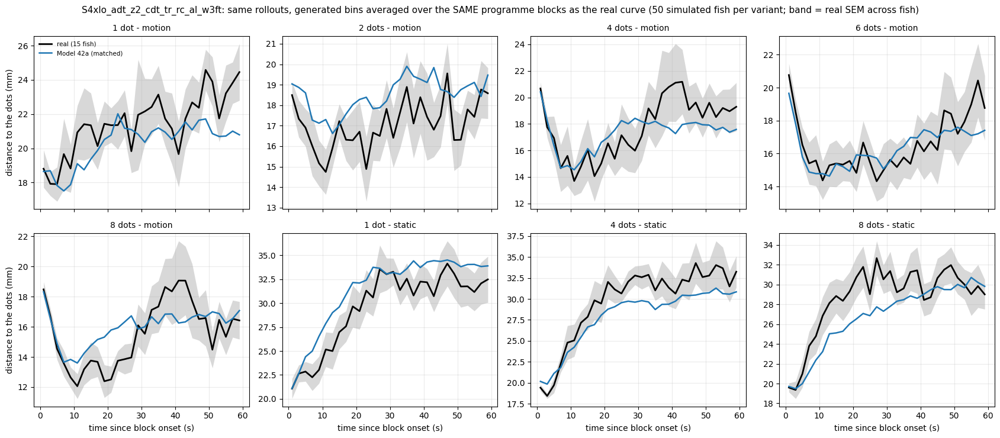


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4xlo_adt_z2_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                        plateau   null attraction
cond_label                                                                           
d1s3.5       22.41  23.57       1.16                          21.49  22.33       0.84
d2s3.5       17.39  23.58       6.19                          18.54  22.03       3.49
d4s3.5       18.74  23.93       5.19                          17.84  21.99       4.15
d6s3.5       16.69  23.12       6.43                          16.72  22.02       5.30
d8s3.5       16.41  23.36       6.94                          16.66  22.18       5.52

== turn toward the moving dots by dot count
           real  S4xlo_adt_z2_cdt_

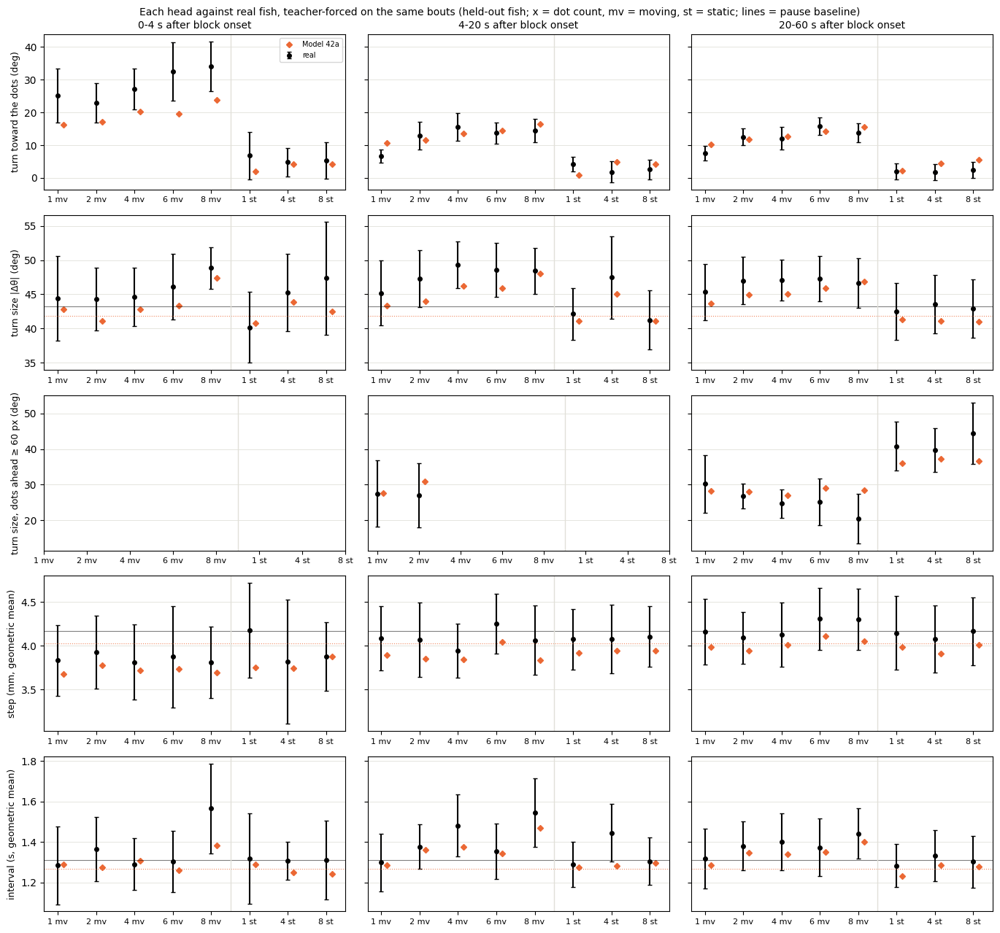

In [45]:
unit_eval.show('42a')

### M6, floor 2 px, seed 101


== held-out likelihood per head (bits per bout)
turn             7.665
displacement     4.496
interval         1.218
joint           13.379

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4xlo_adt_z2_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4xlo_adt_z2_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4xlo_adt_z2_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4xlo_adt_z2_cdt_tr_rc_al_w3ft.csv  (15 rows) in 1319s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4xlo_adt_z2_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                       8.2723
symbol_js                                           0.0123
dt_w1    

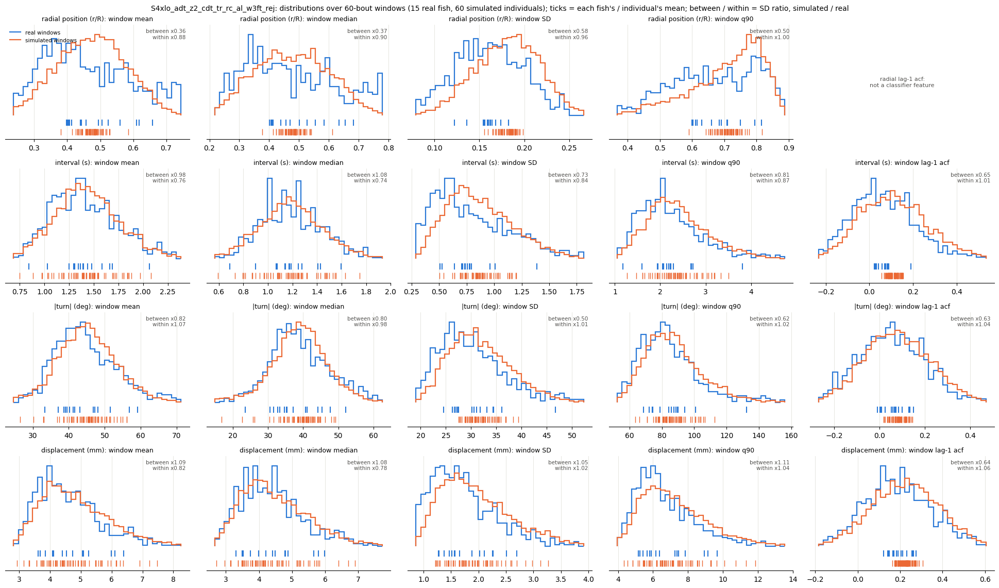


== distance to the dots across the block
  S4xlo_adt_z2_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 10.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.73     1.87  0.15  0.63   3.0   5.0                  22.3 +/- 0.9  19.8 +/- 0.6
d2s3.5    1.82     1.39  2.64  1.85  11.0  11.0                  17.4 +/- 0.9  19.2 +/- 1.1
d4s3.5    2.00     1.16  4.68  3.37  19.0   7.0                  18.7 +/- 1.7  16.7 +/- 1.0
d6s3.5    1.14     0.83  4.62  3.54  13.0   9.0                  16.7 +/- 1.3  17.4 +/- 0.7
d8s3.5    1.67     1.44  4.97  3.52  11.0   9.0                  16.3 +/- 1.0  16.7 +/- 0.8
d1s0      

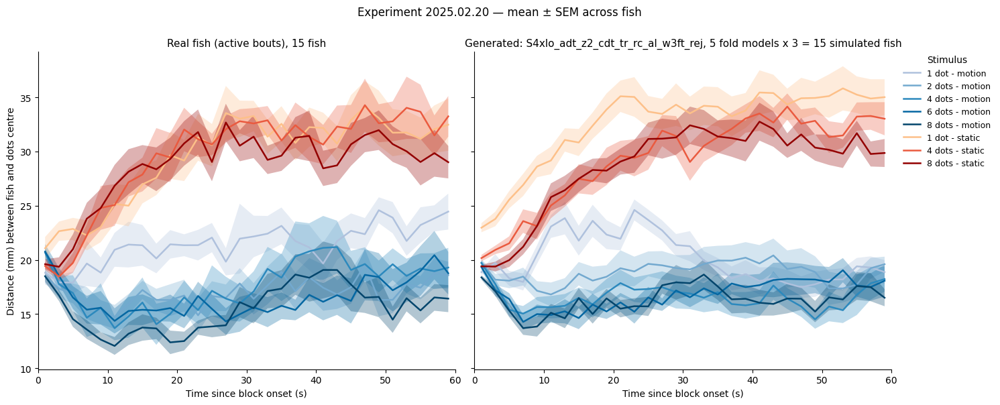


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

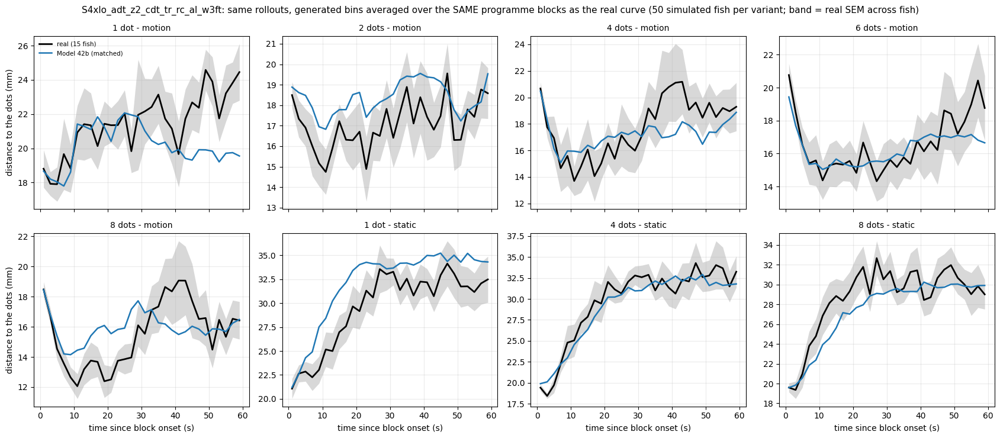


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4xlo_adt_z2_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                        plateau   null attraction
cond_label                                                                           
d1s3.5       22.41  23.57       1.16                          20.53  22.72       2.19
d2s3.5       17.39  23.58       6.19                          19.11  22.64       3.53
d4s3.5       18.74  23.93       5.19                          17.13  22.56       5.42
d6s3.5       16.69  23.12       6.43                          17.02  22.59       5.56
d8s3.5       16.41  23.36       6.94                          16.46  22.91       6.44

== turn toward the moving dots by dot count
           real  S4xlo_adt_z2_cdt_

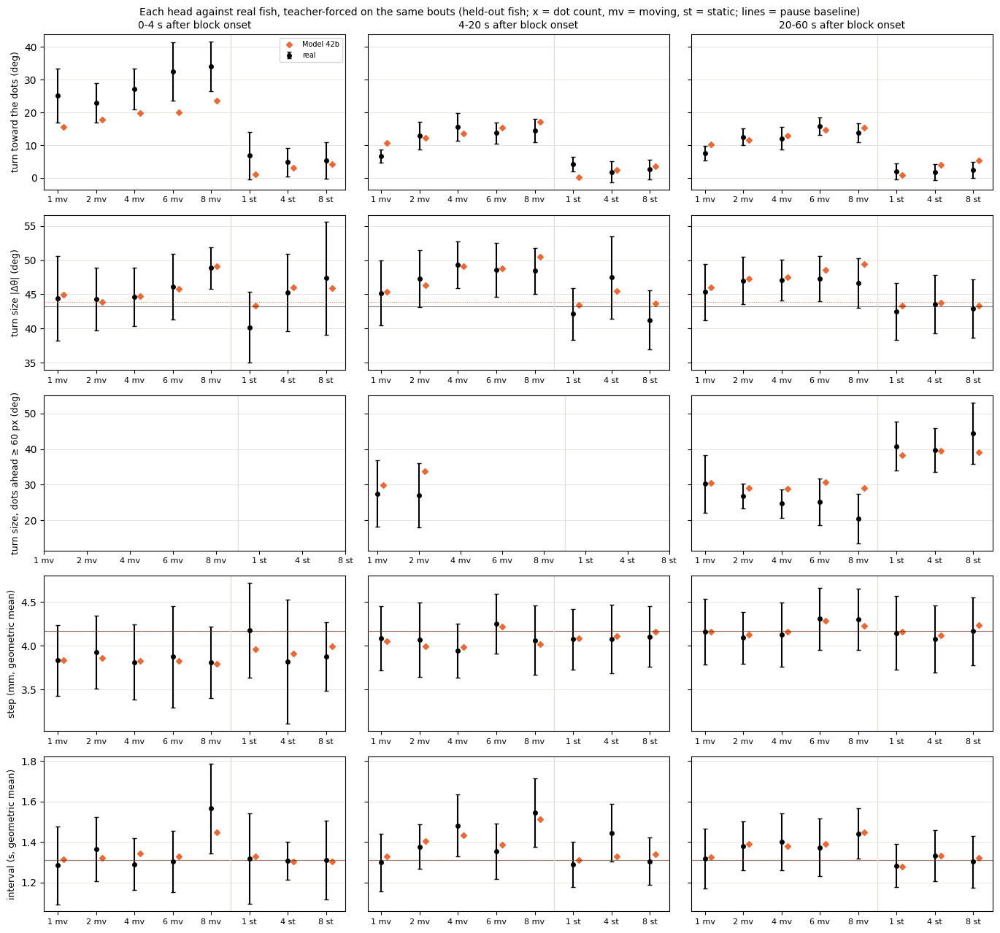

In [46]:
unit_eval.show('42b')

### D4, floor 2 px, seed 0


== held-out likelihood per head (bits per bout)
turn             7.620
displacement     4.517
interval         1.212
joint           13.348

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 411s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                               8.3362
symbol_js            

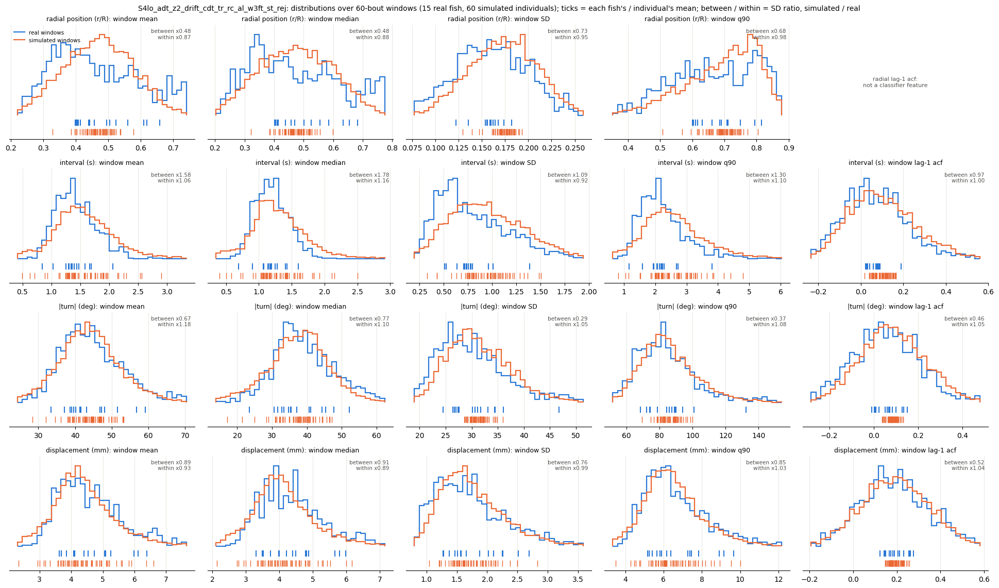


== distance to the dots across the block
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 10.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.73     1.14  0.15  0.59   3.0   5.0                  22.3 +/- 0.9  20.3 +/- 1.0
d2s3.5    1.10     0.89  2.64  2.39  11.0   9.0                  17.4 +/- 0.9  16.8 +/- 0.6
d4s3.5    1.59     0.90  4.68  4.14  19.0   7.0                  18.7 +/- 1.7  16.8 +/- 0.9
d6s3.5    1.06     0.77  4.62  3.98  13.0   9.0                  16.7 +/- 1.3  16.9 +/- 0.8
d8s3.5    1.21     0.88  4.97  3.92  11.0  13.0                  16.3 +/- 1.0  15.6 +/- 0.7
d1

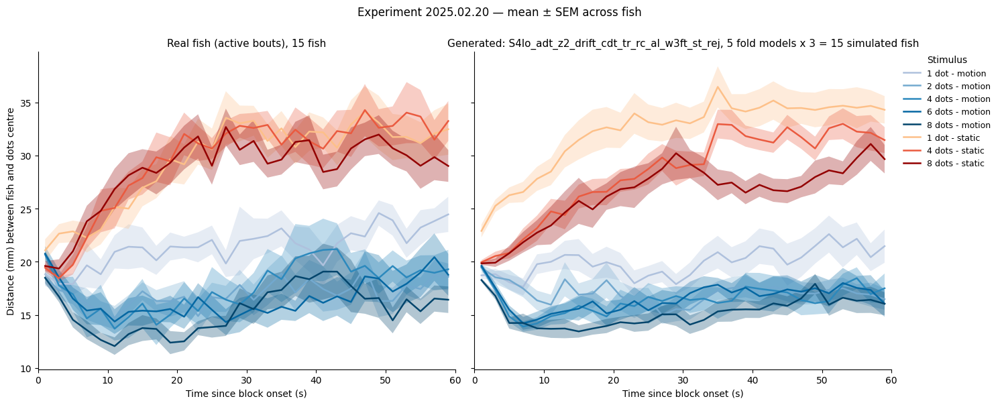


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

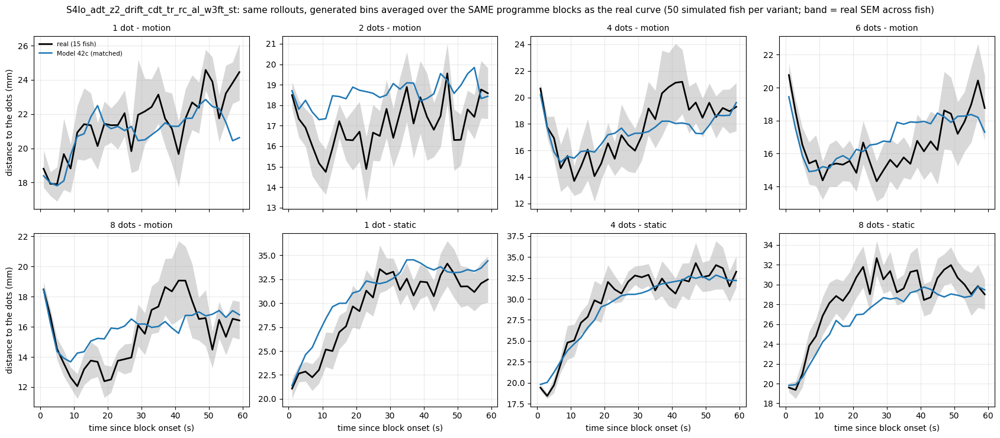


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                                plateau   null attraction
cond_label                                                                                   
d1s3.5       22.41  23.57       1.16                                  21.49  22.67       1.18
d2s3.5       17.39  23.58       6.19                                  18.49  22.54       4.05
d4s3.5       18.74  23.93       5.19                                  17.87  22.28       4.42
d6s3.5       16.69  23.12       6.43                                  17.81  22.50       4.69
d8s3.5       16.41  23.36       6.94                                  16.17  22.44       6.27

== turn toward

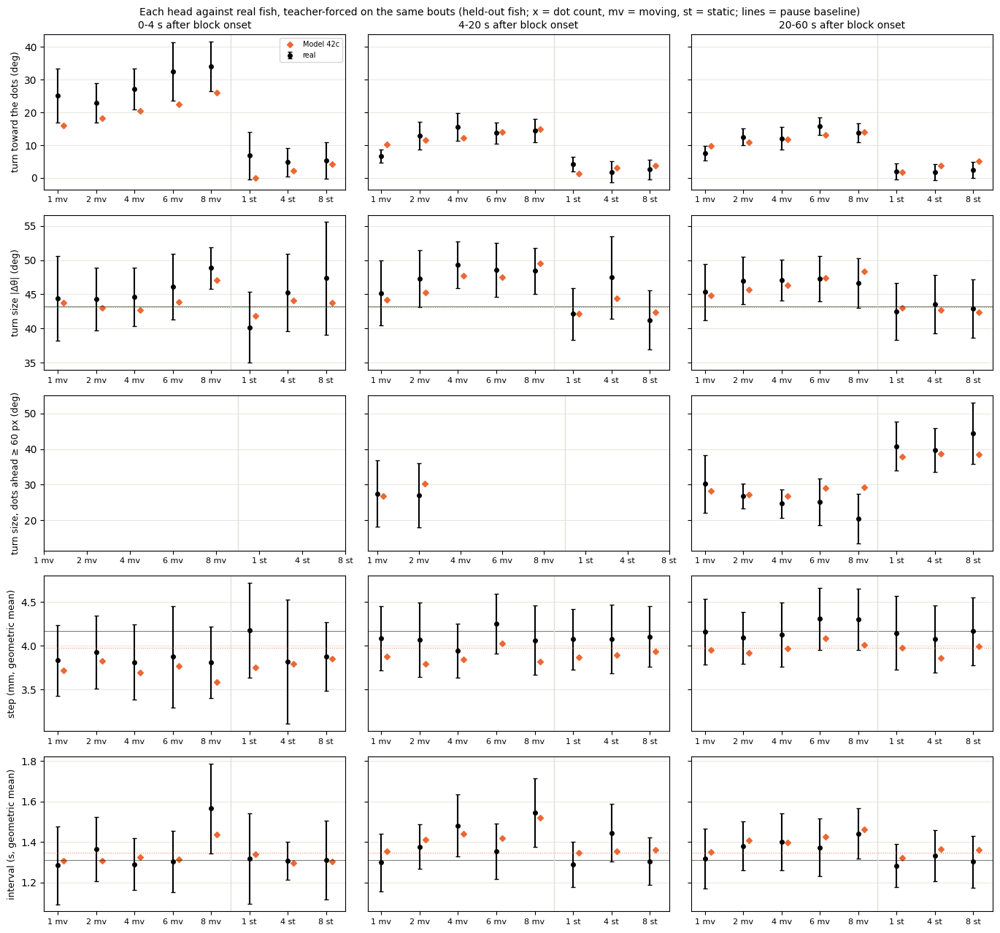

In [47]:
unit_eval.show('42c')

### D4, floor 2 px, seed 101


== held-out likelihood per head (bits per bout)


turn             7.632
displacement     4.515
interval         1.205
joint           13.352

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 406s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                               8.5390
symbol_js                                                   0.0137
dt

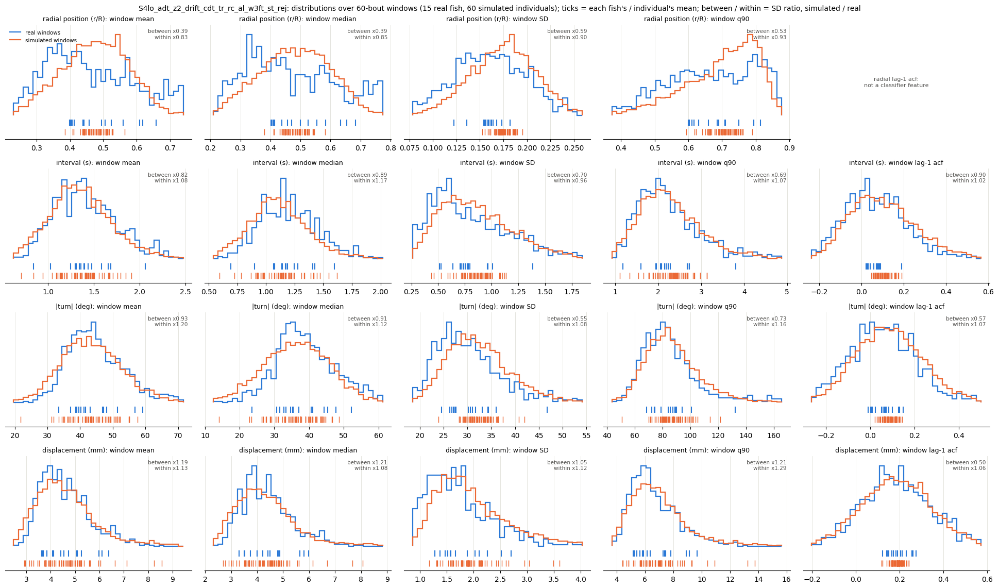


== distance to the dots across the block
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 11.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.20     0.81  0.15  0.24   3.0   5.0                  22.3 +/- 0.9  21.9 +/- 1.0
d2s3.5    2.36     1.76  2.64  2.88  11.0   9.0                  17.4 +/- 0.9  20.2 +/- 0.9
d4s3.5    2.00     1.14  4.68  3.23  19.0   9.0                  18.7 +/- 1.7  18.6 +/- 1.0
d6s3.5    1.53     1.06  4.62   3.4  13.0   9.0                  16.7 +/- 1.3  18.4 +/- 1.0
d8s3.5    1.81     1.64  4.97   2.8  11.0   9.0                  16.3 +/- 1.0  16.7 +/- 0.7
d1

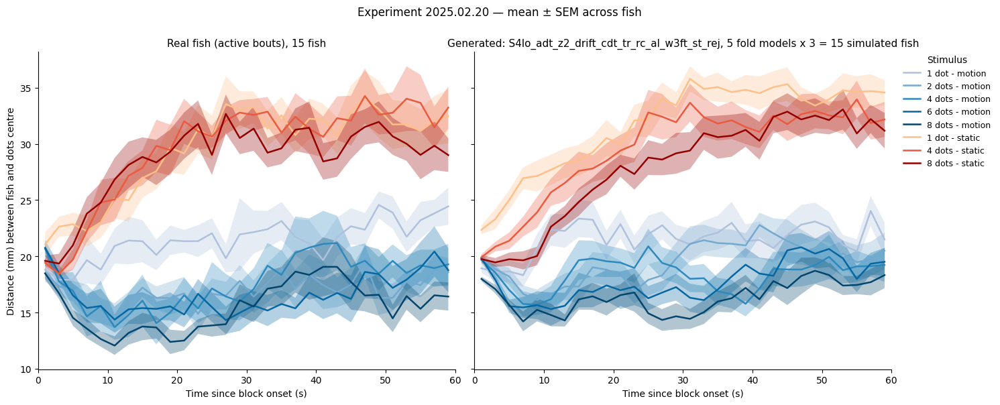


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

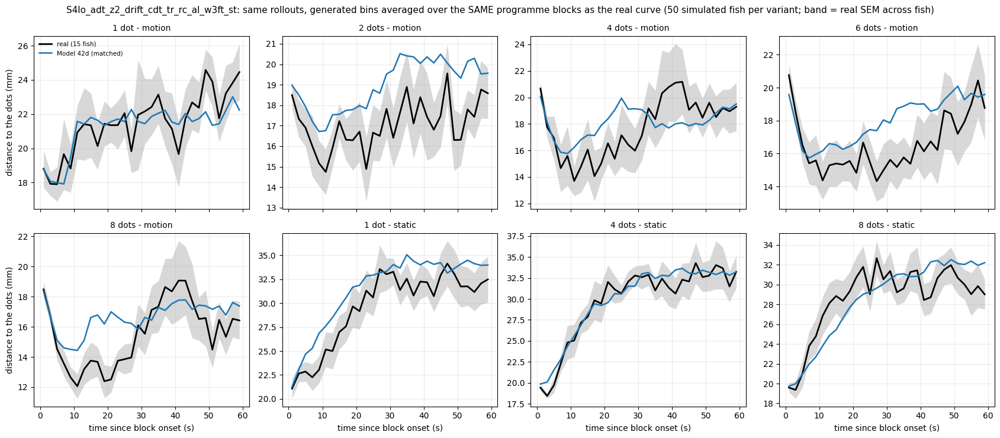


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                                plateau   null attraction
cond_label                                                                                   
d1s3.5       22.41  23.57       1.16                                  21.51  23.32       1.81
d2s3.5       17.39  23.58       6.19                                  19.54  22.88       3.35
d4s3.5       18.74  23.93       5.19                                  19.30  22.79       3.49
d6s3.5       16.69  23.12       6.43                                  18.19  23.22       5.03
d8s3.5       16.41  23.36       6.94                                  17.27  22.65       5.37

== turn toward

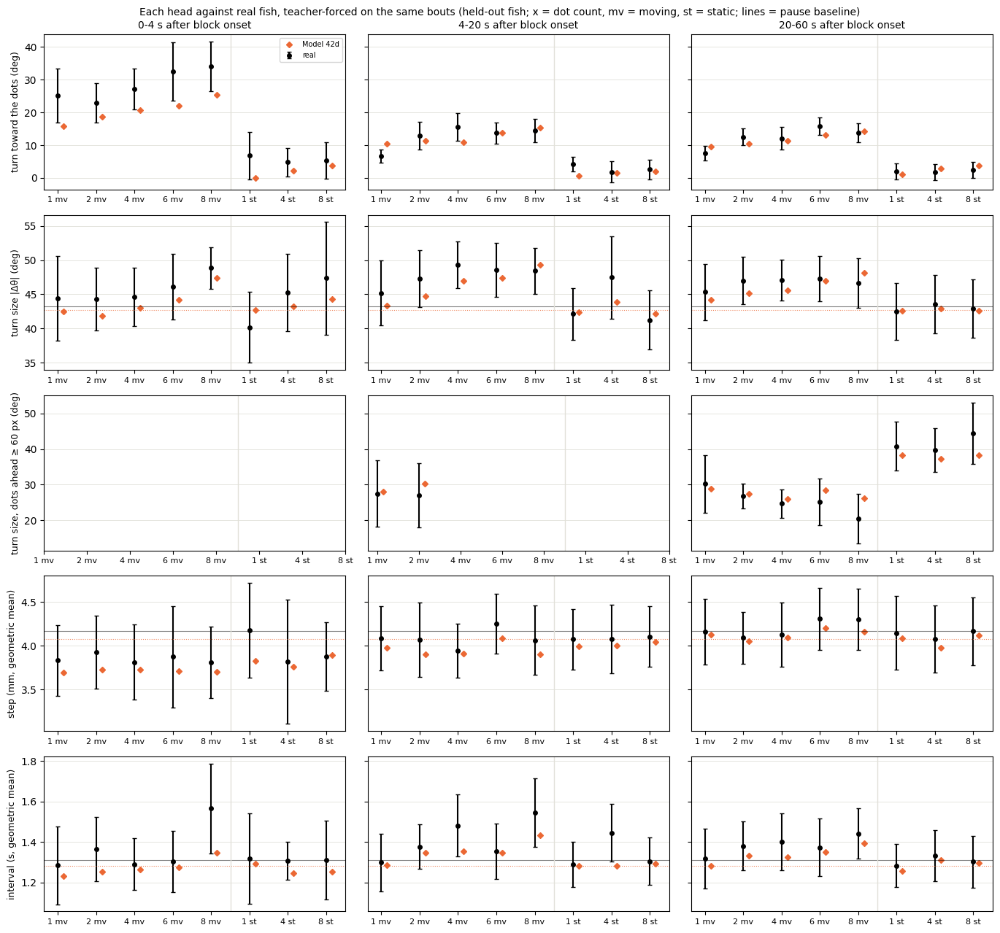

In [48]:
unit_eval.show('42d')

### F, floor 2 px, seed 0


== held-out likelihood per head (bits per bout)
turn             7.620
displacement     4.517
interval         1.212
joint           13.349

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last'] -> writing panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv / c2st_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv  (15 rows) in 1188s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_rej
abs_dtheta_w1              

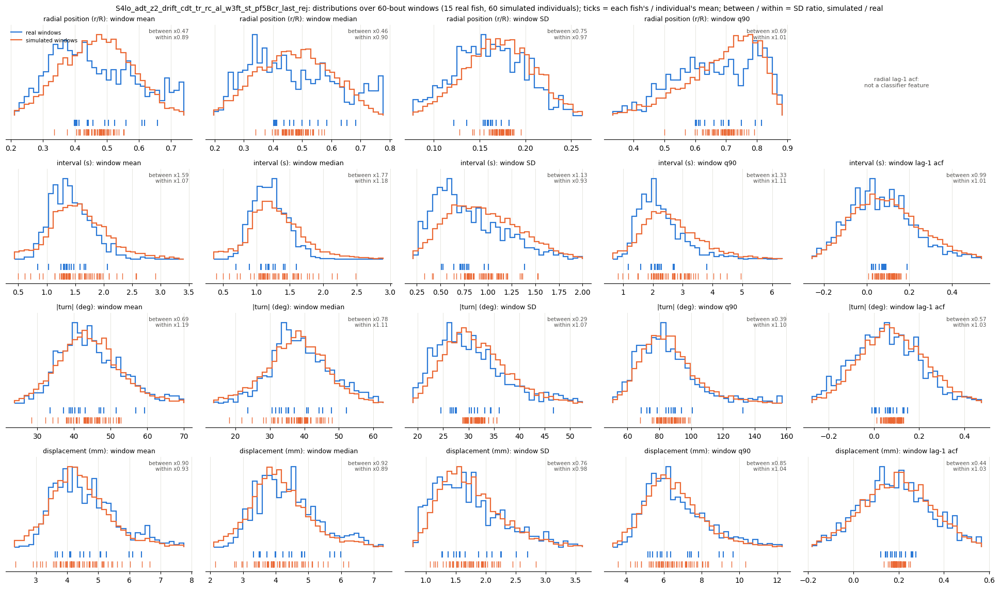


== distance to the dots across the block
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.59     1.03  0.15  0.54   3.0   5.0                  22.3 +/- 0.9  21.2 +/- 1.0
d2s3.5    1.09     0.88  2.64  3.45  11.0  19.0                  17.4 +/- 0.9  18.1 +/- 0.9
d4s3.5    2.08     1.13  4.68  5.31  19.0   9.0                  18.7 +/- 1.7  16.1 +/- 0.6
d6s3.5    1.49     1.05  4.62  5.05  13.0  19.0                  16.7 +/- 1.3  15.3 +/- 0.8
d8s3.5    1.39     1.07  4.97   3.8  11.0   9.0                  16.3 +/- 1.0  15.

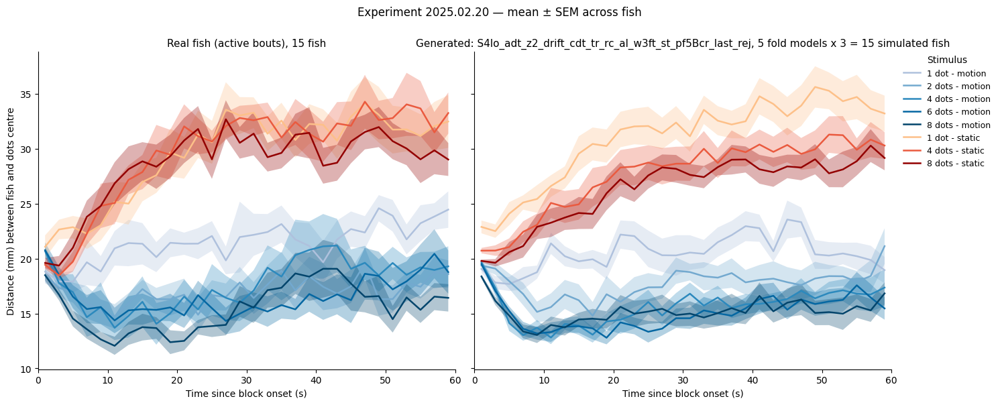


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

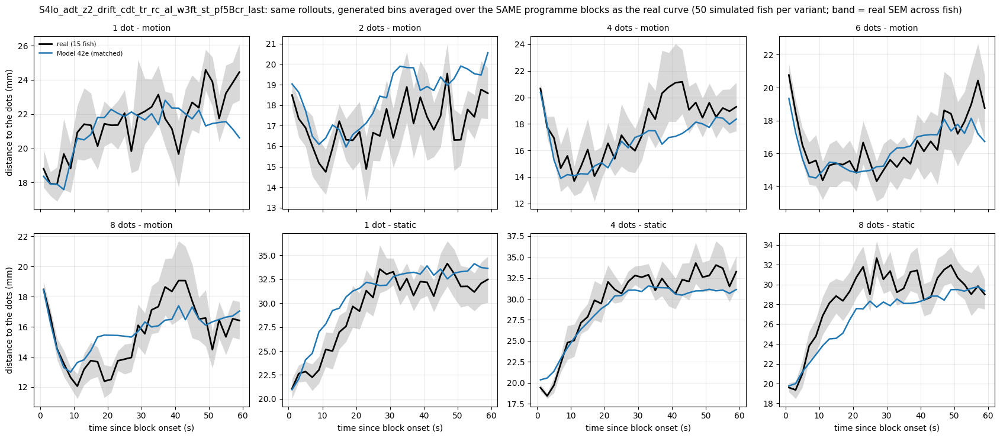


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last                  
           plateau   null attraction                                            plateau   null attraction
cond_label                                                                                               
d1s3.5       22.41  23.57       1.16                                              21.93  22.57       0.64
d2s3.5       17.39  23.58       6.19                                              18.30  22.58       4.27
d4s3.5       18.74  23.93       5.19                                              16.83  22.41       5.58
d6s3.5       16.69  23.12       6.43                                              16.31  22.33       6.02
d8s3.5       16.41  23.36

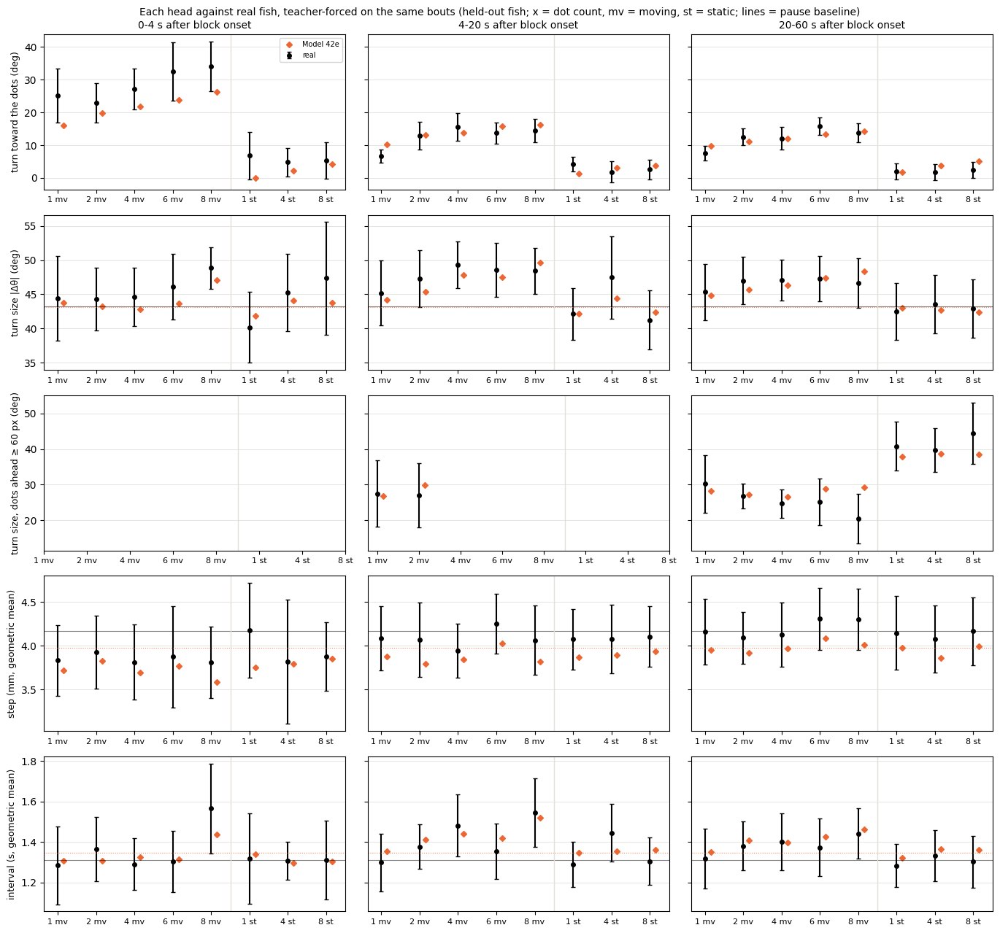

In [49]:
unit_eval.show('42e')

### F, floor 2 px, seed 101


== held-out likelihood per head (bits per bout)
turn             7.632
displacement     4.515
interval         1.205
joint           13.352

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last'] -> writing panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv / c2st_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv  (15 rows) in 1173s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_rej
abs_dtheta_w1              

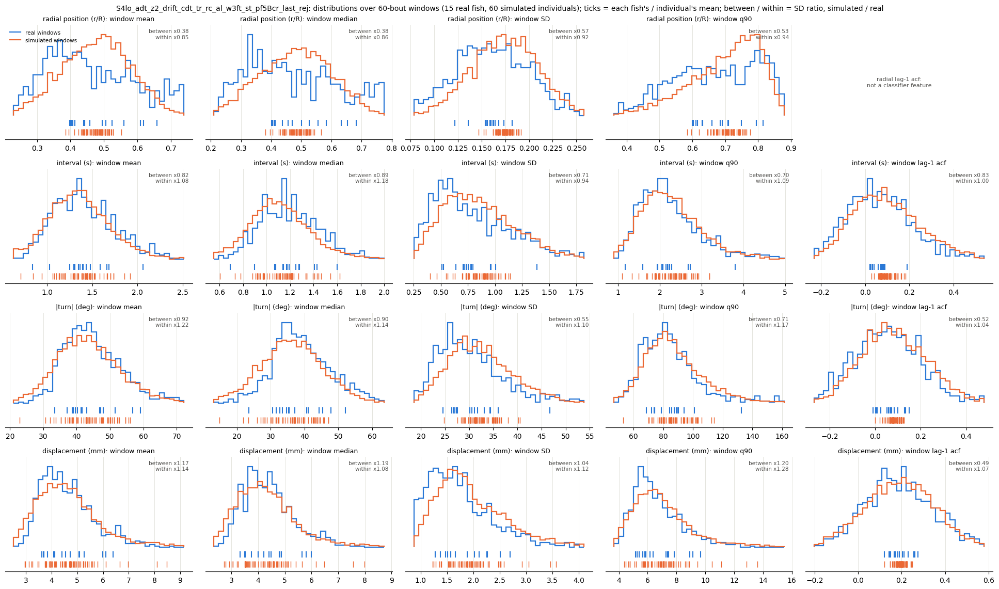


== distance to the dots across the block
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 11.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.67     1.15  0.15  0.83   3.0   5.0                  22.3 +/- 0.9  21.5 +/- 0.7
d2s3.5    2.04     1.60  2.64  3.57  11.0  11.0                  17.4 +/- 0.9  19.6 +/- 1.3
d4s3.5    1.31     0.77  4.68   3.1  19.0   9.0                  18.7 +/- 1.7  18.6 +/- 1.0
d6s3.5    1.26     0.93  4.62  4.17  13.0   9.0                  16.7 +/- 1.3  17.9 +/- 1.1
d8s3.5    1.34     1.18  4.97  3.23  11.0   7.0                  16.3 +/- 1.0  16.

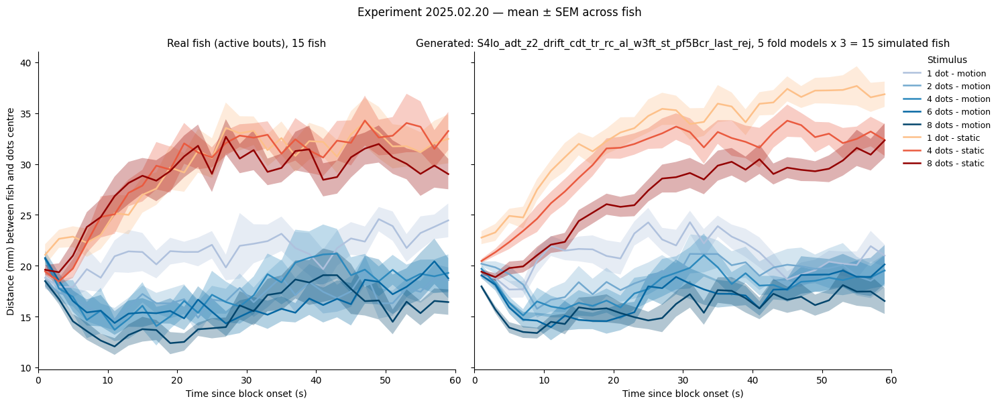


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

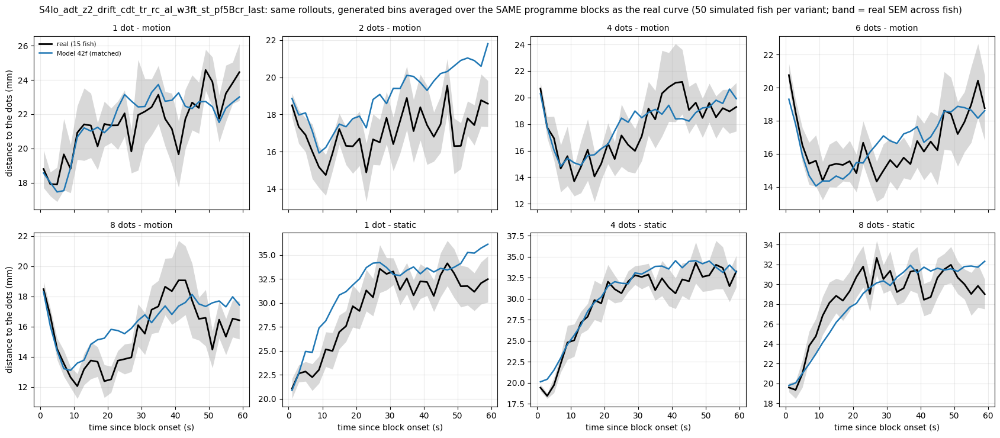


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last                  
           plateau   null attraction                                            plateau   null attraction
cond_label                                                                                               
d1s3.5       22.41  23.57       1.16                                              22.38  23.01       0.62
d2s3.5       17.39  23.58       6.19                                              20.02  22.99       2.97
d4s3.5       18.74  23.93       5.19                                              18.60  23.01       4.41
d6s3.5       16.69  23.12       6.43                                              17.30  23.15       5.85
d8s3.5       16.41  23.36

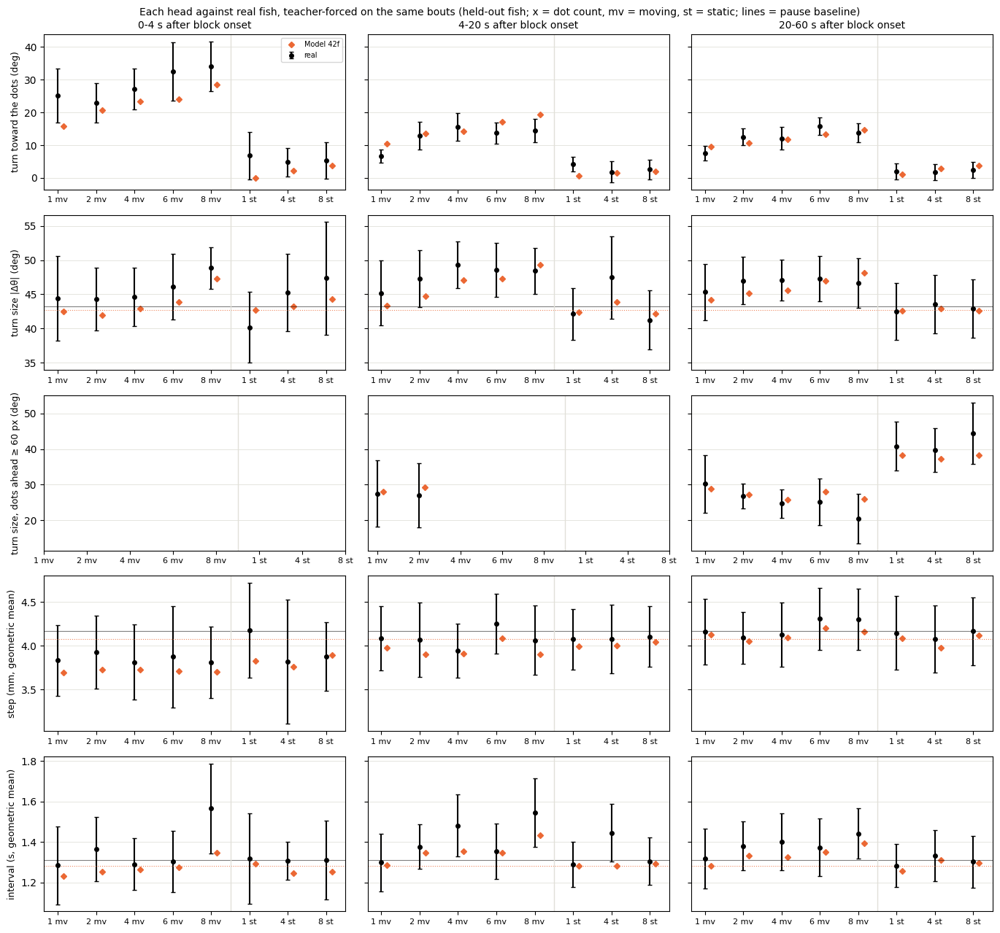

In [50]:
unit_eval.show('42f')